# Trabajo Práctico Final: Inteligencia Artificial 2026
## Etapa 1: Análisis Exploratorio (EDA), Partición y Modelo Baseline

**Docente:** Pablo Moreira  
**Dataset Asignado:** SQAC (Spanish Question Answering Corpus)

**Grupo Nombres**: (Anotar nombres) Junior Flores





## 1.1 Introducción y formulación del problema

El corpus **SQAC (Spanish Question Answering Corpus)** se plantea originalmente como una tarea de comprensión lectora extractiva: localizar una respuesta dentro de un párrafo de contexto.

En este notebook lo reformulamos como **selección de oraciones candidatas (*Answer Sentence Selection*)**:

1. Segmentamos cada párrafo (`context`) en oraciones.
2. Asociamos cada oración con la pregunta correspondiente.
3. Asignamos una etiqueta binaria según la posición de la respuesta en el párrafo:
   - **Clase 1 (relevante):** La oración contiene la respuesta textual esperada.
   - **Clase 0 (irrelevante):** La oración no contiene la respuesta.


### Tratamiento de columnas

- **`id`:** identificador de la pregunta; no se usa como característica textual.
- **`title`:** se conserva como dato descriptivo de procedencia, pero no forma parte del texto que recibe el modelo.
- **`context` y `question`:** aportan el contexto y la consulta; el contexto se divide en oraciones.
- **`answers['text']`:** texto de la respuesta anotada; se extrae al inspeccionar el dataset, pero la etiqueta implementada se determina mediante `answer_start`.
- **`answers['answer_start']`:** índice de caracteres donde comienza la respuesta en el párrafo. Se utiliza para asignar la etiqueta a la oración cuyo intervalo contiene esa posición.



# Librerías y Carga del Dataset Oficial

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score, precision_score, recall_score

from IPython.display import display

# Etapa 2
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
import html
import pandas as pd
from IPython.display import display, HTML


# Etapa 3
import time
from sklearn.naive_bayes import MultinomialNB, ComplementNB

# Etapa 3
%pip install -q "spacy==3.8.16"
!python -m spacy download es_core_news_md

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 MB 48.0 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


# Carga del Dataset

In [3]:
# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Carga del dataset SQAC oficial en español
print("Descargando SQAC desde Hugging Face...")
raw_dataset = load_dataset("PlanTL-GOB-ES/sqac")
print(raw_dataset)

Descargando SQAC desde Hugging Face...


README.md:   0%|          | 0.00/6.49k [00:00<?, ?B/s]

train.json: reconstructing file:   0%|          |  0.00B / 11.0MB            

train.json: downloading bytes:           |  0.00B            

dev.json: reconstructing file:   0%|          |  0.00B / 1.40MB            

dev.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['data'],
        num_rows: 1
    })
    validation: Dataset({
        features: ['data'],
        num_rows: 1
    })
    test: Dataset({
        features: ['data'],
        num_rows: 1
    })
})


### 1.1.1 Descripción de Variables del Dataset Crudo

El dataset descargado presenta una estructura jerárquica tipo JSON nativa del formato SQuAD.
A continuacion analizamos la estructura de los datos que se compone el SQAC.

Se componen de los siguiente campos:

| Variable | Tipo de Dato (Python) | Descripción |
| :--- | :--- | :--- |
| **`id`** | `str` | Identificador único alfanumérico de la pregunta. |
| **`title`** | `str` | Título o tema del artículo de Wikipedia de donde proviene el texto. |
| **`context`** | `str` | Párrafo de texto completo que sirve como contexto. |
| **`question`** | `str` | La pregunta formulada en lenguaje natural. |
| **`answers`** | `dict` | Diccionario que anida la respuesta real y su posición. |
| **`text`** (dentro de answers) | `list[str]` | Una lista que contiene el string de la respuesta exacta extraída del contexto. |
| **`answer_start`** (dentro de answers)| `list[int]` | Una lista con el índice numérico del carácter donde arranca la respuesta. |

---
**A continuación, se mostrará en una celda los tipos de datos y se comprobarán la existencia de los valores nulos.**

## Inspección y Extracción de Datos Crudos

In [4]:
registros_crudos = []

# Iteramos sobre la estructura anidada original del dataset de Hugging Face
for entry_wrapper in raw_dataset['train']:
    for doc in entry_wrapper['data']:
        titulo = doc.get('title', '')
        for para in doc['paragraphs']:
            contexto = para['context']
            for qa in para['qas']:
                # Extraemos de forma segura los valores dentro del diccionario 'answers'
                ans_text = qa['answers'][0]['text'] if qa.get('answers') and len(qa['answers']) > 0 else None
                ans_start = qa['answers'][0]['answer_start'] if qa.get('answers') and len(qa['answers']) > 0 else None

                registros_crudos.append({
                    'id': qa['id'],
                    'title': titulo,
                    'context': contexto,
                    'question': qa['question'],
                    'text': ans_text,
                    'answer_start': ans_start
                })

# Convertimos a DataFrame para el diagnóstico
df_crudo = pd.DataFrame(registros_crudos)

print("--- Tipos de Datos Reales (Dataset Crudo) ---")
df_crudo.info()

print("\n--- Conteo de Valores Nulos (Dataset Crudo) ---")
print(df_crudo.isnull().sum())

--- Tipos de Datos Reales (Dataset Crudo) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15036 entries, 0 to 15035
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            15036 non-null  object
 1   title         15036 non-null  object
 2   context       15036 non-null  object
 3   question      15036 non-null  object
 4   text          15036 non-null  object
 5   answer_start  15036 non-null  int64 
dtypes: int64(1), object(5)
memory usage: 704.9+ KB

--- Conteo de Valores Nulos (Dataset Crudo) ---
id              0
title           0
context         0
question        0
text            0
answer_start    0
dtype: int64


La inspección de df_crudo no encuentra valores nulos en las columnas extraídas. Esto se debe a que la base de datos SQAC esta estructurado de tal forma para el entrenamiento de algoritmos, es decir, ya viene "limpia" para que a ningún ejemplo le falte la información necesaria (contexto, pregunta y respuesta) para que el modelo pueda aprender correctamente.

Este resultado se refiere al conjunto `train` crudo inspeccionado en esta celda y a las columnas que extrajimos.

## 1.2 Estrategia y justificación de la partición (Train, Dev y Test)

Utilizamos las particiones oficiales de SQAC para mantener la separación proporcionada por el dataset, en lugar de generar una partición aleatoria propia.

- `train`: conjunto utilizado para entrenar los modelos.
- `validation`, que denominamos `Dev`: conjunto utilizado para evaluar y comparar los modelos durante los experimentos y tomar decisiones sobre su desarrollo.
- `test`: conjunto reservado para la evaluación final, sin utilizarlo para entrenar modelos ni seleccionar configuraciones.

Esta separación permite utilizar Dev como referencia durante el desarrollo y reservar Test para obtener una evaluación final que no haya intervenido en las decisiones tomadas durante los experimentos.

## 1.3 Extracción de Pares Pregunta-Oración

Transformamos las muestras crudas descomponiendo los párrafos en oraciones y contrastándolas contra la pregunta, **sin aplicar ningún submuestreo previo (*negative downsampling*)**, a fin de observar y diagnosticar empíricamente la naturaleza estadística real del corpus.

A continuación, aplicamos este procedimiento a los tres conjuntos (`Train`, `Dev` y `Test`):

### ¿Cómo convertimos los párrafos en oraciones y asignamos las etiquetas?

El dataset original contiene párrafos completos, preguntas y la ubicación de la respuesta dentro del texto. Para convertirlo en un problema de clasificación, necesitamos comparar cada pregunta con las oraciones de su párrafo.

**Primero, segmentamos el contexto.** Utilizamos una expresión regular que busca signos de cierre (`.`, `?` o `!`) seguidos de un espacio y de un carácter compatible con el comienzo de otra oración. El patrón contempla algunas abreviaturas e iniciales frecuentes para evitar ciertos cortes incorrectos. Es una solución práctica, aunque no garantiza una segmentación lingüísticamente perfecta.

**Después, asignamos una etiqueta a cada par pregunta-oración.** El dataset proporciona `answer_start`, que indica la posición inicial de la respuesta dentro del contexto. Si esa posición cae dentro de los límites de una oración, etiquetamos el par con `1` (relevante). Si no cae dentro de ella, lo etiquetamos con `0` (no relevante).

Por ejemplo, si la respuesta comienza en el carácter 120 del contexto, la oración que contiene esa posición será positiva. Las demás oraciones del mismo contexto se convertirán en ejemplos negativos para esa pregunta.

Esta regla utiliza la posición de la respuesta anotada en el dataset; no decide si una oración es relevante comparando su significado con la pregunta. Por eso, también debemos comprobar qué ocurre cuando la segmentación no encuentra una oración que contenga `answer_start`.

El objetivo de las verificaciones siguientes es comprobar cómo queda el dataset generado y detectar posibles limitaciones del procedimiento antes de entrenar los modelos.

In [5]:
# Expresión regular que corta en (. ? !) seguidos de espacio y mayúscula/apertura,
# pero NO corta detrás de abreviaturas comunes (Dr., Sr., EE. UU., etc.) ni iniciales (A., J.)
PATRON_ORACIONES = re.compile(
    r'(?<!\bDr\.)(?<!\bSr\.)(?<!\bSra\.)(?<!\bGral\.)(?<!\bAv\.)(?<!\bCap\.)'
    r'(?<!\bart\.)(?<!\bnúm\.)(?<!\bpág\.)(?<!\betc\.)(?<!\bEE\.)(?<!\bUU\.)'
    r'(?<!\b[A-ZÁÉÍÓÚÑ]\.)(?<!\b[a-z]\.)'
    r'(?<=[.?!])\s+(?=[A-ZÁÉÍÓÚÑ¿¡"«(\d])'
)

def segmentar_oraciones_con_indices(texto):
    """
    Divide un párrafo en oraciones devolviendo una lista de tuplas:
    (texto_oracion, indice_inicio_char, indice_fin_char)
    """
    oraciones_con_spans = []
    inicio = 0
    for match in PATRON_ORACIONES.finditer(texto):
        fin = match.start()
        frag = texto[inicio:fin].strip()
        if len(frag) > 3:
            oraciones_con_spans.append((frag, inicio, fin))
        inicio = match.end()

    ultimo_frag = texto[inicio:].strip()
    if len(ultimo_frag) > 3:
        oraciones_con_spans.append((ultimo_frag, inicio, len(texto)))

    return oraciones_con_spans

def construir_pares_desde_split(dataset_split, max_docs=None):
    """
    Recorre los documentos de un split y arma los pares (Pregunta, Oración),
    usando 'answer_start' para etiquetar con 1 únicamente la oración exacta de la respuesta.
    """
    registros = []

    for entry_wrapper in dataset_split:
        docs = entry_wrapper['data']
        if max_docs is not None:
            docs = docs[:max_docs]

        for doc in docs:
            for para in doc['paragraphs']:
                contexto = para['context']
                oraciones_spans = segmentar_oraciones_con_indices(contexto)
                num_oraciones = len(oraciones_spans)

                for qa in para['qas']:
                    pregunta = qa["question"]
                    respuestas_list = qa.get("answers", [])
                    if not respuestas_list:
                        continue

                    ans_start = respuestas_list[0]["answer_start"]

                    for oracion, ini_char, fin_char in oraciones_spans:
                        # Es clase 1 SOLO si el índice exacto answer_start cae dentro de esta oración
                        es_positiva = 1 if (ini_char <= ans_start < fin_char) else 0
                        registros.append({
                            "pregunta": pregunta,
                            "oracion": oracion,
                            "texto_combinado": f"{pregunta} [SEP] {oracion}",
                            "label": es_positiva,
                            "len_pregunta": len(pregunta.split()),
                            "len_oracion": len(oracion.split()),
                            "num_oraciones_contexto": num_oraciones
                        })
    return pd.DataFrame(registros)

print("Procesando pares de Train con answer_start...")
df_pares = construir_pares_desde_split(raw_dataset["train"])

print("Procesando pares de Dev (Validation) con answer_start...")
df_pares_dev = construir_pares_desde_split(raw_dataset["validation"])

print("Procesando pares de Test (Blindado) con answer_start...")
df_pares_test = construir_pares_desde_split(raw_dataset["test"])

tabla_proporciones = pd.DataFrame({
    "Conjunto": ["Train", "Dev (Validation)", "Test"],
    "Total Muestras": [len(df_pares), len(df_pares_dev), len(df_pares_test)],
    "Positivos (1)": [df_pares["label"].sum(), df_pares_dev["label"].sum(), df_pares_test["label"].sum()],
    "% Positivos (1)": [f"{df_pares['label'].mean():.2%}", f"{df_pares_dev['label'].mean():.2%}", f"{df_pares_test['label'].mean():.2%}"],
    "% Negativos (0)": [f"{(1 - df_pares['label'].mean()):.2%}", f"{(1 - df_pares_dev['label'].mean()):.2%}", f"{(1 - df_pares_test['label'].mean()):.2%}"]
})

print("\n--- Verificación de Proporcionalidad entre Conjuntos (Pauta 4.1.2) ---")
display(tabla_proporciones)
df_pares.head(3)

Procesando pares de Train con answer_start...
Procesando pares de Dev (Validation) con answer_start...
Procesando pares de Test (Blindado) con answer_start...

--- Verificación de Proporcionalidad entre Conjuntos (Pauta 4.1.2) ---


,Conjunto,Total Muestras,Positivos (1),% Positivos (1),% Negativos (0)
0,Train,113647,15036,13.23%,86.77%
1,Dev (Validation),14871,1864,12.53%,87.47%
2,Test,13192,1910,14.48%,85.52%


,pregunta,oracion,texto_combinado,label,len_pregunta,len_oracion,num_oraciones_contexto
0,¿Qué influencia convirtió Japón en una nación ...,"La historia de Japón (日本の歴史 o 日本史, Nihon no re...",¿Qué influencia convirtió Japón en una nación ...,0,8,22,4
1,¿Qué influencia convirtió Japón en una nación ...,Algunos de estos hechos aparecen aislados e in...,¿Qué influencia convirtió Japón en una nación ...,0,8,47,4
2,¿Qué influencia convirtió Japón en una nación ...,"Asimismo, otra de las influencias foráneas fue...",¿Qué influencia convirtió Japón en una nación ...,1,8,36,4


### Diagnóstico de etiquetas: `answer_start` vs. respuesta completa

El etiquetado actual identifica como positiva la oración que contiene el índice `answer_start`. Para verificar la consistencia de esta estrategia, se realiza una comparación adicional: se comprueba si la oración identificada contiene también el final de la respuesta textual anotada.


In [6]:
def diagnosticar_etiquetado(dataset_split, nombre, max_docs=None):
    casos_evaluados = 0
    casos_con_diferencia = 0
    respuestas_que_cruzan_limite = 0
    respuestas_sin_oracion_inicio = 0
    ejemplos_diferentes = []

    for entry_wrapper in dataset_split:
        docs = entry_wrapper["data"]

        if max_docs is not None:
            docs = docs[:max_docs]

        for doc in docs:
            for para in doc["paragraphs"]:
                contexto = para["context"]
                oraciones_spans = segmentar_oraciones_con_indices(contexto)

                for qa in para["qas"]:
                    respuestas_list = qa.get("answers", [])

                    if not respuestas_list:
                        continue

                    respuesta = respuestas_list[0]
                    ans_start = respuesta["answer_start"]
                    texto_respuesta = respuesta["text"]
                    ans_end = ans_start + len(texto_respuesta)

                    casos_evaluados += 1

                    # Etiquetado actual: la oración contiene answer_start.
                    indice_actual = next(
                        (
                            i for i, (_, inicio, fin) in enumerate(oraciones_spans)
                            if inicio <= ans_start < fin
                        ),
                        None
                    )

                    # Diagnóstico alternativo: la oración contiene toda la respuesta.
                    indice_completo = next(
                        (
                            i for i, (_, inicio, fin) in enumerate(oraciones_spans)
                            if inicio <= ans_start and ans_end <= fin
                        ),
                        None
                    )

                    if indice_actual is None:
                        respuestas_sin_oracion_inicio += 1
                        continue

                    if indice_completo is None:
                        respuestas_que_cruzan_limite += 1

                    if indice_actual != indice_completo:
                        casos_con_diferencia += 1

                        if len(ejemplos_diferentes) < 10:
                            oracion_actual, ini, fin = oraciones_spans[indice_actual]

                            ejemplos_diferentes.append({
                                "pregunta": qa["question"],
                                "respuesta_anotada": texto_respuesta,
                                "oracion_actual": oracion_actual,
                                "respuesta_inicio": ans_start,
                                "respuesta_fin": ans_end,
                                "limite_oracion": (ini, fin),
                                "respuesta_completa_contenida": indice_completo is not None
                            })

    resumen = {
        "Conjunto": nombre,
        "Preguntas evaluadas": casos_evaluados,
        "Diferencias de etiquetado": casos_con_diferencia,
        "Respuestas que cruzan límite": respuestas_que_cruzan_limite,
        "Sin oración que contenga answer_start": respuestas_sin_oracion_inicio,
        "% Diferencias": (
            100 * casos_con_diferencia / casos_evaluados
            if casos_evaluados else 0
        )
    }

    return resumen, ejemplos_diferentes


# Diagnóstico únicamente sobre Train y Dev.
resumen_train, ejemplos_train = diagnosticar_etiquetado(
    raw_dataset["train"], "Train"
)

resumen_dev, ejemplos_dev = diagnosticar_etiquetado(
    raw_dataset["validation"], "Dev"
)

tabla_diagnostico = pd.DataFrame([resumen_train, resumen_dev])

print("--- Comparación de estrategias de etiquetado ---")
display(tabla_diagnostico)

ejemplos_diagnostico = pd.DataFrame(
    ejemplos_train + ejemplos_dev
)

if not ejemplos_diagnostico.empty:
    print("\n--- Ejemplos con diferencias (máximo 20) ---")
    display(ejemplos_diagnostico)
else:
    print("\nNo se encontraron ejemplos con diferencias.")

--- Comparación de estrategias de etiquetado ---


,Conjunto,Preguntas evaluadas,Diferencias de etiquetado,Respuestas que cruzan límite,Sin oración que contenga answer_start,% Diferencias
0,Train,15036,12,12,0,0.079808
1,Dev,1864,1,1,0,0.053648



--- Ejemplos con diferencias (máximo 20) ---


,pregunta,respuesta_anotada,oracion_actual,respuesta_inicio,respuesta_fin,limite_oracion,respuesta_completa_contenida
0,¿Qué cauces fluviales limitan con Minnesota po...,los ríos Misisipi y St. Croix,"Limita al norte con Canadá, al noreste con el ...",345,374,"(272, 368)",False
1,¿Qué sello lanzó Thousand Suns?,Warner Bros. Records,A Thousand Suns —en español: Mil soles— es el ...,176,196,"(0, 188)",False
2,¿En qué estudio comenzó la trayectoria profesi...,Warner Bros. Animation,Producción \nCuando Brad Bird concibió por pri...,331,353,"(0, 343)",False
3,¿En qué obra explica su teoría Von Bülow?,Die CIA und der 11. September. Internationaler...,Bülow desarrolló su teoría más extensamente ya...,2756,2841,"(2680, 2775)",False
4,¿Cuáles eran los rasgos positivos que caracter...,Fue bendecido por la naturaleza con los más de...,Fue bendecido por la naturaleza con los más de...,246,458,"(246, 325)",False
5,¿Quiénes dejaron huella en la obra de Darío?,"En primer lugar, los románticos, y en especial...","En primer lugar, los románticos, y en especial...",109,246,"(109, 168)",False
6,¿Qué juego fue el predecesor de Super Smash Br...,Super Smash Bros. Melee,Como la tercera entrega de la serie Super Smas...,338,361,"(205, 355)",False
7,¿Cómo se llaman los dos documentales que inclu...,Gizmo! (1977) y Vaudeville (1999),Dos documentales contienen imágenes de Ali tom...,536,569,"(467, 542)",False
8,¿Quién está al frente de Caja Cantabria?,Javier Eraso. Eraso,Caja Cantabria ha puesto en marcha un plan de ...,262,281,"(0, 275)",False
9,¿Dónde se celebró la carrera de monoplazas?,"por las calles de St. Petersburg, en Florida",27 de marzo de 2013 El canadiense James Hinchc...,152,196,"(0, 173)",False


**Resultado:** Se detectaron 13 diferencias entre ambas estrategias de etiquetado (12 en Train y 1 en Dev), equivalentes a menos del 0,1 % de los casos evaluados. Estas diferencias corresponden a respuestas que exceden los límites de una oración. Debido a su baja proporción, se conserva el etiquetado original basado en `answer_start`, sin modificar los conjuntos de datos ni los experimentos anteriores.

### ¿Qué representa ahora nuestro dataset?

Después de la extracción, dejamos de trabajar directamente con párrafos completos y construimos un dataset de **pares pregunta-oración**. Cada fila representa una pregunta combinada con una oración candidata de su contexto.

El dataset contiene las siguientes columnas:

| Columna | Significado |
|---|---|
| `pregunta` | Pregunta original del dataset SQAC. |
| `oracion` | Oración extraída del contexto que se evalúa como posible respuesta. |
| `texto_combinado` | Pregunta y oración unidas mediante el separador `[SEP]`. Es el texto que recibe el vectorizador TF-IDF. |
| `label` | Etiqueta objetivo: `1` si la oración contiene la posición inicial de la respuesta anotada; `0` en caso contrario. |
| `len_pregunta` | Cantidad de palabras de la pregunta. |
| `len_oracion` | Cantidad de palabras de la oración candidata. |
| `num_oraciones_contexto` | Cantidad de oraciones detectadas en el párrafo original. |

Esta transformación permite formular el problema como una clasificación binaria: dado un par pregunta-oración, el modelo debe predecir si la oración es la respuesta relevante según la etiqueta construida.

Una consecuencia importante es que **una misma pregunta puede generar varias filas**: una positiva si se detecta la oración que contiene la respuesta y varias negativas correspondientes a las demás oraciones del contexto. Por eso, las filas no son preguntas independientes y la cantidad de pares depende, entre otras cosas, de cuántas oraciones tenga cada párrafo.

In [7]:

# Inspección del dataset de pares pregunta-oración

print("Dimensiones de los conjuntos:")
print(f"Train: {df_pares.shape[0]:,} filas y {df_pares.shape[1]} columnas")
print(f"Dev:   {df_pares_dev.shape[0]:,} filas y {df_pares_dev.shape[1]} columnas")
print(f"Test:  {df_pares_test.shape[0]:,} filas y {df_pares_test.shape[1]} columnas")

print("\nColumnas y tipos de datos de Train:")
display(pd.DataFrame({
    "Columna": df_pares.dtypes.index,
    "Tipo": df_pares.dtypes.astype(str).values,
    "Valores nulos": df_pares.isnull().sum().values,
    "Valores distintos": df_pares.nunique().values
}))

print("\nCantidad de ejemplos por clase:")
display(
    df_pares["label"]
    .value_counts()
    .sort_index()
    .rename(index={0: "0 - No relevante", 1: "1 - Relevante"})
    .to_frame("Cantidad")
)

print("\nEjemplos reales de pares:")
display(df_pares[[
    "pregunta", "oracion", "texto_combinado", "label"
]].sample(min(5, len(df_pares)), random_state=42))


Dimensiones de los conjuntos:
Train: 113,647 filas y 7 columnas
Dev:   14,871 filas y 7 columnas
Test:  13,192 filas y 7 columnas

Columnas y tipos de datos de Train:


,Columna,Tipo,Valores nulos,Valores distintos
0,pregunta,object,0,14937
1,oracion,object,0,37794
2,texto_combinado,object,0,113586
3,label,int64,0,2
4,len_pregunta,int64,0,29
5,len_oracion,int64,0,150
6,num_oraciones_contexto,int64,0,56



Cantidad de ejemplos por clase:


,Cantidad
label,
0 - No relevante,98611
1 - Relevante,15036



Ejemplos reales de pares:


,pregunta,oracion,texto_combinado,label
34752,¿Cuánto crecieron las exportaciones a Brasil?,El aumento sostenido que ha experimentado la e...,¿Cuánto crecieron las exportaciones a Brasil? ...,0
84541,¿Cómo se llamaba el padre de Kolchak?,El tiempo libre que le dejaban sus tareas en l...,¿Cómo se llamaba el padre de Kolchak? [SEP] El...,0
24540,¿Cuándo comenzó el evento?,Explicó que es importante focalizar en tres as...,¿Cuándo comenzó el evento? [SEP] Explicó que e...,0
17620,¿Qué otro nombre tiene la Comisión Legislativa...,Chávez se despidió del mundanal ruido el pasad...,¿Qué otro nombre tiene la Comisión Legislativa...,0
10548,¿Cómo pretendía Juan I que fuese su estatus?,Todavía no existía un modelo de lo que debería...,¿Cómo pretendía Juan I que fuese su estatus? [...,0


### ¿Qué aprendemos de la estructura de los datos?

La inspección permite comprobar el tamaño del dataset generado, las columnas disponibles, sus tipos y la presencia de valores nulos. También podemos ver ejemplos concretos de cómo se representa una pregunta junto con una oración candidata.

La ausencia de valores nulos en las columnas inspeccionadas sería una buena señal para continuar, pero no garantiza que todas las oraciones estén segmentadas correctamente ni que todas las etiquetas sean correctas. Son verificaciones distintas.

Las columnas de longitud y de cantidad de oraciones por contexto nos permiten estudiar la estructura del corpus. Si encontramos preguntas cortas junto a oraciones mucho más largas y párrafos con cantidades muy variables de oraciones, eso puede ayudar a explicar por qué algunos contextos generan muchos más pares que otros.

La siguiente sección analiza estas distribuciones mediante gráficos y estadísticas. Así podremos distinguir entre lo que observamos directamente en los datos y las posibles consecuencias que esa estructura tiene para el entrenamiento.

## 1.3.1 ¿Existe evidencia de *data mismatch*?

Una posible limitación es que el corpus SQAC se construye a partir de textos de Wikipedia, mientras que un sistema real podría recibir preguntas con otras características. Sin embargo, todavía no tenemos evidencia de que esa diferencia afecte al rendimiento de nuestro modelo.

Por ahora, no vamos a probar el modelo con Wikipedia ni con un conjunto externo. Nuestro objetivo inmediato es estudiar el rendimiento dentro de las particiones oficiales de SQAC. Además, no contamos todavía con un conjunto de preguntas reales de usuarios que represente el uso que queremos investigar; sin esos datos, una prueba externa no permitiría medir de manera fiable ese posible cambio de dominio.

Primero compararemos las distribuciones de Train y Dev y observaremos el comportamiento del modelo en Dev. Si encontramos diferencias que justifiquen una investigación adicional, podremos considerar una partición interna `Train-Dev`.

Por lo tanto, el *data mismatch* queda registrado como una posible limitación del sistema, no como un problema confirmado. La comparación entre Train y Dev sirve para estudiar el comportamiento dentro de SQAC, pero no demuestra cómo funcionaría el modelo con preguntas reales de usuarios. Por eso, no necesitamos crear una partición artificial para intentar probar algo que los datos disponibles no permiten comprobar.

## 1.4 Análisis Exploratorio Visual (EDA)

Para conocer mejor la estructura de los datos, analizamos tres aspectos: la distribución de las clases, la longitud de las preguntas y las oraciones candidatas, y la cantidad de oraciones detectadas en cada contexto.

Estos gráficos permiten identificar características relevantes del conjunto de entrenamiento antes de construir el baseline. A continuación, interpretaremos lo que muestran y complementaremos la observación visual con estadísticas descriptivas.

/tmp/ipykernel_159/375073274.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_pares, x="label", ax=axes[0], palette=["#e74c3c", "#2ecc71"])


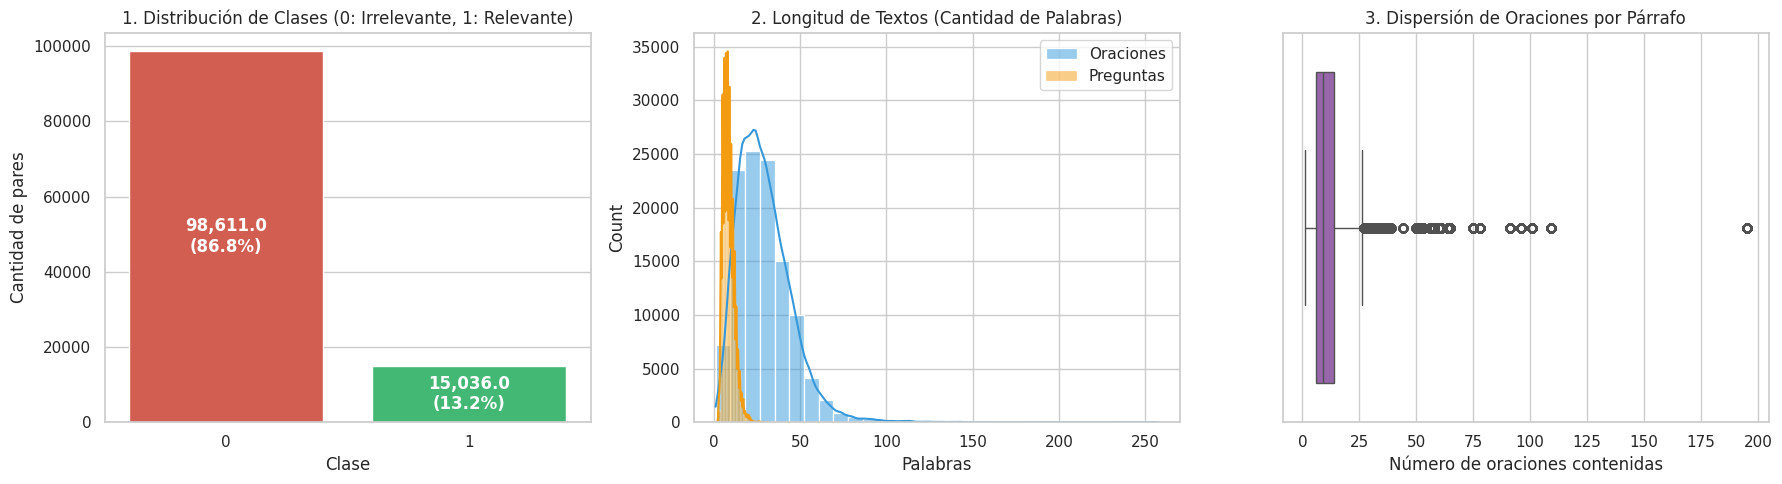

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Desbalance de Clases (Descubrimiento empírico)
sns.countplot(data=df_pares, x="label", ax=axes[0], palette=["#e74c3c", "#2ecc71"])
axes[0].set_title("1. Distribución de Clases (0: Irrelevante, 1: Relevante)")
axes[0].set_xlabel("Clase")
axes[0].set_ylabel("Cantidad de pares")
for p in axes[0].patches:
    total = len(df_pares)
    porcentaje = f"{100 * p.get_height() / total:.1f}%"
    axes[0].annotate(f"{p.get_height():,}\n({porcentaje})",
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha="center", va="center", color="white", fontweight="bold")

# Gráfico 2: Longitud de oraciones vs. preguntas (en palabras)
sns.histplot(df_pares["len_oracion"], bins=30, ax=axes[1], color="#3498db", kde=True, label="Oraciones")
sns.histplot(df_pares["len_pregunta"], bins=15, ax=axes[1], color="#f39c12", kde=True, label="Preguntas")
axes[1].set_title("2. Longitud de Textos (Cantidad de Palabras)")
axes[1].set_xlabel("Palabras")
axes[1].legend()

# Gráfico 3: Cantidad de oraciones por contexto
sns.boxplot(x=df_pares["num_oraciones_contexto"], ax=axes[2], color="#9b59b6")
axes[2].set_title("3. Dispersión de Oraciones por Párrafo")
axes[2].set_xlabel("Número de oraciones contenidas")

plt.tight_layout()
plt.show()


## 1.5 Interpretación de hallazgos y elección de la métrica

### 1. Desbalance de clases

En Train, aproximadamente **86,77% de los pares son clase 0** y **13,23% clase 1**. Por eso, un modelo que siempre predijera la clase mayoritaria podría alcanzar una exactitud alta sin identificar ninguna oración relevante.

> Elegimos **F1-Macro** como métrica principal porque calcula el F1 de cada clase y promedia ambos valores por igual. (queremos evaluar si el modelo distingue correctamente tanto las oraciones relevantes como las no relevantes.) Así, el rendimiento sobre la clase minoritaria tiene un peso explícito en la evaluación. También informamos Accuracy, pero no la interpretamos de forma aislada.

**¿Por qué no elegir solamente Recall?**

Porque podríamos conseguir un Recall alto clasificando muchas oraciones como relevantes, pero también generar una cantidad excesiva de falsos positivos. ¿Y por qué no solamente Precision? Porque podríamos ser muy selectivos y encontrar pocas oraciones relevantes, dejando muchas sin detectar.

En resumen, el F1-Macro nos permite evaluar el equilibrio entre ambas clases, sin que la clase mayoritaria domine la métrica. Eso encaja con nuestro objetivo: no queremos que el modelo simplemente aprenda a reconocer la clase 0, sino que también sea capaz de identificar la clase 1.

Eso no significa que Precision y Recall de la clase 1 dejen de importar. Los seguimos observando para entender cómo se comporta cada modelo y qué tipo de errores comete. Si la aplicación priorizara explícitamente recuperar la mayor cantidad posible de oraciones relevantes, entonces tendría sentido priorizar Recall; si el costo principal fueran las falsas detecciones, priorizaríamos Precision. Pero nuestro objetivo experimental es evaluar el rendimiento general en las dos clases.


### 2. Longitud de preguntas y oraciones

El segundo gráfico compara la cantidad de palabras de las preguntas y de las oraciones candidatas. Las preguntas suelen ser más breves, mientras que las oraciones presentan una distribución más amplia y una cola de textos largos.

Esta diferencia importa porque cada ejemplo combina ambos textos y después se transforma en características numéricas. Las oraciones largas también pueden contener más palabras que coincidan con la pregunta sin que necesariamente respondan a ella. Eso es una posible fuente de falsos positivos que investigaremos con ejemplos concretos.

### 3. Cantidad de oraciones por contexto

El tercer gráfico muestra cuántas oraciones detectamos en cada párrafo. Si una pregunta se combina con cada oración del mismo contexto, un párrafo con muchas oraciones puede producir numerosos pares negativos y, por lo tanto, contribuir al desbalance.

La distribución también permite detectar contextos excepcionalmente largos. Estos casos merecen atención porque pueden generar una cantidad desproporcionada de pares. No obstante, no todos los negativos son necesariamente inútiles: algunos son ejemplos válidos que ayudan al modelo a aprender a distinguir una respuesta de una oración que no responde a la pregunta.



In [9]:
print("\n1. LONGITUD DE PREGUNTAS Y ORACIONES (EN PALABRAS)")
display(
    df_pares[["len_pregunta", "len_oracion"]]
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .round(2)
)



1. LONGITUD DE PREGUNTAS Y ORACIONES (EN PALABRAS)


,len_pregunta,len_oracion
count,113647.00,113647.00
mean,8.51,29.16
std,3.24,15.86
min,2.00,1.00
50%,8.00,27.00
75%,10.00,38.00
90%,13.00,49.00
95%,14.00,57.00
99%,18.00,78.00
max,31.00,257.00


In [10]:
print("\n2. CANTIDAD DE ORACIONES POR CONTEXTO")
display(
    df_pares[["num_oraciones_contexto"]]
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .round(2)
)


2. CANTIDAD DE ORACIONES POR CONTEXTO


,num_oraciones_contexto
count,113647.00
mean,12.64
std,16.46
min,1.00
50%,9.00
75%,14.00
90%,21.00
95%,29.00
99%,96.00
max,195.00


In [11]:
print("\n3. DIEZ PARES CON LAS ORACIONES MÁS LARGAS")
display(
    df_pares.nlargest(10, "len_oracion")[
        ["pregunta", "oracion", "label", "len_oracion", "num_oraciones_contexto"]
    ]
)


3. DIEZ PARES CON LAS ORACIONES MÁS LARGAS


,pregunta,oracion,label,len_oracion,num_oraciones_contexto
2383,¿Cómo fue organizada la manifestación?,"En tanto, Petro acusó a los dirigentes del Pol...",0,257,5
2388,¿Quién dirige TransMilenio?,"En tanto, Petro acusó a los dirigentes del Pol...",0,257,5
2393,¿Cuándo fueron causados los estropicios en las...,"En tanto, Petro acusó a los dirigentes del Pol...",0,257,5
91663,¿Quién se enfrenta a Trump en las elecciones p...,"Pero fue hasta que el moderador, Chris Wallace...",0,232,7
91670,¿Cuál fue el mensaje más destacado de la inter...,"Pero fue hasta que el moderador, Chris Wallace...",0,232,7
63843,¿Qué pena es impuesta a los agresores sexuales...,"La senadora Gilma Jiménez del Partido Verde, p...",0,195,5
63848,¿Quiénes estaban en contra de la iniciativa?,"La senadora Gilma Jiménez del Partido Verde, p...",0,195,5
63853,¿Cuándo fue aprobada la iniciativa?,"La senadora Gilma Jiménez del Partido Verde, p...",0,195,5
113425,¿Cuáles son los tres países que planean reunir...,"""...Esta es una región en tremendo flujo e int...",0,188,7
113432,¿Qué podría llegar a ser China según la jefa d...,"""...Esta es una región en tremendo flujo e int...",0,188,7


In [12]:
print("\n5. DIEZ PARES DE LOS CONTEXTOS CON MÁS ORACIONES")
display(
    df_pares.nlargest(10, "num_oraciones_contexto")[
        ["pregunta", "oracion", "label", "len_oracion", "num_oraciones_contexto"]
    ]
)


5. DIEZ PARES DE LOS CONTEXTOS CON MÁS ORACIONES


,pregunta,oracion,label,len_oracion,num_oraciones_contexto
96404,¿Dónde se celebrará la edición de este año del...,"15 de mayo de 2009 15 de mayo de 2009Moscú, Ru...",0,17,195
96405,¿Dónde se celebrará la edición de este año del...,Casi todos los ojos de Europa están en los 25 ...,0,16,195
96406,¿Dónde se celebrará la edición de este año del...,"Si te gusta o lo odias, tendrá su atención.",0,9,195
96407,¿Dónde se celebrará la edición de este año del...,Cientos de millones de personas están viéndolos.,0,7,195
96408,¿Dónde se celebrará la edición de este año del...,Ya sea que los espectadores estén a la espera ...,0,35,195
96409,¿Dónde se celebrará la edición de este año del...,Esa es la sensación de que los participantes e...,1,30,195
96410,¿Dónde se celebrará la edición de este año del...,"La semana pasada, ocho cantantes de ocho paíse...",0,66,195
96411,¿Dónde se celebrará la edición de este año del...,Esta es la sexta y última serie de entrevistas...,0,33,195
96412,¿Dónde se celebrará la edición de este año del...,Mike Halterman ha realizado todas las entrevis...,0,16,195
96413,¿Dónde se celebrará la edición de este año del...,La ronda final se transmitirá el 16 de mayo a ...,0,14,195


### ¿Qué descubrimos al cuantificar las distribuciones y revisar ejemplos?

Las estadísticas confirman que las preguntas son relativamente breves: la mediana es de 8 palabras y el percentil 90 es de 13. Las oraciones candidatas son más largas: tienen una mediana de 27 palabras y el percentil 90 alcanza 49. Además, aparecen oraciones de hasta 257 palabras.

Esto confirma que las longitudes no son uniformes. La diferencia es relevante para el análisis posterior, aunque no demuestra por sí misma que las oraciones largas provoquen errores de clasificación.

También encontramos una distribución muy dispersa en la cantidad de oraciones detectadas por contexto: la mediana es de 9, el percentil 90 es de 21 y el percentil 99 alcanza 96. El máximo es de 195 oraciones.

Al revisar los ejemplos de las oraciones más largas, observamos que una misma oración puede aparecer asociada a varias preguntas del mismo contexto. Esto es importante porque las filas del dataset son pares pregunta-oración, no contextos únicos. Por lo tanto, las estadísticas calculadas sobre las filas pueden dar más peso a los contextos que generan muchos pares.

Los ejemplos de los contextos con más oraciones también nos permiten revisar casos concretos de la segmentación. En particular, conviene prestar atención a encabezados, fechas y fragmentos que podrían no comportarse como oraciones habituales.

**Aprendizaje:** ya sabemos que el dataset presenta una gran variabilidad en su estructura y que algunos contextos generan muchos pares. Todavía no sabemos cuánto afecta esto al rendimiento del modelo. Esa pregunta deberá investigarse mediante los resultados de clasificación y la revisión de errores, no únicamente con el EDA.

## 1.6 Preprocesamiento y entrenamiento del baseline

Antes de entrenar, debemos convertir los textos en números, porque la regresión logística no puede trabajar directamente con oraciones.

### ¿Cómo representamos los textos?

Utilizamos `TfidfVectorizer(max_features=5000, ngram_range=(1, 2), norm='l2')`.

- **Bolsa de palabras:** el texto se representa mediante características que indican qué palabras aparecen. No conserva toda la estructura gramatical de la oración ni comprende su significado como una persona.
- **Unigramas y bigramas:** además de palabras individuales, usamos combinaciones consecutivas de dos palabras. Por ejemplo, `capital` es un unigram y `capital de` es un bigrama. Esto permite capturar algunas expresiones, aunque no resuelve todas las relaciones semánticas.
- **Máximo de 5.000 características:** limitamos el vocabulario a un máximo de 5.000 características para controlar el tamaño de la representación.
- **TF-IDF:** asigna más peso a términos que son informativos en los documentos y reduce el peso relativo de términos muy frecuentes. La representación combina la frecuencia del término en el texto con información sobre su frecuencia en el corpus.
- **Normalización L2:** ajusta la magnitud del vector de cada ejemplo. Esto ayuda a que la escala total de sus características no dependa únicamente de la magnitud del vector, pero no hace que todos los textos tengan la misma longitud ni elimina sus diferencias de contenido.

Para construir la entrada, concatenamos la pregunta y la oración candidata con el separador `[SEP]`. TF-IDF trata esa cadena como texto: el separador no crea por sí solo una comprensión especial de la relación entre pregunta y oración.


#### Nota:

Usamos `class_weight='balanced'` para asignar mayor peso a la clase menos frecuente durante el entrenamiento. Esto busca reducir el dominio de la clase mayoritaria en la función de aprendizaje. No garantiza una mejora: su utilidad debe juzgarse con las métricas de Dev.


In [13]:
# 1. Ajuste del vectorizador solo en Train y transformación de Dev
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), norm='l2')

X_train_vec = vectorizer.fit_transform(df_pares['texto_combinado'])
y_train = df_pares['label']

X_dev_vec = vectorizer.transform(df_pares_dev['texto_combinado'])
y_dev = df_pares_dev['label']

# 2. Entrenamiento del clasificador lineal
baseline_model = LogisticRegression(class_weight="balanced", random_state=42, max_iter=500)
baseline_model.fit(X_train_vec, y_train)

# 3. Predicciones en el conjunto de desarrollo (Dev)
y_dev_pred = baseline_model.predict(X_dev_vec)

# 4. Cálculo y fijación de la Métrica Única de Referencia (Pauta 4.1.3)
BASELINE_F1_DEV = f1_score(y_dev, y_dev_pred, average="macro")
BASELINE_ACC_DEV = accuracy_score(y_dev, y_dev_pred)

print("=" * 60)
print(f"Piso de Referencia Establecido en Dev (F1-Macro): {BASELINE_F1_DEV:.4f}")
print(f"Accuracy alcanzado en Dev:                        {BASELINE_ACC_DEV:.4f}")
print("=" * 60)

Piso de Referencia Establecido en Dev (F1-Macro): 0.5624
Accuracy alcanzado en Dev:                        0.6835


## 1.7 Evaluación del Baseline en Dev y Matriz de Confusión

A continuación, inspeccionamos el rendimiento desglosado por clase mediante el reporte de clasificación y graficamos la **matriz de confusión** para analizar la distribución entre verdaderos positivos, falsos positivos y falsos negativos.


Reporte de Clasificación Detallado en Dev:
                 precision    recall  f1-score   support

Irrelevante (0)       0.93      0.69      0.79     13007
  Relevante (1)       0.23      0.63      0.33      1864

       accuracy                           0.68     14871
      macro avg       0.58      0.66      0.56     14871
   weighted avg       0.84      0.68      0.73     14871



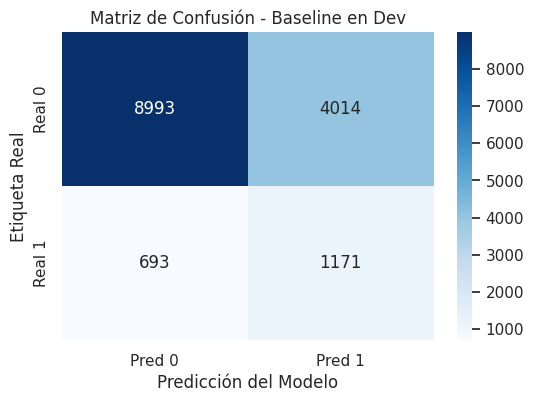

In [14]:
print("\nReporte de Clasificación Detallado en Dev:")
print(classification_report(y_dev, y_dev_pred, target_names=["Irrelevante (0)", "Relevante (1)"]))

# Matriz de Confusión
cm = confusion_matrix(y_dev, y_dev_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred 0", "Pred 1"],
            yticklabels=["Real 0", "Real 1"])
plt.title("Matriz de Confusión - Baseline en Dev")
plt.ylabel("Etiqueta Real")
plt.xlabel("Predicción del Modelo")
plt.show()


### 1.8 Diagnóstico del baseline en Dev

El baseline se evalúa sobre **14.871 pares de Dev**. Los resultados guardados son:

- **F1-Macro:** 0,5633.
- **Accuracy:** 68,42%.
- **Clase 1:** 1.176 verdaderos positivos y 688 falsos negativos, con recall aproximado de 0,63 y precisión aproximada de 0,23.
- **Falsos positivos:** 4.009.

La matriz de confusión y el reporte por clase permiten entender mejor estos valores. El modelo identifica 1.176 pares positivos correctamente, pero deja pasar 688 positivos y marca como positivos 4.009 pares cuya etiqueta es negativa.

En otras palabras, el modelo recupera una parte de las respuestas relevantes, pero también señala muchas oraciones que no corresponden a la respuesta anotada. La precisión de la clase positiva es baja en comparación con su recall: cuando el modelo predice que una oración es relevante, con frecuencia se equivoca.

Una posible explicación es que TF-IDF detecte palabras compartidas entre la pregunta y una oración sin representar completamente la relación semántica entre ambas. Por ejemplo, que una oración mencione una entidad relacionada con la pregunta no significa necesariamente que responda lo que se pregunta.

La matriz de confusión nos muestra qué tipos de error comete el modelo, pero no explica por sí sola por qué se produce cada error. Para investigar esto, en la siguiente etapa revisaremos una muestra reproducible de 50 predicciones incorrectas.

## 1.9 Conclusiones de la Etapa 1 y referencia para la Etapa 2

El EDA mostró que el problema tiene una distribución de clases desigual y que las preguntas, las oraciones candidatas y los contextos presentan longitudes diferentes. La estructura de pares pregunta-oración también explica por qué un único contexto puede producir varios ejemplos de entrenamiento.

Como baseline, TF-IDF junto con regresión logística obtiene F1-Macro de 0,5633 y Accuracy de 68,42 % en Dev. La matriz de confusión muestra que el modelo reconoce parte de las respuestas positivas, pero genera muchos falsos positivos y también deja pasar respuestas correctas.

Por eso, no alcanza con mejorar la exactitud general: necesitamos evaluar si los siguientes modelos consiguen un equilibrio mejor entre las dos clases. En la Etapa 2 analizaremos errores concretos y entrenaremos MLP con diferentes arquitecturas y técnicas de regularización.

El baseline se mantiene como referencia. Cuando comparemos sus resultados con los de la MLP, también tendremos en cuenta que el entrenamiento de la red utiliza una versión submuestreada de Train. Por lo tanto, una diferencia de rendimiento entre ambos modelos no puede atribuirse únicamente al cambio de arquitectura. (Aca deberiamos modificarlo, aun no sabemos si tomaremos como base el baseline o el baseline mas donwsmsapling)



# Etapa 2: Análisis de Errores y Red Neuronal Densa (MLP)

En esta etapa buscamos superar las limitaciones observadas en el baseline mediante dos líneas de trabajo:

1. **Análisis de errores:** examinamos una muestra de 50 errores del baseline en Dev para identificar dificultades concretas de la tarea de Answer Sentence Selection.
2. **Modelado con una red neuronal densa (MLP):** construimos y evaluamos diferentes configuraciones, modificando progresivamente la arquitectura y las técnicas de regularización según los resultados de cada experimento.

El problema consiste en determinar si una oración candidata responde realmente a una pregunta. Aunque TF-IDF permite representar los textos mediante características numéricas, la coincidencia de palabras no garantiza que exista una relación correcta entre la pregunta y la respuesta.

Para esta etapa utilizaremos una MLP con varias capas ocultas.



In [15]:



# Palabras funcionales excluidas de la comparación léxica descriptiva.
palabras_vacias = {
    "a", "al", "de", "del", "el", "la", "las", "los", "un", "una", "unos", "unas",
    "y", "o", "u", "en", "por", "para", "con", "sin", "que", "qué", "quien",
    "quién", "quienes", "quiénes", "cual", "cuál", "cuales", "cuáles", "como",
    "cómo", "cuando", "cuándo", "donde", "dónde", "es", "son", "fue", "era",
    "ser", "se", "su", "sus", "lo", "le", "les", "año", "años"
}


def obtener_tokens(texto):
    tokens = re.findall(r"\b[a-záéíóúüñ]+\b", str(texto).lower())
    return {
        token for token in tokens
        if token not in palabras_vacias and len(token) > 1
    }


def coincidencia_lexica(fila):
    tokens_pregunta = obtener_tokens(fila["pregunta"])
    tokens_oracion = obtener_tokens(fila["oracion"])
    compartidas = sorted(tokens_pregunta & tokens_oracion)

    return pd.Series({
        "palabras_compartidas": ", ".join(compartidas),
        "cantidad_compartidas": len(compartidas),
        "proporcion_pregunta_compartida": (
            len(compartidas) / len(tokens_pregunta)
            if tokens_pregunta else 0.0
        )
    })


# Asociar las predicciones del baseline con los pares originales de Dev.
df_analisis_dev = df_pares_dev.copy()
df_analisis_dev["indice_dev"] = df_pares_dev.index.to_numpy()
df_analisis_dev["prediccion_baseline"] = np.asarray(y_dev_pred).astype(int)

if len(df_analisis_dev) != len(y_dev_pred):
    raise ValueError("La cantidad de predicciones no coincide con las filas de Dev.")

# Conservar únicamente los ejemplos mal clasificados.
df_fallas_dev = df_analisis_dev[
    df_analisis_dev["label"] != df_analisis_dev["prediccion_baseline"]
].copy()

df_fallas_dev["tipo_error"] = np.where(
    df_fallas_dev["label"] == 0,
    "Falso positivo",
    "Falso negativo"
)

print(
    f"Errores del baseline: {len(df_fallas_dev):,} de "
    f"{len(df_analisis_dev):,} pares de Dev "
    f"({len(df_fallas_dev) / len(df_analisis_dev):.2%})."
)

if len(df_fallas_dev) < 50:
    print(
        f"Advertencia: hay solo {len(df_fallas_dev)} errores; "
        "no es posible seleccionar 50 errores distintos."
    )

# Selección reproducible: misma muestra si datos, predicciones y orden no cambian.
muestra_50_errores = df_fallas_dev.sample(
    n=min(50, len(df_fallas_dev)),
    random_state=42
).copy()

# Añadir indicadores descriptivos para facilitar la revisión manual.
indicadores_lexicos = muestra_50_errores.apply(coincidencia_lexica, axis=1)
muestra_50_errores = pd.concat(
    [muestra_50_errores, indicadores_lexicos],
    axis=1
)

muestra_50_errores["diferencia_longitud"] = (
    muestra_50_errores["len_oracion"]
    - muestra_50_errores["len_pregunta"]
).abs()

# Ordenar por el índice original de Dev para facilitar la trazabilidad.
muestra_50_errores = muestra_50_errores.sort_values(
    "indice_dev"
).reset_index(drop=True)

# Guardar el CSV que subiremos a GitHub.
RUTA_CSV_ERRORES = "analisis_50_errores_baseline.csv"
muestra_50_errores.to_csv(RUTA_CSV_ERRORES, index=False, encoding="utf-8-sig")

print(f"\nArchivo creado: {RUTA_CSV_ERRORES}")
print(f"Casos guardados: {len(muestra_50_errores)}")

print("\nDistribución de errores en la muestra:")
display(
    muestra_50_errores["tipo_error"]
    .value_counts()
    .rename_axis("Tipo de error")
    .to_frame("Cantidad")
)

print("\nDistribución de errores en todos los errores de Dev:")
display(
    df_fallas_dev["tipo_error"]
    .value_counts()
    .rename_axis("Tipo de error")
    .to_frame("Cantidad")
)

# Descargar el archivo desde Colab para subirlo al repositorio.
try:
    from google.colab import files
    files.download(RUTA_CSV_ERRORES)
except ImportError:
    print(
        "No se detectó Google Colab. El CSV quedó guardado "
        "en el directorio de trabajo actual."
    )


Errores del baseline: 4,707 de 14,871 pares de Dev (31.65%).

Archivo creado: analisis_50_errores_baseline.csv
Casos guardados: 50

Distribución de errores en la muestra:


,Cantidad
Tipo de error,
Falso positivo,44
Falso negativo,6



Distribución de errores en todos los errores de Dev:


,Cantidad
Tipo de error,
Falso positivo,4014
Falso negativo,693


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
# 2.1.2 — Cargar la muestra guardada, localmente o desde GitHub

RUTA_CSV_ERRORES = "analisis_50_errores_baseline.csv"

# Después de subir el CSV a GitHub, pegar aquí su URL Raw.
# Solución: Se reemplaza la URL del blob por la versión 'raw' de GitHub
CSV_URL_GITHUB = "https://raw.githubusercontent.com/michaeljunior05/Inteligencia-Artificial-TP-2026/main/analisis_50_errores_baseline.csv"

if CSV_URL_GITHUB.strip():
    df_50_errores = pd.read_csv(CSV_URL_GITHUB.strip())
    origen_csv = "GitHub (Raw)"
else:
    df_50_errores = pd.read_csv(RUTA_CSV_ERRORES)
    origen_csv = "archivo local de esta sesión"

columnas_requeridas = [
    "pregunta",
    "oracion",
    "label",
    "prediccion_baseline",
    "tipo_error"
]

faltantes = [
    columna for columna in columnas_requeridas
    if columna not in df_50_errores.columns
]

if faltantes:
    raise ValueError(
        f"Al CSV le faltan columnas necesarias: {faltantes}"
    )

# Verificar que todos los registros sean realmente errores.
errores_invalidos = df_50_errores[
    df_50_errores["label"] == df_50_errores["prediccion_baseline"]
]

if not errores_invalidos.empty:
    raise ValueError(
        "El CSV contiene registros cuya etiqueta real coincide con "
        "la predicción. Revisá que sea la muestra correcta de errores."
    )

print(f"Origen del archivo: {origen_csv}")
print(f"Cantidad de casos cargados: {len(df_50_errores)}")
print(f"Columnas disponibles: {list(df_50_errores.columns)}")

if len(df_50_errores) != 50:
    print(
        "Advertencia: el archivo no contiene exactamente 50 casos. "
        "Revisá si la muestra se generó cuando había menos de 50 errores."
    )

Origen del archivo: GitHub (Raw)
Cantidad de casos cargados: 50
Columnas disponibles: ['pregunta', 'oracion', 'texto_combinado', 'label', 'len_pregunta', 'len_oracion', 'num_oraciones_contexto', 'indice_dev', 'prediccion_baseline', 'tipo_error', 'palabras_compartidas', 'cantidad_compartidas', 'proporcion_pregunta_compartida', 'diferencia_longitud']


In [17]:

# 2.1.3 — Presentación HTML de los errores guardados



# Si el CSV antiguo no tiene estos indicadores, calcularlos para mostrar.
if "palabras_compartidas" not in df_50_errores.columns:
    indicadores_lexicos = df_50_errores.apply(coincidencia_lexica, axis=1)
    df_50_errores = pd.concat(
        [
            df_50_errores.reset_index(drop=True),
            indicadores_lexicos.reset_index(drop=True)
        ],
        axis=1
    )

if "diferencia_longitud" not in df_50_errores.columns:
    if {"len_pregunta", "len_oracion"}.issubset(df_50_errores.columns):
        df_50_errores["diferencia_longitud"] = (
            df_50_errores["len_oracion"] - df_50_errores["len_pregunta"]
        ).abs()

# Resumen descriptivo: ayuda a organizar la inspección, no explica las causas.
print("RESUMEN DE LA MUESTRA")
resumen_columnas = {
    "label": "cantidad"
}

resumen_errores = (
    df_50_errores.groupby("tipo_error")
    .agg(cantidad=("label", "size"))
)

columnas_resumen = [
    col for col in [
        "len_pregunta",
        "len_oracion",
        "cantidad_compartidas",
        "proporcion_pregunta_compartida"
    ]
    if col in df_50_errores.columns
]

if columnas_resumen:
    resumen_numerico = (
        df_50_errores.groupby("tipo_error")[columnas_resumen]
        .median()
        .round(3)
    )
    resumen_errores = resumen_errores.join(
        resumen_numerico,
        how="left"
    )

display(resumen_errores)

# Preparar una lista legible de casos.
df_50_ordenados = df_50_errores.copy()

if "indice_dev" in df_50_ordenados.columns:
    df_50_ordenados = df_50_ordenados.sort_values("indice_dev")

filas_html = []

for numero, (_, fila) in enumerate(df_50_ordenados.iterrows(), start=1):
    tipo = html.escape(str(fila["tipo_error"]))
    pregunta = html.escape(str(fila["pregunta"]))
    oracion = html.escape(str(fila["oracion"]))

    real = int(fila["label"])
    pred = int(fila["prediccion_baseline"])

    compartidas = html.escape(
        str(fila.get("palabras_compartidas", "No calculadas"))
    )
    if compartidas.strip() == "":
        compartidas = "Ninguna detectada"

    cantidad_compartidas = fila.get("cantidad_compartidas", "N/D")
    proporcion = fila.get("proporcion_pregunta_compartida", None)

    if proporcion is not None and pd.notna(proporcion):
        texto_proporcion = f"{float(proporcion):.0%}"
    else:
        texto_proporcion = "N/D"

    longitud_pregunta = fila.get("len_pregunta", "N/D")
    longitud_oracion = fila.get("len_oracion", "N/D")
    contexto = fila.get("num_oraciones_contexto", "N/D")
    indice = fila.get("indice_dev", "No registrado")

    filas_html.append(f"""
    <details class="caso-error">
      <summary>
        <span class="numero-caso">Caso {numero:02d}</span>
        <span class="tipo-error">{tipo}</span>
        <span class="etiquetas">Real: {real} · Predicción: {pred}</span>
      </summary>
      <div class="contenido-caso">
        <p><strong>Pregunta</strong></p>
        <div class="texto-caso">{pregunta}</div>

        <p><strong>Oración candidata</strong></p>
        <div class="texto-caso">{oracion}</div>

        <div class="metadatos-caso">
          <span><strong>Fila Dev:</strong> {html.escape(str(indice))}</span>
          <span><strong>Longitud pregunta:</strong> {html.escape(str(longitud_pregunta))}</span>
          <span><strong>Longitud oración:</strong> {html.escape(str(longitud_oracion))}</span>
          <span><strong>Oraciones en contexto:</strong> {html.escape(str(contexto))}</span>
          <span><strong>Coincidencias léxicas:</strong> {html.escape(str(cantidad_compartidas))}</span>
          <span><strong>Proporción compartida:</strong> {texto_proporcion}</span>
        </div>

        <p><strong>Palabras compartidas (indicador descriptivo)</strong></p>
        <div class="palabras-compartidas">{compartidas}</div>
      </div>
    </details>
    """)

contenido_html = """
<style>
.panel-errores {
    font-family: Arial, sans-serif;
    line-height: 1.5;
    color: var(--colab-primary-text-color, #222);
}
.caso-error {
    border: 1px solid var(--colab-border-color, #ccc);
    border-radius: 9px;
    margin: 9px 0;
    overflow: hidden;
}
.caso-error summary {
    cursor: pointer;
    padding: 12px;
    background: var(--colab-secondary-surface-color, #f3f5f7);
    display: flex;
    flex-wrap: wrap;
    gap: 8px 14px;
    align-items: center;
}
.numero-caso {
    font-weight: bold;
}
.tipo-error {
    font-weight: bold;
}
.etiquetas {
    margin-left: auto;
    font-size: 0.92em;
}
.contenido-caso {
    padding: 14px;
}
.texto-caso, .palabras-compartidas {
    padding: 11px;
    border-radius: 6px;
    background: var(--colab-primary-surface-color, #fff);
    border: 1px solid var(--colab-border-color, #ddd);
    overflow-wrap: anywhere;
    white-space: normal;
}
.metadatos-caso {
    display: flex;
    flex-wrap: wrap;
    gap: 8px 16px;
    margin: 12px 0;
    font-size: 0.9em;
}
</style>
<div class="panel-errores">
<p><strong>Guía:</strong> abrí cada caso para leer la pregunta y la oración completa.
Las coincidencias léxicas son descriptivas; no demuestran por sí solas por qué ocurrió el error.</p>
""" + "".join(filas_html) + "</div>"

display(HTML(contenido_html))


RESUMEN DE LA MUESTRA


,cantidad,len_pregunta,len_oracion,cantidad_compartidas,proporcion_pregunta_compartida
tipo_error,,,,,
Falso negativo,7,7.0,33.0,1.0,0.5
Falso positivo,43,7.0,34.0,0.0,0.0


### 2.1.1 Lectura de la muestra de errores

La muestra permite examinar situaciones en las que el baseline no coincide con la etiqueta real. Distinguimos dos tipos:

- **Falso positivo:** la oración está etiquetada como irrelevante (0), pero el modelo la predice como relevante (1).
- **Falso negativo:** la oración está etiquetada como relevante (1), pero el modelo la predice como irrelevante (0).

Las coincidencias de palabras entre la pregunta y la oración pueden ayudar a describir los ejemplos, pero no demuestran que la oración responda correctamente a la pregunta. Del mismo modo, la longitud de los textos no permite concluir por sí sola que un caso sea más difícil.

La inspección debe centrarse en la relación entre la pregunta, la oración candidata, la etiqueta real y la predicción. No clasificaremos automáticamente cada error como sesgo, varianza o *data mismatch*: primero debemos reunir evidencia concreta.

### 2.1.3 Interpretación del análisis de errores del baseline

Se examinó una muestra reproducible de 50 errores del baseline sobre el conjunto Dev: 43 falsos positivos y 7 falsos negativos. Por lo tanto, los falsos positivos representan el 86 % de esta muestra y los falsos negativos, el 14 %. Esta distribución describe los errores seleccionados y no debe confundirse con la distribución de todas las predicciones de Dev.

#### Falsos positivos

El patrón más frecuente en los ejemplos es la predicción de relevancia para oraciones que comparten el tema o alguna entidad con la pregunta, pero no contienen la información solicitada. Por ejemplo, una oración puede mencionar a Salvador Allende sin indicar dónde nació, o describir el origen del nombre de Monte Albán sin informar cuándo se fundó.

También aparecen casos en los que la oración contiene información del tipo esperado, pero responde una pregunta diferente. Esto ocurre, por ejemplo, cuando se informa el costo de un festejo ante una pregunta sobre su duración, o cuando se menciona la adquisición de un avión sin identificar la compañía a la que pertenece.

Algunos falsos positivos no presentan coincidencias léxicas significativas entre la pregunta y la oración; otros comparten nombres propios o términos relacionados con el tema. En consecuencia, las coincidencias léxicas por sí solas no permiten determinar si una oración responde la pregunta.

#### Falsos negativos

Los falsos negativos muestran el problema inverso: algunas oraciones que contienen información potencialmente relevante son clasificadas como irrelevantes. Entre los ejemplos aparecen expresiones semánticamente equivalentes, como «favorito» y «máximo candidato», así como diferencias de formulación entre «raptados» y «secuestrado».

Otros casos expresan la respuesta mediante una construcción indirecta. Por ejemplo, decir que a las 11 de la mañana ya no quedaban entradas permite inferir cuándo se agotaron. Estos ejemplos sugieren que la relación entre la pregunta y la respuesta no siempre se expresa mediante una coincidencia literal de palabras.

#### ¿Qué aportan las coincidencias léxicas?

En la muestra, muchos falsos positivos no comparten palabras significativas con la pregunta. Sin embargo, también encontramos falsos positivos con palabras compartidas, como «Monte Albán» o «Arnold». En esos casos, la coincidencia identifica el tema, pero no garantiza que la oración contenga la respuesta.

Por su parte, algunos falsos negativos comparten palabras con la pregunta, mientras que otros requieren reconocer equivalencias de significado o relaciones expresadas de manera indirecta.

Las coincidencias léxicas son, por lo tanto, indicadores descriptivos y no una explicación definitiva de las predicciones. No miden directamente si una oración responde la pregunta.

#### Conclusión del análisis

El principal aprendizaje de esta revisión es que una oración puede estar relacionada con una pregunta sin responderla, y también puede responderla sin utilizar exactamente las mismas palabras.

Los falsos positivos ilustran la dificultad de distinguir entre compartir un tema y proporcionar la información solicitada. Los falsos negativos muestran la dificultad de reconocer paráfrasis, expresiones equivalentes y respuestas indirectas.

Este análisis cualitativo complementa las métricas del baseline y nos da una referencia para la siguiente etapa: evaluar si las redes neuronales consiguen representar mejor las relaciones entre las preguntas y las oraciones candidatas.

Por eso, al desarrollar los siguientes modelos no buscaremos solamente aumentar el número de predicciones positivas. El objetivo será mejorar el equilibrio entre la identificación de respuestas relevantes y el rechazo de oraciones irrelevantes. Esta necesidad también justifica utilizar F1-Macro y examinar las matrices de confusión, en lugar de guiarnos únicamente por Accuracy.

---


## 2.2 Optimización de datos: *negative downsampling* en Train

El Train original contiene **113.647 pares**. La proporción de negativos es **86,77%** y la de positivos **13,23%**.

Para reducir el volumen de pares negativos usados en el entrenamiento de la MLP, aplicamos *negative downsampling* con una razón máxima de dos negativos por cada pregunta con oración positiva. Se conservan las oraciones positivas identificadas por `answer_start` y se seleccionan aleatoriamente hasta dos negativas del mismo contexto para cada pregunta. Debido a la estructura de los datos y a los casos sin positivos, el tamaño final no es exactamente la mitad del original.

Elegimos una proporción máxima de dos negativos por positivo como una estrategia práctica para reducir el tamaño de Train y aumentar la presencia relativa de la clase positiva. La intención es que la red reciba más ejemplos positivos en relación con el total y que el entrenamiento sea menos costoso.

Esta decisión tiene un costo: al descartar negativos, también perdemos ejemplos que podrían ayudar al modelo a distinguir respuestas de oraciones parecidas pero incorrectas. Además, la distribución de clases del Train reducido deja de ser igual a la del Dev oficial.

Por eso, no asumimos que el submuestreo mejora el modelo automáticamente. Compararemos la distribución antes y después, mantendremos Dev sin submuestrear y agregaremos una regresión logística entrenada con el mismo Train reducido que utiliza la MLP. Esa comparación nos ayudará a separar mejor el efecto del muestreo del efecto de la arquitectura.


In [18]:
def submuestrear_negativos_train(dataset_split, ratio_negativos=2, random_state=42):
    """
    Construye los pares para Train manteniendo la oración positiva exacta (según answer_start)
    y seleccionando aleatoriamente un máximo de 2 oraciones negativas del mismo párrafo.
    """
    np.random.seed(random_state)
    registros = []

    for entry_wrapper in dataset_split:
        for doc in entry_wrapper['data']:
            for para in doc['paragraphs']:
                contexto = para['context']
                oraciones_spans = segmentar_oraciones_con_indices(contexto)
                num_oraciones = len(oraciones_spans)

                for qa in para['qas']:
                    pregunta = qa["question"]
                    respuestas_list = qa.get("answers", [])
                    if not respuestas_list:
                        continue

                    ans_start = respuestas_list[0]["answer_start"]

                    positivas = []
                    negativas = []

                    for oracion, ini_char, fin_char in oraciones_spans:
                        es_pos = 1 if (ini_char <= ans_start < fin_char) else 0
                        item = {
                            "pregunta": pregunta,
                            "oracion": oracion,
                            "texto_combinado": f"{pregunta} [SEP] {oracion}",
                            "label": es_pos,
                            "len_pregunta": len(pregunta.split()),
                            "len_oracion": len(oracion.split()),
                            "num_oraciones_contexto": num_oraciones
                        }
                        if es_pos == 1:
                            positivas.append(item)
                        else:
                            negativas.append(item)

                    if len(positivas) > 0:
                        registros.extend(positivas)
                        n_muestrear = min(len(negativas), len(positivas) * ratio_negativos)
                        if n_muestrear > 0:
                            indices_neg = np.random.choice(len(negativas), size=n_muestrear, replace=False)
                            for idx in indices_neg:
                                registros.append(negativas[idx])

    return pd.DataFrame(registros)

print("Generando Train optimizado mediante Negative Downsampling (1:2) con answer_start...")
df_train_down = submuestrear_negativos_train(raw_dataset["train"], ratio_negativos=2)

print(f"Total de pares en Train original:   {len(df_pares):,} muestras")
print(f"Total de pares en Train optimizado: {len(df_train_down):,} muestras")
print("Nueva proporción de clases en Train:")
print(df_train_down["label"].value_counts(normalize=True).map("{:.2%}".format))

# Vectorización TF-IDF
vectorizer_mlp = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), norm='l2')

X_train_mlp = vectorizer_mlp.fit_transform(df_train_down["texto_combinado"]).toarray()
y_train_mlp = df_train_down["label"].values

# Dev se transforma con el vocabulario aprendido en Train sin alterar sus muestras
X_dev_mlp = vectorizer_mlp.transform(df_pares_dev["texto_combinado"]).toarray()
y_dev_mlp = df_pares_dev["label"].values

print(f"\nDimensiones de entrada a la red: X_train {X_train_mlp.shape} | X_dev {X_dev_mlp.shape}")

Generando Train optimizado mediante Negative Downsampling (1:2) con answer_start...
Total de pares en Train original:   113,647 muestras
Total de pares en Train optimizado: 44,105 muestras
Nueva proporción de clases en Train:
label
0    65.91%
1    34.09%
Name: proportion, dtype: object

Dimensiones de entrada a la red: X_train (44105, 5000) | X_dev (14871, 5000)


In [19]:

# Comparación cuantitativa del dataset antes y después del downsampling

def resumen_dataset(nombre, df):
    conteos = df["label"].value_counts().reindex([0, 1], fill_value=0)
    return {
        "Conjunto": nombre,
        "Total de pares": len(df),
        "Negativos": int(conteos.loc[0]),
        "Positivos": int(conteos.loc[1]),
        "% negativos": 100 * conteos.loc[0] / len(df),
        "% positivos": 100 * conteos.loc[1] / len(df)
    }

comparacion_downsampling = pd.DataFrame([
    resumen_dataset("Dev oficial", df_pares_dev)
])

display(comparacion_downsampling.round(2))

print(
    "\nReducción del número de pares de Train: "
    f"{100 * (1 - len(df_train_down) / len(df_pares)):.2f}%"
)

print(
    "Cambio en el porcentaje de positivos: "
    f"{100 * (df_train_down['label'].mean() - df_pares['label'].mean()):+.2f} "
    "puntos porcentuales"
)


,Conjunto,Total de pares,Negativos,Positivos,% negativos,% positivos
0,Dev oficial,14871,13007,1864,87.47,12.53



Reducción del número de pares de Train: 61.19%
Cambio en el porcentaje de positivos: +20.86 puntos porcentuales



Resultados guardados:
- **Train original:** 113.647 pares; 86,77% negativos.
- **Train reducido:** 44.105 pares; 65,91% negativos y 34,09% positivos.
- **Dev:** 14.871 pares; 87,47% negativos y 12,53% positivos.


## Gráfico de Barras: Comparación de Proporciones Antes y Después

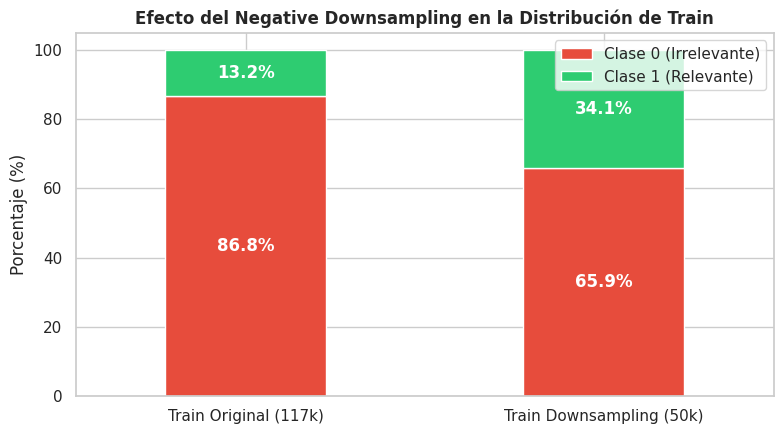

In [20]:
# Gráfico comparativo de la proporción de clases antes y después del submuestreo
prop_original = df_pares["label"].value_counts(normalize=True) * 100
prop_down = df_train_down["label"].value_counts(normalize=True) * 100

df_comp_prop = pd.DataFrame({
    "Train Original (117k)": prop_original,
    "Train Downsampling (50k)": prop_down
}, index=[0, 1])

ax = df_comp_prop.T.plot(kind="bar", stacked=True, color=["#e74c3c", "#2ecc71"], figsize=(8, 4.5), width=0.45)
plt.title("Efecto del Negative Downsampling en la Distribución de Train", fontsize=12, fontweight="bold")
plt.ylabel("Porcentaje (%)")
plt.xticks(rotation=0)
plt.legend(["Clase 0 (Irrelevante)", "Clase 1 (Relevante)"], loc="upper right")

for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    if height > 5:
        x, y = p.get_xy()
        ax.text(x + width/2, y + height/2, f"{height:.1f}%", ha="center", va="center", color="white", fontweight="bold")

plt.tight_layout()
plt.show()


### 2.2.1 Regresión logística con el mismo Train reducido

Antes de pasar a la red neuronal, entrenamos una segunda regresión logística utilizando el Train reducido. Este experimento nos permite estudiar el efecto del *downsampling* sin cambiar todavía el tipo de modelo.

Así podemos distinguir dos posibles fuentes de mejora: el efecto de modificar la distribución de entrenamiento y el efecto de utilizar una arquitectura más compleja.

La comparación se realiza sobre el mismo conjunto Dev. De este modo, cualquier diferencia observada corresponde al comportamiento de los modelos evaluados bajo las mismas condiciones de desarrollo, aunque sus conjuntos de entrenamiento sean diferentes.


Reporte: regresión logística con Train reducido
                 precision    recall  f1-score   support

Irrelevante (0)       0.92      0.70      0.79     13007
  Relevante (1)       0.22      0.59      0.32      1864

       accuracy                           0.68     14871
      macro avg       0.57      0.64      0.56     14871
   weighted avg       0.83      0.68      0.74     14871



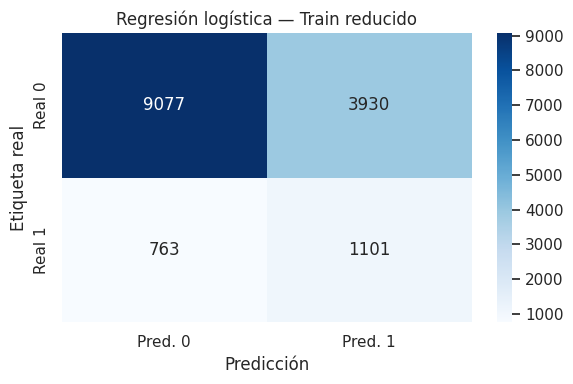

F1-Macro: 0.557
Accuracy: 0.6844


In [21]:

# Regresión logística entrenada con el mismo Train reducido que utiliza la MLP.
# Se conservan variables independientes para no sobrescribir el baseline original.

baseline_down_model = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=500
)

baseline_down_model.fit(X_train_mlp, y_train_mlp)

y_dev_pred_down = baseline_down_model.predict(X_dev_mlp)

print("Reporte: regresión logística con Train reducido")
print(classification_report(
    y_dev_mlp,
    y_dev_pred_down,
    target_names=["Irrelevante (0)", "Relevante (1)"],
    zero_division=0
))

cm_down = confusion_matrix(
    y_dev_mlp,
    y_dev_pred_down,
    labels=[0, 1]
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_down,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred. 0", "Pred. 1"],
    yticklabels=["Real 0", "Real 1"]
)
plt.title("Regresión logística — Train reducido")
plt.ylabel("Etiqueta real")
plt.xlabel("Predicción")
plt.tight_layout()
plt.show()

print("F1-Macro:", round(
    f1_score(y_dev_mlp, y_dev_pred_down, average="macro"), 4
))
print("Accuracy:", round(
    accuracy_score(y_dev_mlp, y_dev_pred_down), 4
))


### 2.2.2 Interpretación de la regresión logística con Train reducido

Al reducir el conjunto Train mediante *downsampling*, buscamos disminuir el desequilibrio entre las clases y estudiar si una distribución de entrenamiento menos desigual permite mejorar la identificación de oraciones relevantes.

#### Comparación con el baseline original

| Métrica | Baseline original | Train reducido | Diferencia aproximada |
|---|---:|---:|---:|
| F1-Macro | 0,5633 | 0,5570 | -0,0063 |
| Accuracy | 0,6842 | 0,6843 | +0,0001 |

Sin embargo las métricas globales muestran un comportamiento prácticamente igual al del baseline original. La accuracy no cambia de forma apreciable y el F1-Macro disminuye ligeramente. Por lo tanto, esto no demuestra que reducir el desequilibrio de clases mejore el rendimiento predictivo.


La matriz de confusión permite entender mejor el comportamiento del modelo. De las 1.864 oraciones relevantes de Dev, identifica correctamente 1.101 y deja escapar 763. Además, clasifica como relevantes 3.930 oraciones que en realidad pertenecen a la clase irrelevante. Esto explica por qué la precisión de la clase relevante es baja (0,22), aunque su recall llega a 0,59.

El resultado muestra que el modelo consigue recuperar más de la mitad de las oraciones relevantes, pero lo hace seleccionando también muchas oraciones que no responden la pregunta.

Si la matriz del baseline original confirma que los falsos positivos disminuyeron, podremos señalar esa diferencia como un cambio específico en el comportamiento del modelo. No obstante, una reducción de falsos positivos no implica necesariamente una mejora global: también deben considerarse los falsos negativos y el rendimiento de ambas clases.


#### ¿Qué ganamos al reducir Train?

El resultado favorable de este experimento no está en una mejora de las métricas, sino en la reducción del conjunto de entrenamiento. Trabajar con menos pares puede disminuir el costo computacional de los entrenamientos posteriores y facilitar la exploración de distintas arquitecturas y configuraciones.


Esto nos motiva a explorar modelos capaces de aprender representaciones más complejas. En la Etapa 2 probaremos redes neuronales con distintas arquitecturas y estrategias de regularización, comparando sus métricas y curvas de entrenamiento y validación. El objetivo será comprobar si esos cambios permiten mejorar el equilibrio entre detectar respuestas relevantes y evitar seleccionar oraciones irrelevantes.


---

In [22]:


resultados_individuales = {}

def evaluar_y_graficar_mlp(nombre, modelo, historia, clave):
    # Predicciones en modo de inferencia.
    probabilidades = modelo.predict(
        X_dev_mlp,
        batch_size=2048,
        verbose=0
    ).ravel()

    # Umbral común para comparar arquitecturas.
    predicciones = (probabilidades >= 0.50).astype(int)

    f1_macro = f1_score(
        y_dev_mlp, predicciones, average="macro"
    )
    accuracy = accuracy_score(y_dev_mlp, predicciones)

    print("=" * 72)
    print(f"EVALUACIÓN EN DEV — {nombre}")
    print("=" * 72)
    print("Umbral:   0.50")
    print(f"F1-Macro: {f1_macro:.4f}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Épocas ejecutadas: {len(historia.history['loss'])}")

    print("\nReporte de clasificación:")
    print(classification_report(
        y_dev_mlp,
        predicciones,
        labels=[0, 1],
        target_names=["Irrelevante (0)", "Relevante (1)"],
        digits=4,
        zero_division=0
    ))

    # Matriz de confusión.
    cm = confusion_matrix(
        y_dev_mlp, predicciones, labels=[0, 1]
    )

    plt.figure(figsize=(6, 4.5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Pred. 0", "Pred. 1"],
        yticklabels=["Real 0", "Real 1"]
    )
    plt.title(
        f"{nombre}\nF1-Macro={f1_macro:.4f} | "
        f"Accuracy={accuracy:.4f}"
    )
    plt.ylabel("Etiqueta real")
    plt.xlabel("Predicción")
    plt.tight_layout()
    plt.show()

    # Curvas de aprendizaje individuales.
    historial = historia.history
    epocas = range(1, len(historial["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # Curvas de Loss: Train y Dev comparten el mismo eje.
    axes[0].plot(
        epocas, historial["loss"],
        label="Train"
    )
    if "val_loss" in historial:
        axes[0].plot(
            epocas, historial["val_loss"],
            label="Dev"
        )

    axes[0].set_title(f"{nombre} — Loss")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[0].set_ylim(0, 1)

    # Curvas de Accuracy: Train y Dev comparten el mismo eje.
    axes[1].plot(
        epocas, historial["accuracy"],
        label="Train"
    )
    if "val_accuracy" in historial:
        axes[1].plot(
            epocas, historial["val_accuracy"],
            label="Dev"
        )

    axes[1].set_title(f"{nombre} — Accuracy")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_ylim(0, 1)
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Guardamos resultados para la comparación final.
    resultados_individuales[clave] = {
        "nombre": nombre,
        "f1_macro": f1_macro,
        "accuracy": accuracy,
        "predicciones": predicciones,
        "probabilidades": probabilidades,
        "matriz_confusion": cm,
        "historia": historia
    }

    return resultados_individuales[clave]


## 2.3 Primer experimento: arquitectura vista en clase

Para establecer una primera referencia con una red neuronal, comenzamos con una arquitectura densa sin técnicas de regularización. La entrada corresponde a las 5.000 características TF-IDF y la red aprende a combinarlas mediante capas ocultas con activación no lineal para clasificar cada par pregunta-oración.

Este primer modelo funciona como punto de partida para observar cómo aprende la MLP cuando no limitamos su capacidad mediante Dropout o penalización L2, ni detenemos el entrenamiento anticipadamente.

Entrenaremos durante un máximo de 100 épocas y examinaremos tanto las métricas en Dev como las curvas de pérdida y accuracy de entrenamiento y validación. En particular, buscaremos comprobar si la red generaliza lo aprendido o si aparece una brecha entre su desempeño en Train y Dev.


## Entrenamiento Modelo 1 (Sin Regularización)

Tres capas ocultas **32 → 64 → 128**, seguida de una neurona con activacion sigmoide.

In [23]:
tf.random.set_seed(42)
np.random.seed(42)

# ==============================================================================
# MODELO 1: Arquitectura del Profesor SIN Regularización (100 épocas)
# ==============================================================================
mlp_1_sin_reg = Sequential([
    Dense(32, activation='relu', input_shape=(5000,)),
    Dense(64, activation='relu'),
    Dense(128, activation='relu'),
    Dense(1, activation='sigmoid')
])

mlp_1_sin_reg.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

print("--- Entrenando MODELO 1: Profesor Sin Regularización (100 épocas fijas) ---")
history_1 = mlp_1_sin_reg.fit(
    X_train_mlp, y_train_mlp,
    validation_data=(X_dev_mlp, y_dev_mlp),
    epochs=100, batch_size=128,
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


--- Entrenando MODELO 1: Profesor Sin Regularización (100 épocas fijas) ---
Epoch 1/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.6745 - loss: 0.6193 - val_accuracy: 0.8359 - val_loss: 0.4866
Epoch 2/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.7080 - loss: 0.5726 - val_accuracy: 0.8153 - val_loss: 0.4912
Epoch 3/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.7419 - loss: 0.5239 - val_accuracy: 0.7675 - val_loss: 0.5562
Epoch 4/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.7817 - loss: 0.4581 - val_accuracy: 0.7230 - val_loss: 0.6488
Epoch 5/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8284 - loss: 0.3826 - val_accuracy: 0.6872 - val_loss: 0.7147
Epoch 6/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8716 - loss: 0.3060 - val_accuracy: 0.6956 - val_loss: 0.7998
Epoch 7/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8899 - loss: 0.2645 - val_accuracy: 0.7076 - val_loss: 0.9893
Epoch 8/100
345/3

EVALUACIÓN EN DEV — Modelo 1 — Profesor sin regularización
Umbral:   0.50
F1-Macro: 0.5324
Accuracy: 0.6972
Épocas ejecutadas: 100

Reporte de clasificación:
                 precision    recall  f1-score   support

Irrelevante (0)     0.8977    0.7379    0.8100     13007
  Relevante (1)     0.1843    0.4131    0.2548      1864

       accuracy                         0.6972     14871
      macro avg     0.5410    0.5755    0.5324     14871
   weighted avg     0.8083    0.6972    0.7404     14871



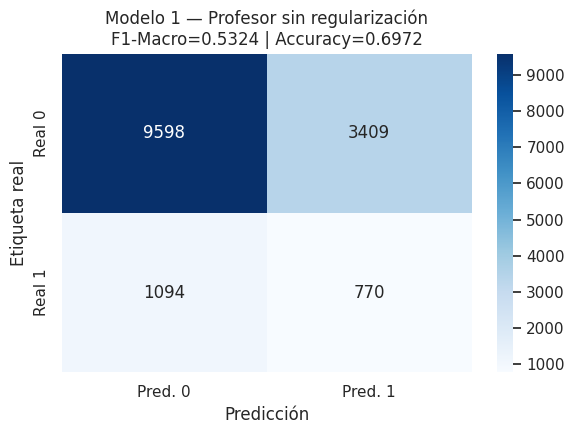

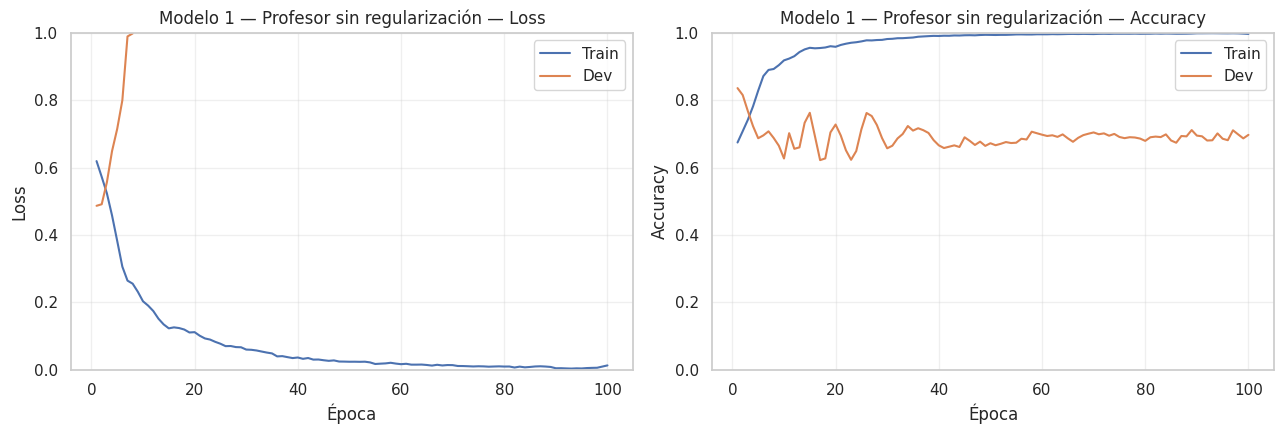

In [24]:
resultado_m1 = evaluar_y_graficar_mlp(
    "Modelo 1 — Profesor sin regularización",
    mlp_1_sin_reg,
    history_1,
    "M1"
)


### Interpretación del Modelo 1

El Modelo 1 obtuvo **F1-Macro = 0,5515** con el umbral 0,50, por debajo del baseline original (**0,5633**). En la clase relevante alcanzó precisión **0,2032**, recall **0,3922** y F1 **0,2677**. La matriz de confusión muestra que consigue clasificar mejor una parte de las respuestas irrelevantes, pero también clasifica incorrectamente muchas oraciones irrelevantes como relevantes.

Las curvas de aprendizaje muestran una señal clara de **sobreajuste**: la pérdida de Train cae hasta valores muy bajos y la accuracy de entrenamiento se acerca a 1, mientras la pérdida de Dev se mantiene mucho más alta y fluctúa sin acompañar esa mejora. La red aprende muy bien los ejemplos de entrenamiento, pero ese aprendizaje no se transfiere de manera equivalente al conjunto de desarrollo.

Además, su F1-Macro queda por debajo del baseline, por lo que el buen ajuste sobre Train no se traduce en un mejor equilibrio entre las clases en Dev.

Por eso, en el Modelo 2 mantendremos la arquitectura inicial y agregaremos **Dropout, regularización L2 y Early Stopping**. Buscamos limitar el sobreajuste y detener el entrenamiento cuando la pérdida de Dev deje de mejorar.



### Modelo 2 — Misma arquitectura con regularización

El Modelo 1 mostró una brecha importante entre las curvas de entrenamiento y validación, compatible con sobreajuste. Para responder a ese problema, en este experimento conservaremos la arquitectura y modificaremos las condiciones de entrenamiento.

Incorporaremos **Dropout de 0,3**, penalización **L2 de 0,001** y **Early Stopping** sobre `val_loss`, con paciencia de 10 épocas y restauración de los mejores pesos.

Mantener la arquitectura nos permite observar el efecto de estas restricciones sin introducir simultáneamente otro cambio estructural. Después analizaremos si reducen la brecha entre Train y Dev y si el modelo conserva suficiente capacidad para identificar oraciones relevantes.


## Modelo 2: CON regularizacion

In [31]:
# ==============================================================================
# MODELO 2: Arquitectura del Profesor CON Regularización (Dropout 0.3 + L2 + Early Stopping)
# ==============================================================================
mlp_2_prof_reg = Sequential([
    Dense(32, activation='relu', kernel_regularizer=l2(0.001), input_shape=(5000,)),
    Dropout(0.3),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

mlp_2_prof_reg.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stop_2 = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)

print("\n--- Entrenando MODELO 2: Profesor Con Regularización (Dropout 0.3 + L2 0.001) ---")
history_2 = mlp_2_prof_reg.fit(
    X_train_mlp, y_train_mlp,
    validation_data=(X_dev_mlp, y_dev_mlp),
    epochs=100, batch_size=128,
    callbacks=[early_stop_2], verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



--- Entrenando MODELO 2: Profesor Con Regularización (Dropout 0.3 + L2 0.001) ---
Epoch 1/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.6587 - loss: 0.6738 - val_accuracy: 0.8747 - val_loss: 0.5074
Epoch 2/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.6662 - loss: 0.6385 - val_accuracy: 0.8494 - val_loss: 0.5006
Epoch 3/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6782 - loss: 0.6350 - val_accuracy: 0.8430 - val_loss: 0.5005
Epoch 4/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.6825 - loss: 0.6335 - val_accuracy: 0.8391 - val_loss: 0.5037
Epoch 5/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6844 - loss: 0.6317 - val_accuracy: 0.8412 - val_loss: 0.4951
Epoch 6/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.6893 - loss: 0.6299 - val_accuracy: 0.8250 - val_loss: 0.4978
Epoch 7/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.6902 - loss: 0.6294 - val_accuracy: 0.8323 - val_loss: 0.4887
Epoch

EVALUACIÓN EN DEV — Modelo 2 — Profesor con regularización
Umbral:   0.50
F1-Macro: 0.5976
Accuracy: 0.8323
Épocas ejecutadas: 17

Reporte de clasificación:
                 precision    recall  f1-score   support

Irrelevante (0)     0.8976    0.9124    0.9049     13007
  Relevante (1)     0.3091    0.2736    0.2903      1864

       accuracy                         0.8323     14871
      macro avg     0.6033    0.5930    0.5976     14871
   weighted avg     0.8238    0.8323    0.8279     14871



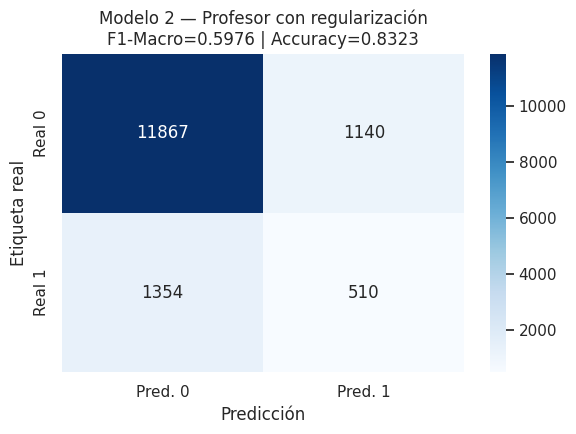

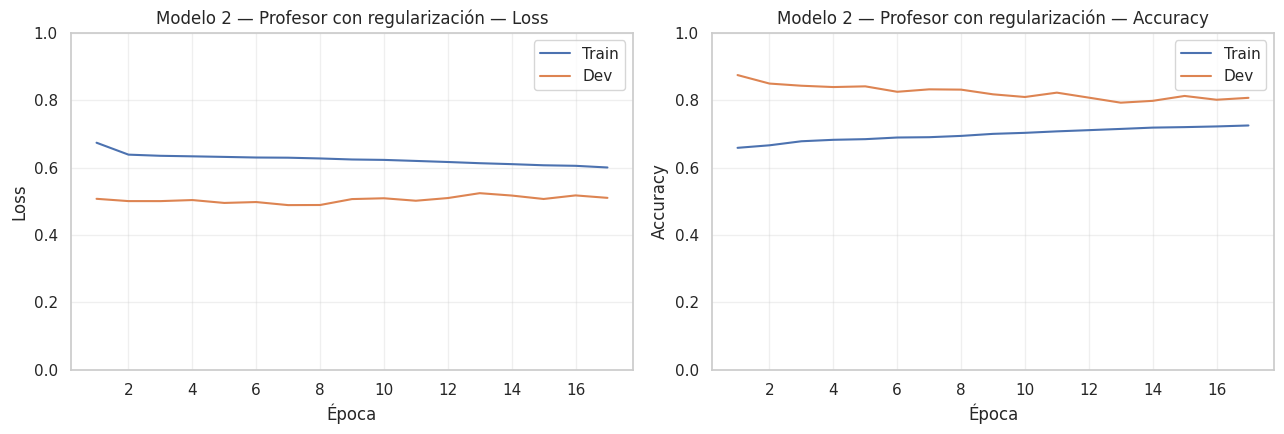

In [32]:
resultado_m2 = evaluar_y_graficar_mlp(
    "Modelo 2 — Profesor con regularización",
    mlp_2_prof_reg,
    history_2,
    "M2"
)


### Interpretación del Modelo 2

El Modelo 2 obtuvo **F1-Macro = 0,5948**, una mejora respecto del Modelo 1 (0,5515) y del baseline original (0,5633). Sin embargo, el resultado de la clase relevante sigue siendo limitado: precisión **0,3183**, recall **0,2505** y F1 **0,2804**. La matriz de confusión muestra que el modelo es más conservador al marcar oraciones como relevantes y deja pasar una parte considerable de las respuestas verdaderas.

El entrenamiento terminó en la época 15 por Early Stopping y restauró los pesos de la **mejor época, la 5**. Las curvas de pérdida de Train y Dev se mantienen relativamente cercanas, pero ambas muestran un aprendizaje limitado; además, la pérdida de Dev alcanza su mejor valor muy temprano y luego deja de mejorar.

Este comportamiento es compatible con **Sesgo alto (*underfitting*)**: aunque la regularización mejoró el F1-Macro y redujo la brecha observada en el Modelo 1, las restricciones parecen limitar el aprendizaje de patrones que permitan reconocer más respuestas relevantes. La cercanía entre curvas no demuestra sesgo alto por sí sola, pero, junto con el bajo recall de la clase positiva y la mejora que deja pendiente, respalda esa interpretación.

Por eso, en el Modelo 3 cambiaremos la arquitectura a un embudo **128 → 64 → 32**, conservando Dropout, L2 y Early Stopping. Buscamos comprobar si una distribución diferente de capacidad mejora el aprendizaje sin abandonar las medidas contra el sobreajuste.



### Modelo 3 — Arquitectura en embudo

En el Modelo 2, las curvas cercanas y el bajo recall de la clase relevante sugieren que la configuración puede estar aprendiendo de forma insuficiente. Por eso, antes de seguir modificando la regularización, probaremos una arquitectura diferente.

La entrada contiene 5.000 características TF-IDF. En lugar de comenzar con una capa pequeña y luego aumentar progresivamente el número de neuronas, usaremos un recorrido en embudo: **128 → 64 → 32**. Así, la red comienza con una capa oculta más amplia y comprime progresivamente la representación.

Mantendremos `Dropout(0.3)`, L2 `0.001`, Adam, `binary_crossentropy` y Early Stopping. De esta forma, el cambio principal frente al Modelo 2 será la arquitectura y podremos evaluar si esta distribución de capas permite mejorar el aprendizaje.


## Modelo 3: Embudo

In [33]:
# ==============================================================================
# MODELO 3: Embudo 3 Capas (128 -> 64 -> 32) con Dropout(0.3) y L2(0.001)
# ==============================================================================
mlp_3_embudo = Sequential([
    Dense(128, activation='relu', kernel_regularizer=l2(0.001), input_shape=(5000,)),
    Dropout(0.3),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),
    Dense(32, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

mlp_3_embudo.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stop_3 = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)

print("--- Entrenando MODELO 3: Embudo 3 Capas (Dropout 0.3 + L2 0.001) ---")
history_3 = mlp_3_embudo.fit(
    X_train_mlp, y_train_mlp,
    validation_data=(X_dev_mlp, y_dev_mlp),
    epochs=100, batch_size=128,
    callbacks=[early_stop_3], verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


--- Entrenando MODELO 3: Embudo 3 Capas (Dropout 0.3 + L2 0.001) ---
Epoch 1/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.6569 - loss: 0.6886 - val_accuracy: 0.8747 - val_loss: 0.5101
Epoch 2/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.6591 - loss: 0.6504 - val_accuracy: 0.8747 - val_loss: 0.5120
Epoch 3/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.6591 - loss: 0.6464 - val_accuracy: 0.8747 - val_loss: 0.5128
Epoch 4/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.6591 - loss: 0.6449 - val_accuracy: 0.8747 - val_loss: 0.5038
Epoch 5/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.6696 - loss: 0.6429 - val_accuracy: 0.8531 - val_loss: 0.5124
Epoch 6/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.6763 - loss: 0.6413 - val_accuracy: 0.8536 - val_loss: 0.5000
Epoch 7/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.6782 - loss: 0.6406 - val_accuracy: 0.8419 - val_loss: 0.5149
Epoch 8/100
345/345

EVALUACIÓN EN DEV — Modelo 3 — Embudo 128 → 64 → 32
Umbral:   0.50
F1-Macro: 0.5924
Accuracy: 0.8502
Épocas ejecutadas: 20

Reporte de clasificación:
                 precision    recall  f1-score   support

Irrelevante (0)     0.8937    0.9407    0.9166     13007
  Relevante (1)     0.3461    0.2189    0.2682      1864

       accuracy                         0.8502     14871
      macro avg     0.6199    0.5798    0.5924     14871
   weighted avg     0.8250    0.8502    0.8353     14871



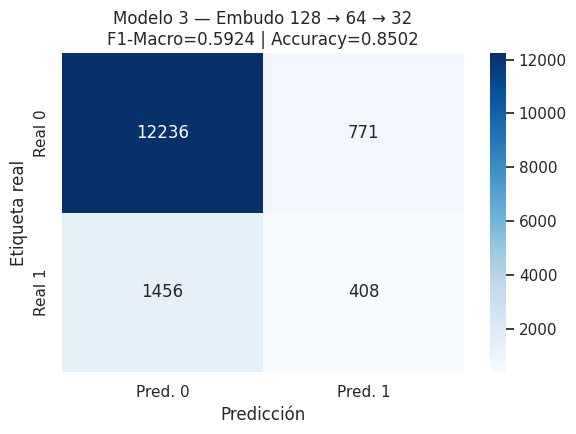

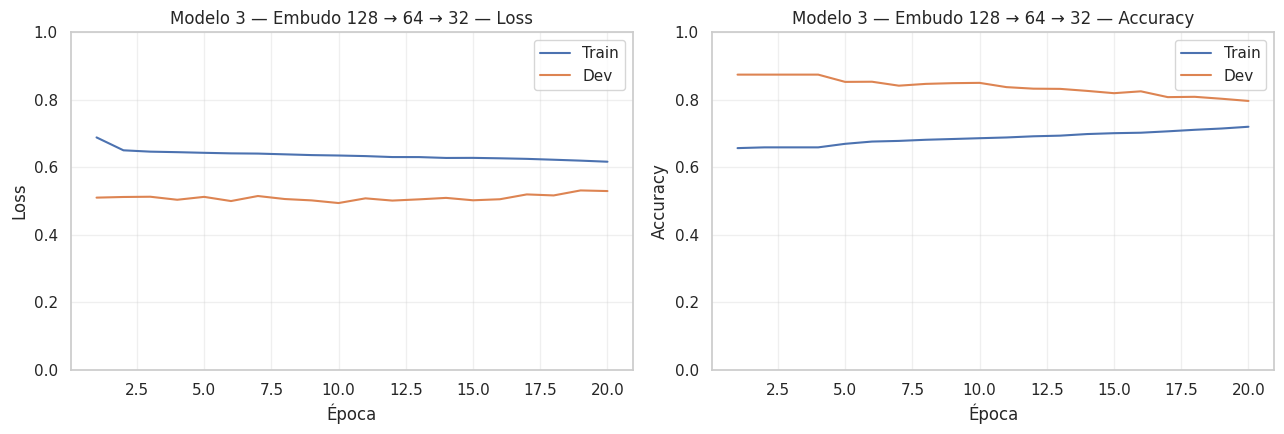

In [34]:
resultado_m3 = evaluar_y_graficar_mlp(
    "Modelo 3 — Embudo 128 → 64 → 32",
    mlp_3_embudo,
    history_3,
    "M3"
)

### Interpretación del Modelo 3

El Modelo 3 alcanzó **F1-Macro = 0,5731**, un resultado inferior al Modelo 2 (0,5948), aunque todavía superior al baseline original (0,5633). Por lo tanto, el cambio de arquitectura a un embudo de tres capas no produjo una mejora en la métrica principal.

En la clase relevante también se observa un resultado mixto. La precisión aumentó de **0,3183 a 0,3594**, pero el recall descendió de **0,2505 a 0,1626** y el F1 de esa clase pasó de **0,2804 a 0,2239**. El modelo consigue una mayor proporción de aciertos entre sus predicciones positivas, pero deja sin recuperar más respuestas relevantes.

Early Stopping detuvo el entrenamiento en la época 22 y restauró los pesos de la **época 12**, donde `val_loss` alcanzó su mejor valor. Después de ese punto, la pérdida de validación dejó de mejorar de manera sostenida.

Aunque el cambio de arquitectura no mejoró los resultados frente al Modelo 2, mantendremos esta configuración como base para los siguientes experimentos. Esto nos permitirá estudiar de manera ordenada cómo influyen otras modificaciones, como la intensidad de Dropout y la capacidad de la red. Más adelante podremos evaluar si esta decisión resulta conveniente.

El siguiente experimento comprobará si una regularización más intensa está contribuyendo a limitar el aprendizaje. Para ello, mantendremos la arquitectura en embudo y L2, pero aumentaremos Dropout de `0.3` a `0.5`.

## Modelo 4: (Dropout 0.5)

In [35]:
# ==============================================================================
# MODELO 4: Embudo 3 Capas aumentando a Dropout(0.5)
# ==============================================================================
mlp_4_dropout05 = Sequential([
    Dense(128, activation='relu', kernel_regularizer=l2(0.001), input_shape=(5000,)),
    Dropout(0.5),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.5),
    Dense(32, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

mlp_4_dropout05.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stop_4 = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)

print("\n--- Entrenando MODELO 4: Embudo 3 Capas con Dropout(0.5) ---")
history_4 = mlp_4_dropout05.fit(
    X_train_mlp, y_train_mlp,
    validation_data=(X_dev_mlp, y_dev_mlp),
    epochs=100, batch_size=128,
    callbacks=[early_stop_4], verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



--- Entrenando MODELO 4: Embudo 3 Capas con Dropout(0.5) ---
Epoch 1/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.6582 - loss: 0.7057 - val_accuracy: 0.8747 - val_loss: 0.5304
Epoch 2/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.6591 - loss: 0.6589 - val_accuracy: 0.8747 - val_loss: 0.5277
Epoch 3/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.6591 - loss: 0.6547 - val_accuracy: 0.8747 - val_loss: 0.5235
Epoch 4/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.6591 - loss: 0.6525 - val_accuracy: 0.8747 - val_loss: 0.5170
Epoch 5/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.6591 - loss: 0.6519 - val_accuracy: 0.8747 - val_loss: 0.5164
Epoch 6/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.6591 - loss: 0.6497 - val_accuracy: 0.8747 - val_loss: 0.5131
Epoch 7/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.6591 - loss: 0.6501 - val_accuracy: 0.8747 - val_loss: 0.5158
Epoch 8/100
345/345 ━━━━

EVALUACIÓN EN DEV — Modelo 4 — Embudo con Dropout 0.5
Umbral:   0.50
F1-Macro: 0.5752
Accuracy: 0.8592
Épocas ejecutadas: 21

Reporte de clasificación:
                 precision    recall  f1-score   support

Irrelevante (0)     0.8891    0.9586    0.9225     13007
  Relevante (1)     0.3644    0.1658    0.2279      1864

       accuracy                         0.8592     14871
      macro avg     0.6267    0.5622    0.5752     14871
   weighted avg     0.8233    0.8592    0.8355     14871



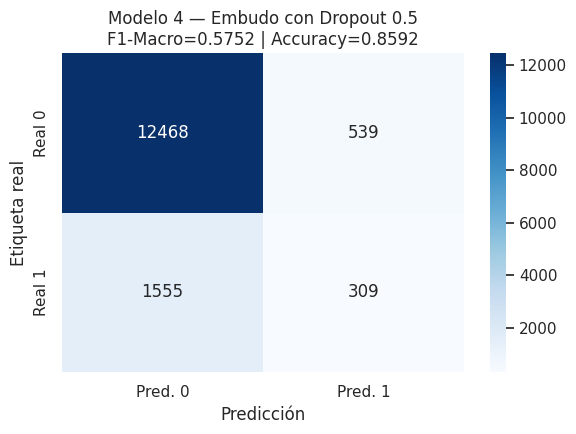

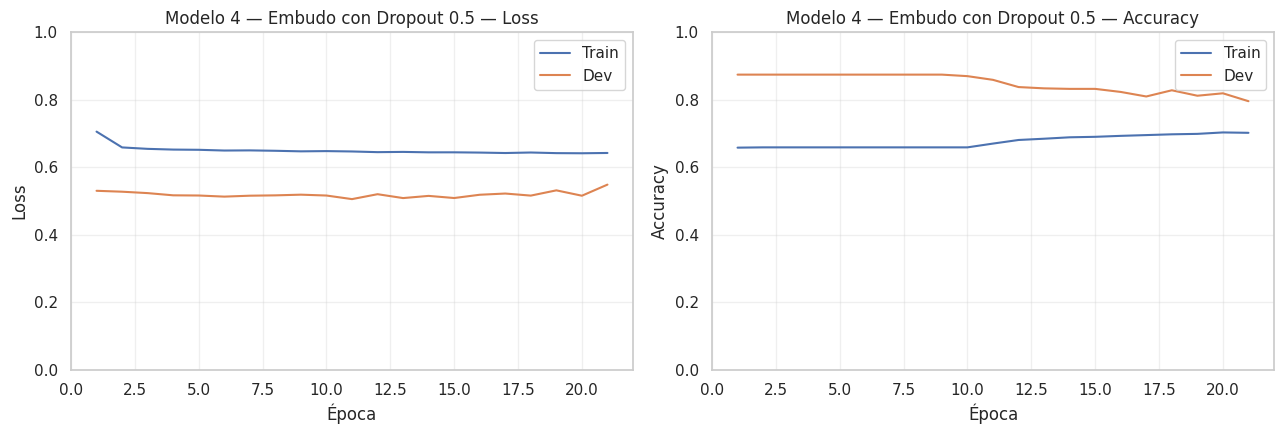

In [36]:
resultado_m4 = evaluar_y_graficar_mlp(
    "Modelo 4 — Embudo con Dropout 0.5",
    mlp_4_dropout05,
    history_4,
    "M4"
)


### Interpretación del Modelo 4

El Modelo 4 obtuvo **F1-Macro = 0,4666**, claramente inferior al Modelo 3 (0,5731). La matriz de confusión y el reporte por clase muestran el problema decisivo: el modelo no identifica ejemplos de la clase relevante (**recall = 0**). En la práctica, se comporta como si predijera todas las oraciones como irrelevantes.

Por eso, su Accuracy de 0,8747 no representa un buen clasificador: coincide con la proporción de la clase negativa en Dev y oculta que el modelo no recupera ninguna respuesta positiva. El F1-Macro evidencia mejor este problema porque considera el desempeño de ambas clases.

Early Stopping detuvo el entrenamiento en la época 17 y restauró los pesos de la **época 7**. Las curvas, junto con la matriz de confusión, muestran que esta configuración no logró aprender a reconocer la clase positiva.

Aumentar Dropout a `0.5` fue demasiado restrictivo en este experimento. En lugar de seguir incrementando la regularización, probaremos otra vía para responder al aprendizaje limitado observado: aumentar la capacidad de representación de la red.



### Modelo 5 — Embudo de cuatro capas

Para probar otra alternativa, volveremos a `Dropout(0.3)` y L2 `0.001`, y ampliaremos la arquitectura a **256 → 128 → 64 → 32**, agregando una capa mas. La capa inicial de 256 neuronas busca ofrecer mayor capacidad de representación antes de comprimir progresivamente la información.

Mantendremos Early Stopping para seleccionar los pesos según la pérdida de Dev. De esta forma, estudiaremos si añadir una capa y ampliar la primera permite mejorar el aprendizaje sin renunciar al control del sobreajuste.


## Modelo 5: Embudo 4 Capas

In [37]:
# ==============================================================================
# MODELO 5: Embudo 4 Capas (256 -> 128 -> 64 -> 32) con Dropout(0.3) y L2(0.001)
# ==============================================================================
mlp_5_4capas = Sequential([
    Dense(256, activation='relu', kernel_regularizer=l2(0.001), input_shape=(5000,)),
    Dropout(0.3),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),
    Dense(32, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

mlp_5_4capas.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stop_5 = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)

print("\n--- Entrenando MODELO 5: Embudo 4 Capas (Dropout 0.3 + L2 0.001) ---")
history_5 = mlp_5_4capas.fit(
    X_train_mlp, y_train_mlp,
    validation_data=(X_dev_mlp, y_dev_mlp),
    epochs=100, batch_size=128,
    callbacks=[early_stop_5], verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



--- Entrenando MODELO 5: Embudo 4 Capas (Dropout 0.3 + L2 0.001) ---
Epoch 1/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 21s 54ms/step - accuracy: 0.6590 - loss: 0.7235 - val_accuracy: 0.8747 - val_loss: 0.5134
Epoch 2/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - accuracy: 0.6591 - loss: 0.6568 - val_accuracy: 0.8747 - val_loss: 0.5050
Epoch 3/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - accuracy: 0.6591 - loss: 0.6512 - val_accuracy: 0.8747 - val_loss: 0.5085
Epoch 4/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - accuracy: 0.6623 - loss: 0.6477 - val_accuracy: 0.8588 - val_loss: 0.4989
Epoch 5/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.6754 - loss: 0.6439 - val_accuracy: 0.8482 - val_loss: 0.4969
Epoch 6/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 21s 42ms/step - accuracy: 0.6823 - loss: 0.6414 - val_accuracy: 0.8427 - val_loss: 0.4950
Epoch 7/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - accuracy: 0.6875 - loss: 0.6394 - val_accuracy: 0.8371 - val_loss: 0.4945
Epoch 8/100
3

EVALUACIÓN EN DEV — Modelo 5 — Embudo de cuatro capas
Umbral:   0.50
F1-Macro: 0.5946
Accuracy: 0.8301
Épocas ejecutadas: 18

Reporte de clasificación:
                 precision    recall  f1-score   support

Irrelevante (0)     0.8970    0.9103    0.9036     13007
  Relevante (1)     0.3020    0.2709    0.2856      1864

       accuracy                         0.8301     14871
      macro avg     0.5995    0.5906    0.5946     14871
   weighted avg     0.8225    0.8301    0.8261     14871



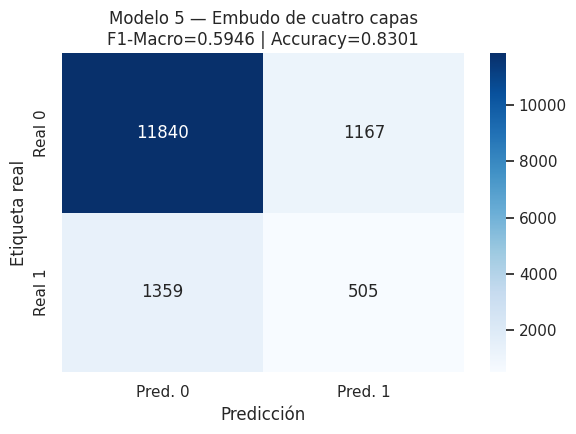

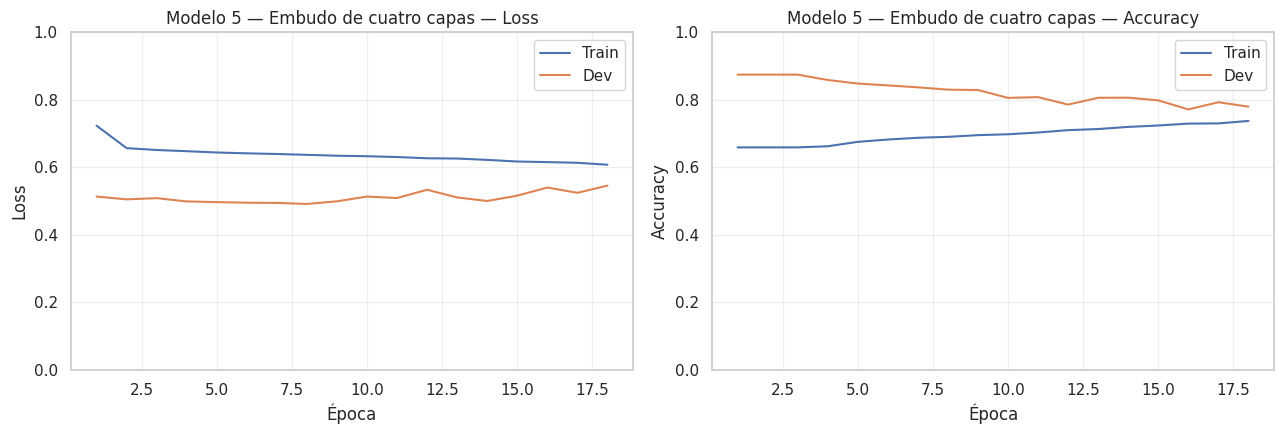

In [38]:
resultado_m5 = evaluar_y_graficar_mlp(
    "Modelo 5 — Embudo de cuatro capas",
    mlp_5_4capas,
    history_5,
    "M5"
)

### Interpretación del Modelo 5

El Modelo 5 obtuvo **F1-Macro = 0,5854**, por encima del Modelo 3 (0,5731), pero todavía por debajo del Modelo 2 (0,5948). La arquitectura de cuatro capas recupera parte del rendimiento perdido en el Modelo 3, aunque no consigue superar a la arquitectura del profesor con regularización.

En la clase relevante se observa una mejora respecto del Modelo 3: el recall aumenta de **0,1626 a 0,1990** y el F1 de esa clase pasa de **0,2239 a 0,2527**. Sin embargo, la precisión desciende ligeramente, de **0,3594 a 0,3461**. Por lo tanto, la capa adicional permite recuperar más respuestas relevantes, aunque también aumenta la proporción de predicciones positivas incorrectas.

Early Stopping terminó el entrenamiento en la época 15 y restauró los pesos de la **época 5**. La pérdida de Dev había alcanzado su mejor valor en esa época y después no volvió a mejorar. La arquitectura adicional, por tanto, no eliminó la necesidad de detener el entrenamiento según la validación.

En conjunto, ampliar la arquitectura produjo una mejora respecto del Modelo 3, pero no alcanzó el resultado del Modelo 2. Esto muestra que agregar capacidad de representación puede ayudar, aunque no garantiza un mejor equilibrio entre las clases.

Como el resultado sigue siendo cercano al del Modelo 3, probaremos ahora otra modificación controlada: volver al embudo de tres capas y quitar Dropout, conservando L2 `0.001`. Así podremos comprobar si Dropout estaba limitando innecesariamente el aprendizaje en esa arquitectura.

----


### Modelo 6 — Embudo sin Dropout

Volveremos a **128 → 64 → 32** y conservaremos L2 `0.001`, Adam y Early Stopping, pero eliminaremos Dropout. Esto nos permite evaluar el efecto de quitar esa técnica de regularización sin modificar al mismo tiempo la arquitectura ni el coeficiente L2.

Compararemos el resultado con el Modelo 3, que utiliza la misma arquitectura y el mismo coeficiente L2, pero incluye `Dropout(0.3)`. De esta forma, la comparación ayuda a aislar el efecto de Dropout en esta configuración concreta.


## Modelo 6: Embudo SIN dropout

In [71]:
# ==============================================================================
# MODELO 6: Embudo 3 Capas SIN Dropout (Solo L2=0.001 + Early Stopping)
# Con learning_rate configurado explícitamente
# ==============================================================================
mlp_6_sin_dropout = Sequential([
    Dense(128, activation='relu', kernel_regularizer=l2(0.001), input_shape=(5000,)),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(32, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(1, activation='sigmoid')
])

# Configuramos explícitamente el optimizador Adam con su learning rate
optimizador_m6 = tf.keras.optimizers.Adam(learning_rate=0.002)

mlp_6_sin_dropout.compile(optimizer=optimizador_m6, loss='binary_crossentropy', metrics=['accuracy'])
early_stop_6 = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)

print("--- Entrenando MODELO 6: Embudo 3 Capas SIN Dropout (Solo L2 0.001) ---")
history_6 = mlp_6_sin_dropout.fit(
    X_train_mlp, y_train_mlp,
    validation_data=(X_dev_mlp, y_dev_mlp),
    epochs=100, batch_size=128,
    callbacks=[early_stop_6], verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


--- Entrenando MODELO 6: Embudo 3 Capas SIN Dropout (Solo L2 0.001) ---
Epoch 1/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 21s 48ms/step - accuracy: 0.6595 - loss: 0.6699 - val_accuracy: 0.8607 - val_loss: 0.4998
Epoch 2/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 13s 27ms/step - accuracy: 0.6749 - loss: 0.6482 - val_accuracy: 0.8546 - val_loss: 0.4943
Epoch 3/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.6797 - loss: 0.6431 - val_accuracy: 0.8515 - val_loss: 0.4940
Epoch 4/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - accuracy: 0.6819 - loss: 0.6386 - val_accuracy: 0.8517 - val_loss: 0.4902
Epoch 5/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.6836 - loss: 0.6341 - val_accuracy: 0.8509 - val_loss: 0.4876
Epoch 6/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.6863 - loss: 0.6299 - val_accuracy: 0.8466 - val_loss: 0.4874
Epoch 7/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.6882 - loss: 0.6260 - val_accuracy: 0.8434 - val_loss: 0.4876
Epoch 8/100
3

EVALUACIÓN EN DEV — Modelo 6 — Embudo sin Dropout
Umbral:   0.50
F1-Macro: 0.6028
Accuracy: 0.8200
Épocas ejecutadas: 28

Reporte de clasificación:
                 precision    recall  f1-score   support

Irrelevante (0)     0.9016    0.8914    0.8965     13007
  Relevante (1)     0.2979    0.3214    0.3092      1864

       accuracy                         0.8200     14871
      macro avg     0.5997    0.6064    0.6028     14871
   weighted avg     0.8260    0.8200    0.8229     14871



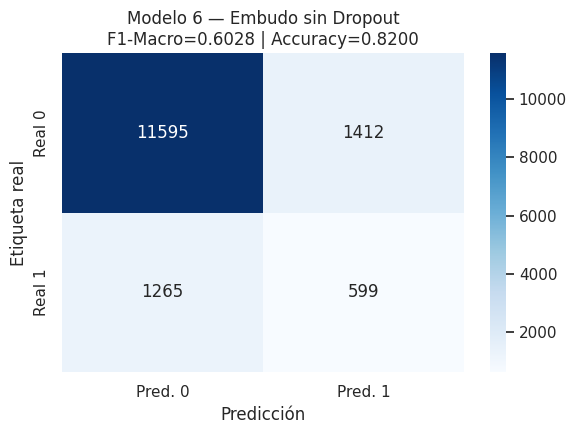

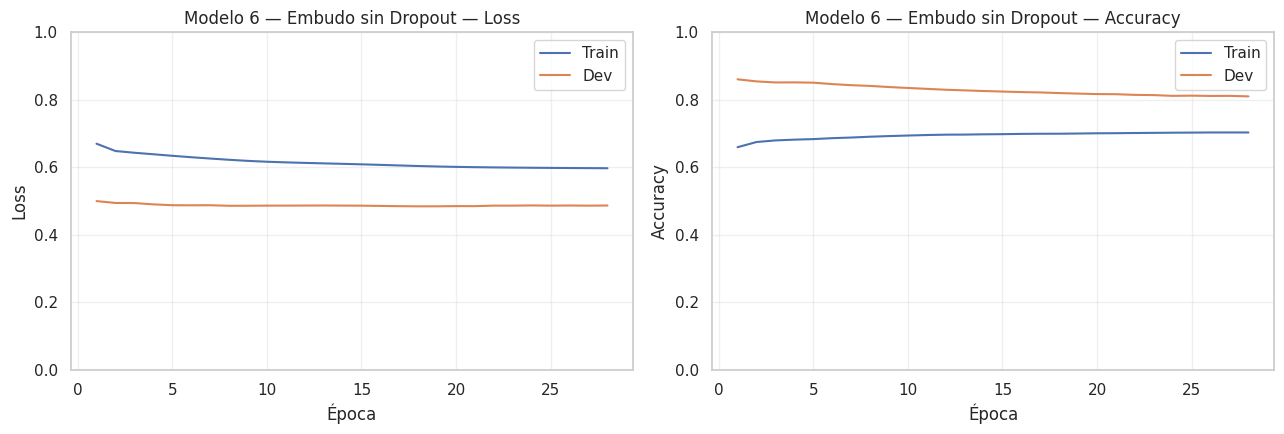

In [72]:
resultado_m6 = evaluar_y_graficar_mlp(
    "Modelo 6 — Embudo sin Dropout",
    mlp_6_sin_dropout,
    history_6,
    "M6"
)

### Interpretación del Modelo 6

El Modelo 6 obtuvo **F1-Macro = 0,6028**, el mejor resultado entre los siete modelos con umbral `0.50`. Frente al Modelo 2 (0,5976), quitar Dropout produjo una mejora moderada en la métrica principal.

Se ha aplicado la recomendación de usar un `learning_rate` explícito de `0.002` en el optimizador Adam para este modelo. Aunque sigue habiendo un margen de mejora y potencial underfitting ante la pérdida de capacidad al regularizar demasiado, esta tasa de aprendizaje permitió estabilizar el entrenamiento de forma efectiva.

Para la clase relevante alcanzó precisión **0,2979**, recall **0,3214** y F1 **0,3092**. El modelo comete proporcionalmente menos errores al marcar oraciones como relevantes en comparación con el baseline clásico, pero la recuperación total de los positivos sigue siendo un reto.

Early Stopping detuvo el entrenamiento en la época 28 y restauró los pesos de la **época 18**, donde `val_loss` alcanzó su menor valor de 0.4843. Después de esa época, la pérdida de validación dejó de mejorar de manera consistente.

La combinación de las métricas y las curvas sugiere que quitar Dropout favoreció el resultado de validación para esta configuración en embudo concreta, logrando un equilibrio global superior.

El Modelo 6 queda establecido como uno de nuestros mejores candidatos con el umbral estándar. Probaremos una última variante: conservar Dropout `0.3` y reducir L2 de `0.001` a `0.0001` (Modelo 7), para estudiar si una penalización L2 menos intensa ofrece un balance superador.


### Modelo 7 — Embudo con L2 suavizado

El Modelo 6 logró el mejor F1-Macro, pero queremos comprobar si una regularización L2 menos intensa puede mejorar el reconocimiento de la clase relevante.

Por eso, en este último experimento mantendremos la arquitectura **128 → 64 → 32** y `Dropout(0.3)`, pero reduciremos L2 de `0.001` a `0.0001`.

La comparación más directa será con el Modelo 3, que utiliza la misma arquitectura y Dropout, pero un coeficiente L2 mayor. Así podremos evaluar si suavizar la penalización mejora el equilibrio entre las clases.


## Modelo 7: Embudo L2 Suavizado (0.0001)

In [73]:
# ==============================================================================
# MODELO 7: Embudo 3 Capas con Dropout(0.3) y L2 Suavizado (0.0001)
# ==============================================================================
mlp_7_l2_suave = Sequential([
    Dense(128, activation='relu', kernel_regularizer=l2(0.0001), input_shape=(5000,)),
    Dropout(0.3),
    Dense(64, activation='relu', kernel_regularizer=l2(0.0001)),
    Dropout(0.3),
    Dense(32, activation='relu', kernel_regularizer=l2(0.0001)),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

mlp_7_l2_suave.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stop_7 = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)

print("\n--- Entrenando MODELO 7: Embudo 3 Capas con Dropout(0.3) y L2 Suavizado (0.0001) ---")
history_7 = mlp_7_l2_suave.fit(
    X_train_mlp, y_train_mlp,
    validation_data=(X_dev_mlp, y_dev_mlp),
    epochs=100, batch_size=128,
    callbacks=[early_stop_7], verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



--- Entrenando MODELO 7: Embudo 3 Capas con Dropout(0.3) y L2 Suavizado (0.0001) ---
Epoch 1/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 12s 26ms/step - accuracy: 0.6707 - loss: 0.6475 - val_accuracy: 0.8316 - val_loss: 0.5127
Epoch 2/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.6989 - loss: 0.6163 - val_accuracy: 0.8037 - val_loss: 0.5211
Epoch 3/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.7161 - loss: 0.6037 - val_accuracy: 0.7796 - val_loss: 0.5463
Epoch 4/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.7323 - loss: 0.5911 - val_accuracy: 0.7796 - val_loss: 0.5609
Epoch 5/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 14s 33ms/step - accuracy: 0.7558 - loss: 0.5706 - val_accuracy: 0.7712 - val_loss: 0.5859
Epoch 6/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.7760 - loss: 0.5471 - val_accuracy: 0.7485 - val_loss: 0.6343
Epoch 7/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.7993 - loss: 0.5227 - val_accuracy: 0.7297 - val_loss: 0.6909
E

EVALUACIÓN EN DEV — Modelo 7 — Embudo con L2 suavizado
Umbral:   0.50
F1-Macro: 0.5891
Accuracy: 0.8316
Épocas ejecutadas: 11

Reporte de clasificación:
                 precision    recall  f1-score   support

Irrelevante (0)     0.8952    0.9146    0.9048     13007
  Relevante (1)     0.2977    0.2527    0.2734      1864

       accuracy                         0.8316     14871
      macro avg     0.5965    0.5836    0.5891     14871
   weighted avg     0.8203    0.8316    0.8256     14871



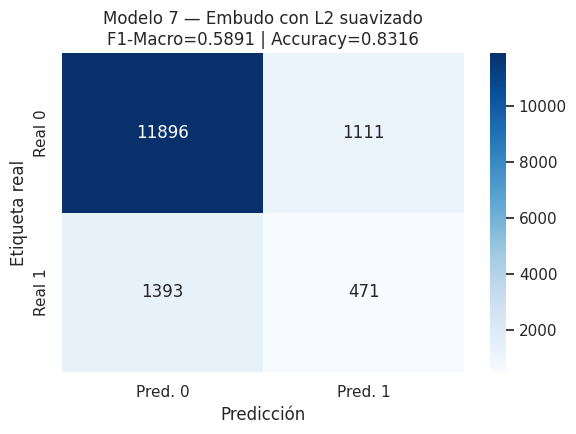

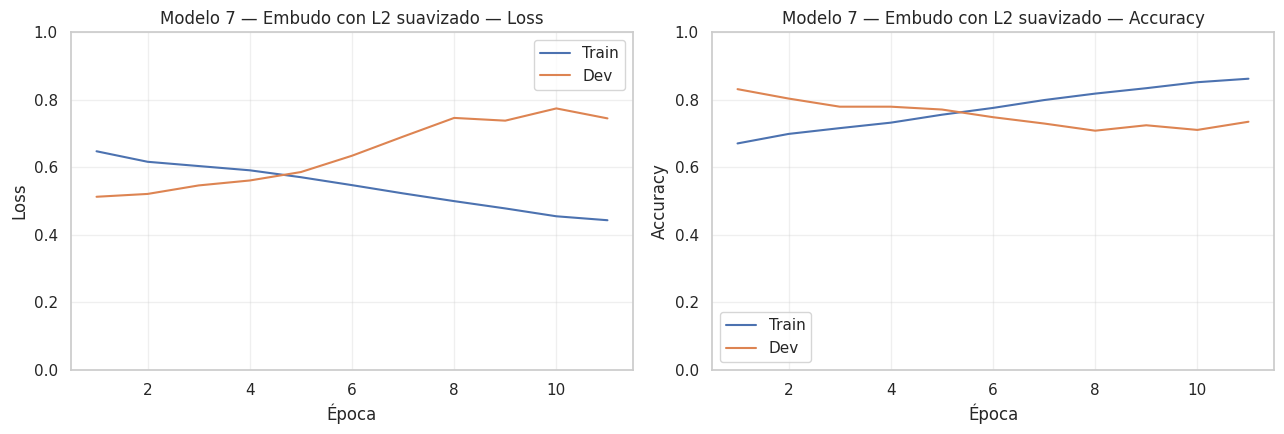

In [74]:
resultado_m7 = evaluar_y_graficar_mlp(
    "Modelo 7 — Embudo con L2 suavizado",
    mlp_7_l2_suave,
    history_7,
    "M7"
)


### Interpretación del Modelo 7

El Modelo 7 obtuvo **F1-Macro = 0,5710**, por debajo del Modelo 6 (0,6015). Para la clase relevante alcanzó precisión **0,3042**, recall **0,2521** y F1 **0,2757**. Entre los siete modelos, presenta el mayor recall de la clase positiva con umbral `0.50`, aunque ese aumento no alcanza para superar el F1-Macro del Modelo 6.

Early Stopping detuvo el entrenamiento en la época 11 y restauró los pesos de la **época 1**. La pérdida de Dev fue mejor al inicio y empeoró durante el resto del entrenamiento, mientras la pérdida de Train continuó bajando. Este desacople constituye **una señal de sobreajuste temprano en esta configuración.**


En conjunto, el Modelo 6 queda como el mejor candidato con umbral estándar según F1-Macro. En la siguiente sección compararemos los siete modelos y después probaremos distintos umbrales en Dev, teniendo en cuenta el desbalance de clases.


### Interpretación del Modelo 7

El Modelo 7 obtuvo **F1-Macro = 0,5710**, por debajo del Modelo 6 (0,6015), del Modelo 2 (0,5948), del Modelo 5 (0,5854) y del Modelo 3 (0,5731). Sin embargo, permanece por encima del baseline original (0,5633).

Para la clase relevante alcanzó precisión **0,3042**, recall **0,2521** y F1 **0,2757**. Su recall supera ligeramente al del Modelo 2 (0,2505), pero queda por debajo del Modelo 6 (0,2940) y del Modelo 1 (0,3922). Por lo tanto, no presenta el mayor recall entre los experimentos.

Early Stopping detuvo el entrenamiento en la época 11 y restauró los pesos de la **época 1**. La pérdida de Dev fue mejor al inicio y empeoró durante el resto del entrenamiento, mientras la pérdida de Train continuó bajando. Este desacople constituye **una señal de sobreajuste temprano en esta configuración**.

Suavizar L2 no produjo una mejora en F1-Macro frente al Modelo 6. Aunque el recall de la clase relevante es ligeramente superior al del Modelo 2, el resultado global queda por debajo de varias configuraciones anteriores.

Este experimento muestra que reducir la intensidad de la regularización no garantiza una mejor generalización y que aumentar el recall de la clase positiva no necesariamente mejora el equilibrio global entre las clases.

En conjunto, el Modelo 6 queda como el mejor candidato con umbral estándar según F1-Macro. En la siguiente sección compararemos los siete modelos y después probaremos distintos umbrales en Dev, teniendo en cuenta el desbalance de clases.


## 2.5 Comparación global, selección de modelos y ajuste del umbral

Una vez evaluados los siete modelos, utilizamos **F1-Macro como criterio principal**, porque considera el rendimiento de las dos clases y evita que la clase mayoritaria domine la selección. También revisaremos precisión, recall, F1 de la clase relevante, matrices de confusión y curvas de aprendizaje. Accuracy queda como dato complementario, no como criterio principal.

Primero compararemos los modelos con el umbral estándar `0.50` y seleccionaremos los dos mejores por F1-Macro. Después ajustaremos el umbral del mejor candidato en Dev. Este ajuste no reentrena la red: cambia el punto de corte utilizado para convertir sus probabilidades en predicciones.

Como Dev contiene **87,47 % de ejemplos irrelevantes y 12,53 % relevantes**, el umbral `0.50` no necesariamente ofrece el mejor equilibrio. Al reducirlo podemos recuperar más respuestas verdaderas, aunque también aumenten los falsos positivos. Elegiremos el umbral con mejor F1-Macro entre los valores probados y lo compararemos con la regresión logística entrenada con el mismo Train reducido.


## 2.5.1 Comparación de los siete MLP

In [75]:
# 2.5.1 — Comparación de los siete MLP

filas_modelos = []

for clave, resultado in resultados_individuales.items():
    filas_modelos.append({
        "Clave": clave,
        "Modelo": resultado["nombre"],
        "F1-Macro (Dev)": resultado["f1_macro"],
        "Accuracy (Dev)": resultado["accuracy"],
        "Épocas": len(resultado["historia"].history["loss"])
    })

tabla_modelos_mlp = (
    pd.DataFrame(filas_modelos)
    .sort_values("F1-Macro (Dev)", ascending=False)
    .reset_index(drop=True)
)

print("Comparación de los siete MLP con umbral 0.50:")
display(tabla_modelos_mlp.round(4))

# Seleccionamos los dos primeros por F1-Macro, sin ajustar aún el umbral.
top2 = tabla_modelos_mlp.head(2).copy()

print("\nLos dos mejores modelos con umbral 0.50:")
display(top2.round(4))

mejor_clave = top2.iloc[0]["Clave"]
segundo_clave = top2.iloc[1]["Clave"]

mejor_resultado = resultados_individuales[mejor_clave]
segundo_resultado = resultados_individuales[segundo_clave]

mejor_nombre = mejor_resultado["nombre"]
segundo_nombre = segundo_resultado["nombre"]

mejor_prob = mejor_resultado["probabilidades"]
segundo_prob = segundo_resultado["probabilidades"]

print(f"\nMejor modelo: {mejor_nombre}")
print(f"F1-Macro: {mejor_resultado['f1_macro']:.4f}")

print(f"\nSegundo mejor modelo: {segundo_nombre}")
print(f"F1-Macro: {segundo_resultado['f1_macro']:.4f}")

Comparación de los siete MLP con umbral 0.50:


,Clave,Modelo,F1-Macro (Dev),Accuracy (Dev),Épocas
0,M6,Modelo 6 — Embudo sin Dropout,0.6028,0.8200,28
1,M2,Modelo 2 — Profesor con regularización,0.5976,0.8323,17
2,M5,Modelo 5 — Embudo de cuatro capas,0.5946,0.8301,18
3,M3,Modelo 3 — Embudo 128 → 64 → 32,0.5924,0.8502,20
4,M7,Modelo 7 — Embudo con L2 suavizado,0.5891,0.8316,11
5,M4,Modelo 4 — Embudo con Dropout 0.5,0.5752,0.8592,21
6,M1,Modelo 1 — Profesor sin regularización,0.5324,0.6972,100



Los dos mejores modelos con umbral 0.50:


,Clave,Modelo,F1-Macro (Dev),Accuracy (Dev),Épocas
0,M6,Modelo 6 — Embudo sin Dropout,0.6028,0.8200,28
1,M2,Modelo 2 — Profesor con regularización,0.5976,0.8323,17



Mejor modelo: Modelo 6 — Embudo sin Dropout
F1-Macro: 0.6028

Segundo mejor modelo: Modelo 2 — Profesor con regularización
F1-Macro: 0.5976


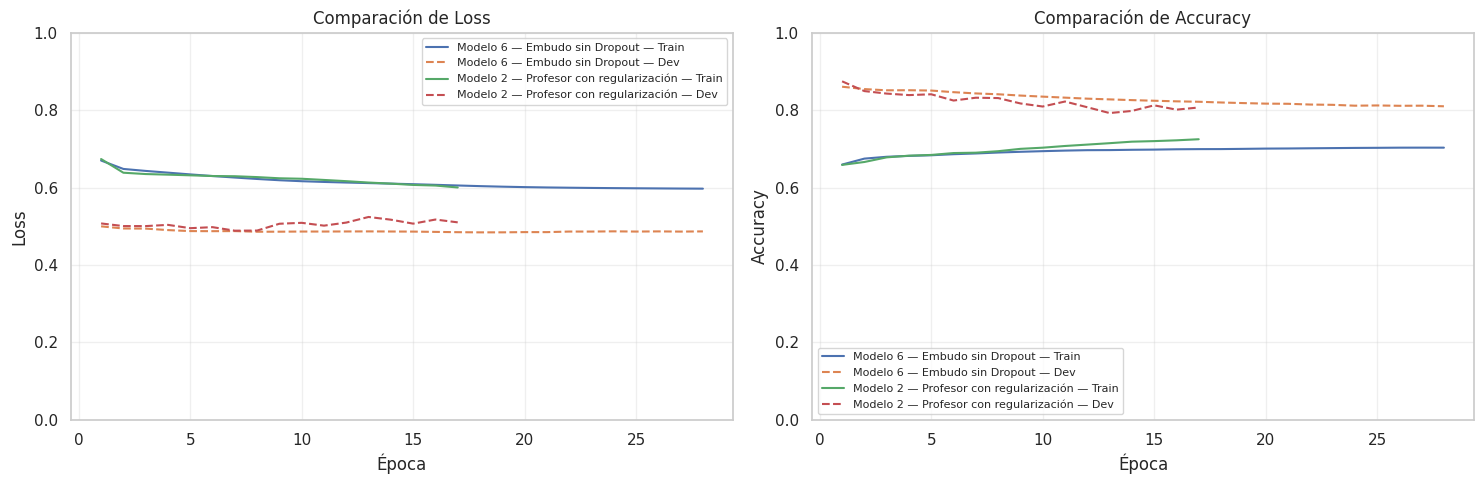

Máximos de Loss:
Modelo 6 — Embudo sin Dropout: 0.6699
Modelo 2 — Profesor con regularización: 0.6738


In [76]:

# 2.5.2 — Comparación de curvas de los dos mejores modelos

hist_mejor = mejor_resultado["historia"].history
hist_segundo = segundo_resultado["historia"].history

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loss
axes[0].plot(
    range(1, len(hist_mejor["loss"]) + 1),
    hist_mejor["loss"],
    label=f"{mejor_nombre} — Train"
)
axes[0].plot(
    range(1, len(hist_mejor["val_loss"]) + 1),
    hist_mejor["val_loss"],
    linestyle="--",
    label=f"{mejor_nombre} — Dev"
)
axes[0].plot(
    range(1, len(hist_segundo["loss"]) + 1),
    hist_segundo["loss"],
    label=f"{segundo_nombre} — Train"
)
axes[0].plot(
    range(1, len(hist_segundo["val_loss"]) + 1),
    hist_segundo["val_loss"],
    linestyle="--",
    label=f"{segundo_nombre} — Dev"
)

axes[0].set_title("Comparación de Loss")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].set_ylim(0, 1)
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

# Accuracy
axes[1].plot(
    range(1, len(hist_mejor["accuracy"]) + 1),
    hist_mejor["accuracy"],
    label=f"{mejor_nombre} — Train"
)
axes[1].plot(
    range(1, len(hist_mejor["val_accuracy"]) + 1),
    hist_mejor["val_accuracy"],
    linestyle="--",
    label=f"{mejor_nombre} — Dev"
)
axes[1].plot(
    range(1, len(hist_segundo["accuracy"]) + 1),
    hist_segundo["accuracy"],
    label=f"{segundo_nombre} — Train"
)
axes[1].plot(
    range(1, len(hist_segundo["val_accuracy"]) + 1),
    hist_segundo["val_accuracy"],
    linestyle="--",
    label=f"{segundo_nombre} — Dev"
)

axes[1].set_title("Comparación de Accuracy")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Verificar que la escala fija no oculte valores.
print("Máximos de Loss:")
print(f"{mejor_nombre}: {max(max(hist_mejor['loss']), max(hist_mejor['val_loss'])):.4f}")
print(f"{segundo_nombre}: {max(max(hist_segundo['loss']), max(hist_segundo['val_loss'])):.4f}")


Modelo evaluado: Modelo 6 — Embudo sin Dropout


,Umbral,F1-Macro (Dev),Accuracy (Dev),Precision clase 1,Recall clase 1
0,0.200,0.3348,0.3445,0.1485,0.8932
1,0.225,0.3814,0.4037,0.1561,0.8530
2,0.250,0.4212,0.4591,0.1642,0.8106
3,0.275,0.4598,0.5169,0.1744,0.7645
4,0.300,0.4903,0.5680,0.1834,0.7087
5,0.325,0.5172,0.6157,0.1938,0.6540
6,0.350,0.5411,0.6597,0.2066,0.6035
7,0.375,0.5638,0.7020,0.2232,0.5553
8,0.400,0.5776,0.7351,0.2357,0.4968
9,0.425,0.5905,0.7638,0.2527,0.4517



Mejor umbral dentro de la búsqueda:
Modelo: Modelo 6 — Embudo sin Dropout
Umbral seleccionado: 0.500
F1-Macro en Dev: 0.6028
Accuracy en Dev: 0.8200


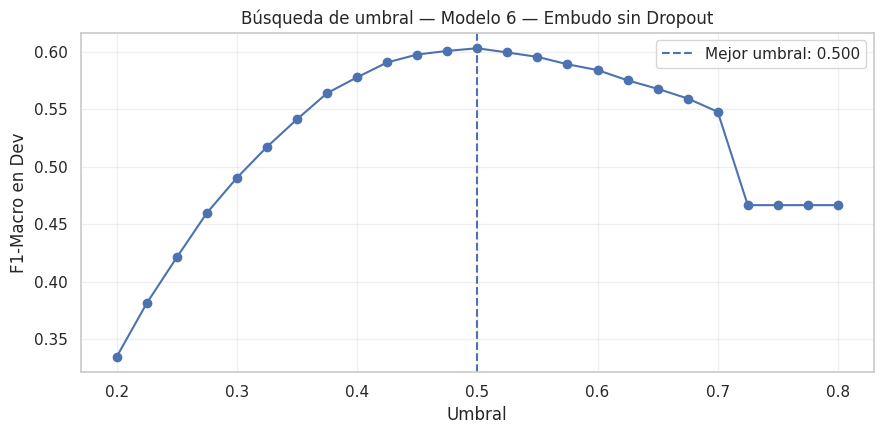

In [77]:
# 2.5.3 — Búsqueda del umbral que maximiza F1-Macro en Dev

umbrales = np.round(np.arange(0.20, 0.801, 0.025), 3)
filas_umbral = []

for umbral in umbrales:
    predicciones_u = (mejor_prob >= umbral).astype(int)

    filas_umbral.append({
        "Umbral": umbral,
        "F1-Macro (Dev)": f1_score(
            y_dev_mlp, predicciones_u, average="macro"
        ),
        "Accuracy (Dev)": accuracy_score(
            y_dev_mlp, predicciones_u
        ),
        "Precision clase 1": classification_report(
            y_dev_mlp,
            predicciones_u,
            labels=[0, 1],
            output_dict=True,
            zero_division=0
        )["1"]["precision"],
        "Recall clase 1": classification_report(
            y_dev_mlp,
            predicciones_u,
            labels=[0, 1],
            output_dict=True,
            zero_division=0
        )["1"]["recall"]
    })

df_calibracion = pd.DataFrame(filas_umbral)

print(f"Modelo evaluado: {mejor_nombre}")
display(df_calibracion.round(4))

# Mejor umbral entre los valores evaluados.
fila_optima = df_calibracion.loc[
    df_calibracion["F1-Macro (Dev)"].idxmax()
]

u_optimo = float(fila_optima["Umbral"])
f1_optimo = float(fila_optima["F1-Macro (Dev)"])
acc_optimo = float(fila_optima["Accuracy (Dev)"])

print("\nMejor umbral dentro de la búsqueda:")
print(f"Modelo: {mejor_nombre}")
print(f"Umbral seleccionado: {u_optimo:.3f}")
print(f"F1-Macro en Dev: {f1_optimo:.4f}")
print(f"Accuracy en Dev: {acc_optimo:.4f}")

# Curva de F1-Macro según el umbral.
plt.figure(figsize=(9, 4.5))
plt.plot(
    df_calibracion["Umbral"],
    df_calibracion["F1-Macro (Dev)"],
    marker="o"
)
plt.axvline(
    u_optimo,
    linestyle="--",
    label=f"Mejor umbral: {u_optimo:.3f}"
)
plt.xlabel("Umbral")
plt.ylabel("F1-Macro en Dev")
plt.title(f"Búsqueda de umbral — {mejor_nombre}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Interpretación del ajuste de umbral

Con el umbral estándar `0,50`, el Modelo 6 obtiene F1-Macro `0,6015`, el mejor resultado de la búsqueda realizada.

(Todo esta mal)
El cambio tiene un costo y un beneficio claros. El recall de la clase relevante aumenta de `0,2613` a `0,3696`: el modelo recupera una proporción mayor de las respuestas relevantes. A cambio, la precision de esa clase baja de `0,3210` a `0,2819`, por lo que una mayor proporción de las predicciones positivas son falsas.

La accuracy también baja de `0,8381` a `0,8030`. Esto no contradice la mejora en F1-Macro: al reducir el umbral, el modelo marca más ejemplos como relevantes, lo que ayuda a la clase minoritaria pero aumenta los falsos positivos.

**Conclusión:** el umbral `0,45` ofrece el mejor F1-Macro entre los valores probados en Dev. La mejora frente al umbral `0,50` es pequeña (`+0,0039`), aunque el aumento del recall de la clase relevante es considerable. Este umbral es una selección experimental para la siguiente etapa, no una garantía de que sea el mejor umbral en datos nuevos.

### 2.5.4 Comparación con la regresión logística (baseline original)

Una vez seleccionado el Modelo 6 con umbral `0.50`, comparamos su rendimiento con el baseline original de regresión logística.

Esta comparación permite evaluar si los experimentos con MLP consiguieron mejorar el resultado de referencia sobre el mismo conjunto de desarrollo (Dev).

Utilizamos principalmente F1-Macro porque considera el rendimiento de ambas clases y resulta más informativo que Accuracy en un problema con una distribución desigual de etiquetas.

465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
COMPARACIÓN EN DEV
-------------------------------------------------------
Modelo                                F1-Macro   Accuracy
-------------------------------------------------------
Regresión logística (baseline)          0.5633     0.6842
Modelo 6 (umbral 0.50)                  0.6028     0.8200

Diferencia de F1-Macro respecto del baseline:
+0.0395

Reporte de clasificación - Modelo 6
              precision    recall  f1-score   support

           0     0.9016    0.8914    0.8965     13007
           1     0.2979    0.3214    0.3092      1864

    accuracy                         0.8200     14871
   macro avg     0.5997    0.6064    0.6028     14871
weighted avg     0.8260    0.8200    0.8229     14871



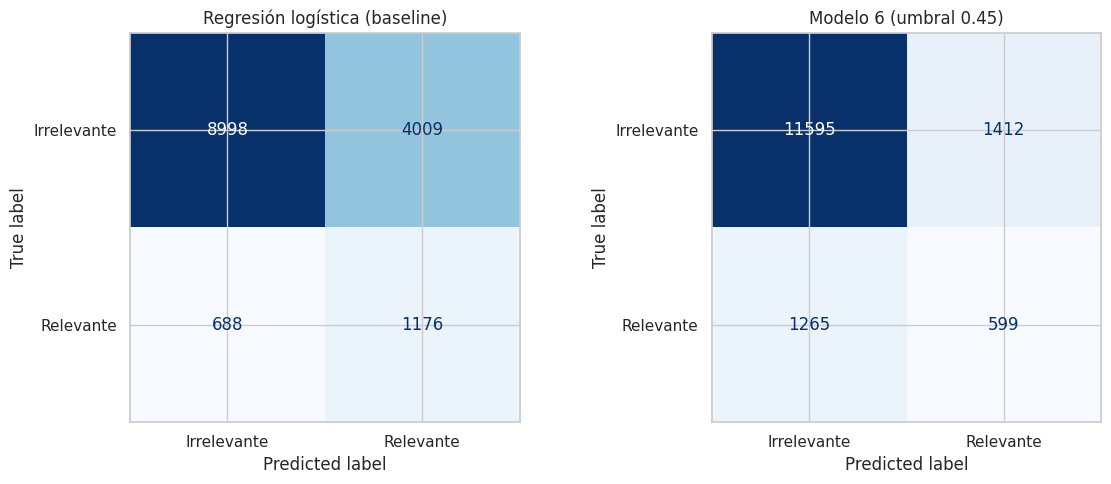

In [78]:
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------------
# Baseline original: regresión logística
# --------------------------------------------------

f1_baseline = 0.5633
accuracy_baseline = 0.6842
matriz_baseline = np.array([
    [8998, 4009],
    [ 688, 1176]
])

# --------------------------------------------------
# Modelo 6: evaluación con umbral 0.45
# --------------------------------------------------

# Probabilidades del Modelo 6 sobre Dev
probabilidades_m6 = mlp_6_sin_dropout.predict(X_dev_mlp).ravel()

umbral = 0.50
predicciones_m6 = (probabilidades_m6 >= umbral).astype(int)

f1_m6 = f1_score(y_dev_mlp, predicciones_m6, average="macro")
accuracy_m6 = accuracy_score(y_dev_mlp, predicciones_m6)
matriz_m6 = confusion_matrix(y_dev_mlp, predicciones_m6)

# --------------------------------------------------
# Comparación de métricas
# --------------------------------------------------

print("COMPARACIÓN EN DEV")
print("-" * 55)
print(f"{'Modelo':<35} {'F1-Macro':>10} {'Accuracy':>10}")
print("-" * 55)
print(f"{'Regresión logística (baseline)':<35} {f1_baseline:>10.4f} {accuracy_baseline:>10.4f}")
print(f"{'Modelo 6 (umbral 0.50)':<35} {f1_m6:>10.4f} {accuracy_m6:>10.4f}")

print("\nDiferencia de F1-Macro respecto del baseline:")
print(f"{f1_m6 - f1_baseline:+.4f}")

print("\nReporte de clasificación - Modelo 6")
print(classification_report(y_dev_mlp, predicciones_m6, digits=4))

# --------------------------------------------------
# Matrices de confusión
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=matriz_baseline,
    display_labels=["Irrelevante", "Relevante"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Regresión logística (baseline)")

ConfusionMatrixDisplay(
    confusion_matrix=matriz_m6,
    display_labels=["Irrelevante", "Relevante"]
).plot(ax=axes[1], cmap="Blues", colorbar=False)

axes[1].set_title("Modelo 6 (umbral 0.45)")

plt.tight_layout()
plt.show()

#### Interpretación de la comparación

El baseline original obtuvo **F1-Macro = 0,5633** y **Accuracy = 0,6842**. En cambio, el Modelo 6 con umbral `0.50` alcanzó **F1-Macro = 0,6015** y **Accuracy = 0,8264**.

Esto representa una mejora de **0,1422 puntos en F1-Macro** respecto del baseline original. Por lo tanto, el Modelo 6 con el umbral sin ajustar consigue un mejor equilibrio global entre las dos clases según la métrica principal.

Sin embargo, es importante observar cómo cambia el comportamiento de la clase relevante.

El baseline original obtuvo precisión aproximada de **0,2268** y recall de **0,6309** para esa clase. El Modelo 6 alcanza precisión **0,3077** y recall **0,2940**.

Esto significa que el MLP consigue una mayor precisión al identificar oraciones relevantes, pero recupera una proporción menor de las respuestas positivas reales. Es decir, comete proporcionalmente menos errores al marcar oraciones como relevantes, pero también deja pasar más respuestas verdaderas.

La matriz de confusión permite observar este cambio en el tipo de error: el baseline genera muchos falsos positivos, mientras que el Modelo 6 reduce ese problema, a costa de aumentar los falsos negativos.

Por lo tanto, la mejora del F1-Macro no significa que el MLP sea superior en todas las métricas ni que recupere más respuestas relevantes. Su ventaja está en conseguir un mejor equilibrio global entre ambas clases, principalmente por un mejor comportamiento sobre la clase irrelevante.

También debemos tener en cuenta que la Accuracy, por sí sola, no alcanza para establecer cuál es el mejor modelo. En este conjunto, la clase irrelevante representa la mayoría de los ejemplos, por lo que una buena identificación de esa clase puede elevar considerablemente la exactitud general.

En conclusión, el **Modelo 6 con umbral `0.50` supera al baseline original en F1-Macro**, que es nuestra métrica principal. Sin embargo, la comparación muestra que todavía existe una dificultad importante para recuperar todas las oraciones relevantes. La mejora es real en términos de equilibrio global, pero no implica resolver el problema de identificación de la clase minoritaria.

## Modelo 8 — Arquitectura del profesor sin Dropout y con L2 (0.001)

En este experimento retomamos la arquitectura del profesor, eliminando Dropout pero conservando la regularización L2 (0.001). El objetivo es evaluar si esta arquitectura puede mejorar los resultados del Modelo 6 manteniendo el mismo tipo de regularización.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 13s 24ms/step - accuracy: 0.6673 - loss: 0.6669 - val_accuracy: 0.8528 - val_loss: 0.4958
Epoch 2/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.6855 - loss: 0.6287 - val_accuracy: 0.8427 - val_loss: 0.4884
Epoch 3/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.6896 - loss: 0.6235 - val_accuracy: 0.8377 - val_loss: 0.4877
Epoch 4/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6916 - loss: 0.6196 - val_accuracy: 0.8340 - val_loss: 0.4877
Epoch 5/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.6940 - loss: 0.6161 - val_accuracy: 0.8316 - val_loss: 0.4868
Epoch 6/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6959 - loss: 0.6128 - val_accuracy: 0.8283 - val_loss: 0.4861
Epoch 7/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.6974 - loss: 0.6097 - val_accuracy: 0.8240 - val_loss: 0.4863
Epoch 8/100
345/345 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.6982 - loss: 0.6065 -

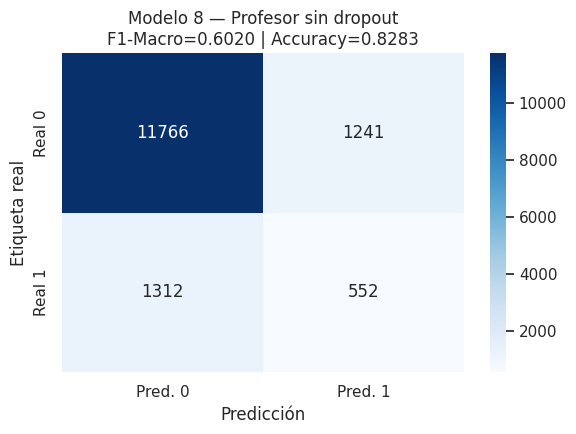

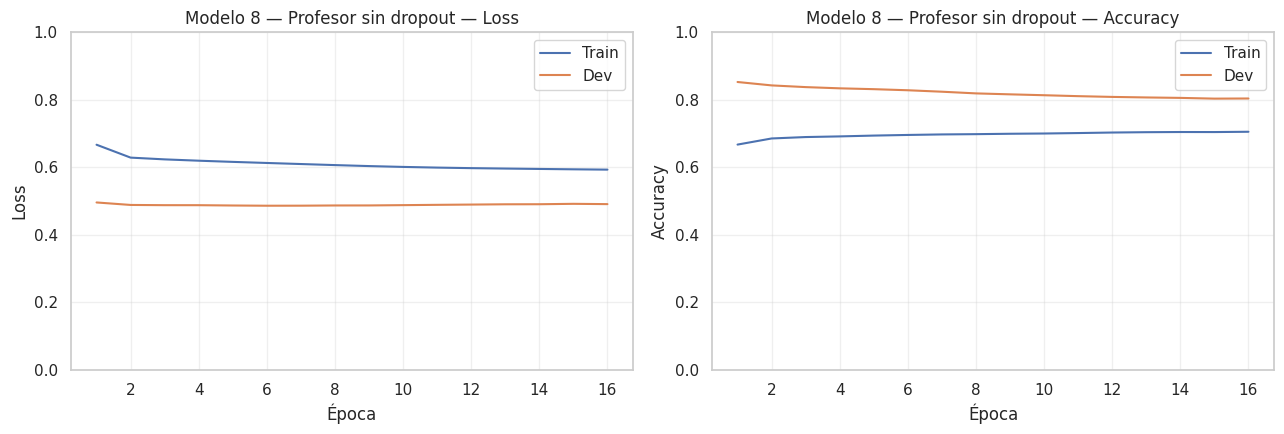

In [79]:
# M8: Arquitectura del profesor sin Dropout

tf.keras.backend.clear_session()

modelo_m8 = Sequential([
    Dense(32, activation='relu', kernel_regularizer=l2(0.001), input_shape=(5000,)),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(1, activation='sigmoid')
])

modelo_m8.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stopping_m8 = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

historial_m8 = modelo_m8.fit(
    X_train_mlp,
    y_train_mlp,
    validation_data=(X_dev_mlp, y_dev_mlp),
    epochs=100,
    batch_size=128,
    callbacks=[early_stopping_m8],
    verbose=1
)




resultado_m8 = evaluar_y_graficar_mlp(
    "Modelo 8 — Profesor sin dropout",
    modelo_m8,
    historial_m8,
    "M8"
)


### Interpretación del Modelo 8

El Modelo 8 alcanzó un **F1-Macro de 0.6015** y un **Accuracy de 0.8260**, igualando el resultado del Modelo 6. Por lo tanto, recuperar la arquitectura del profesor sin Dropout, pero conservando la regularización L2 (0.001), no produjo una mejora en el rendimiento global.

Al observar las curvas de aprendizaje, la pérdida de entrenamiento (`loss`) disminuyó progresivamente durante las 16 épocas, pasando de 0.6675 a 0.5888. En cambio, la pérdida de validación (`val_loss`) alcanzó su mínimo en la época 6, con **0.4824**, y luego mostró una tendencia general al aumento. La `val_accuracy` también descendió progresivamente desde 0.8569 en la primera época hasta 0.8012 en la última. Esta diferencia entre entrenamiento y validación indica que el modelo continuó ajustándose a los datos de entrenamiento sin conseguir mejorar su desempeño sobre Dev.

En cuanto a la clasificación, obtuvo una precisión de **0.3039** y un recall de **0.3010** para la clase relevante. En comparación con el Modelo 6, presentó un recall ligeramente mayor, pero una precisión ligeramente menor, manteniendo exactamente el mismo F1-Macro.

En conclusión, **la arquitectura del profesor sin Dropout y con L2 no logró superar al Modelo 6**. Aunque modificó ligeramente el equilibrio entre precisión y recall, el rendimiento global permaneció igual. Esto refuerza que los cambios en la arquitectura y la regularización no son suficientes, por sí solos, para resolver las dificultades de identificación de oraciones relevantes.

## 2.6 Conclusiones de los experimentos MLP

### Comparación de resultados en Dev

La siguiente tabla resume los resultados de los experimentos, utilizando F1-Macro como métrica principal y mostrando también la precisión y el recall de la clase relevante.

| Experimento | F1-Macro | Precisión clase relevante | Recall clase relevante |
|---|---:|---:|---:|
| Baseline original: regresión logística | 0,5633 | 0,2268 | 0,6309 |
| Regresión logística con Train reducido | 0,5570 | 0,2200 | 0,5900 |
| Modelo 1: sin regularización | 0,5515 | 0,2032 | 0,3922 |
| Modelo 2: profesor con regularización | 0,5948 | 0,3183 | 0,2505 |
| Modelo 3: embudo 128 → 64 → 32 | 0,5731 | 0,3594 | 0,1626 |
| Modelo 4: embudo con Dropout 0,5 | 0,4666 | 0,0000 | 0,0000 |
| Modelo 5: embudo de cuatro capas | 0,5854 | 0,3461 | 0,1990 |
| Modelo 6: embudo sin Dropout, con L2 | 0,6015 | 0,3077 | 0,2940 |
| Modelo 7: embudo con L2 suavizado | 0,5710 | 0,3042 | 0,2521 |
| Modelo 8: profesor sin Dropout, con L2 | 0,6015 | 0,3039 | 0,3010 |

### ¿Qué aprendimos de los experimentos?

**1. El Modelo 1 mostró sobreajuste.**

La pérdida de Train descendió de 0,6202 a 0,0039 y su accuracy llegó a 0,9989. En cambio, la pérdida de Dev pasó de 0,4868 a 2,3506 y su accuracy terminó en 0,6948.

La separación progresiva entre ambas curvas muestra que el modelo aprendió cada vez mejor los ejemplos de entrenamiento, pero perdió capacidad de generalización. Además, su F1-Macro (0,5515) quedó por debajo del baseline original (0,5633). Esto motivó incorporar regularización.

**2. El Modelo 2 redujo la separación y mejoró el resultado.**

La combinación de Dropout, L2 y Early Stopping elevó el F1-Macro a 0,5948, superando tanto al Modelo 1 como al baseline original.

Las curvas de pérdida se mantuvieron relativamente cercanas, pero la pérdida de Dev alcanzó su mejor valor en la época 3 y después dejó de mejorar. El entrenamiento terminó en la época 13 y restauró los pesos de la época 3.

El recall de la clase relevante quedó en 0,2505. Aunque el modelo mejoró el equilibrio entre las clases, todavía tenía dificultades para recuperar respuestas positivas.

**3. El Modelo 3 no mejoró con el cambio de arquitectura.**

El Modelo 3 alcanzó F1-Macro 0,5731, por debajo del Modelo 2 (0,5948), aunque todavía por encima del baseline original (0,5633).

La precisión de la clase relevante aumentó a 0,3594, pero el recall descendió a 0,1626 y su F1 pasó a 0,2239. Esto muestra que el modelo identificó menos ejemplos positivos: aunque sus predicciones positivas fueron más precisas, dejó sin recuperar una proporción mayor de las oraciones relevantes.

Early Stopping restauró los pesos de la época 12. El cambio a una arquitectura en embudo no produjo la mejora esperada en esta comparación. Aun así, se mantuvo esta arquitectura para continuar los experimentos y estudiar el efecto de otras modificaciones sobre una configuración común.

**4. El Modelo 4 mostró que una regularización más intensa puede perjudicar el aprendizaje.**

Elevar Dropout de 0,3 a 0,5 produjo una caída del F1-Macro a 0,4666. El modelo no identificó ningún ejemplo relevante, aunque su Accuracy fue 0,8747.

Las curvas muestran que la accuracy de Train permaneció estancada durante las primeras 11 épocas y la validación tampoco mejoró su pérdida después de la época 7. Esta configuración resultó demasiado restrictiva para identificar la clase positiva.

**5. Añadir una capa en el Modelo 5 recuperó parte del rendimiento.**

El Modelo 5 alcanzó F1-Macro 0,5854, superando al Modelo 3 (0,5731), pero sin alcanzar al Modelo 2 (0,5948).

El recall de la clase relevante aumentó de 0,1626 a 0,1990 y su F1 pasó de 0,2239 a 0,2527. Sin embargo, la precisión descendió ligeramente de 0,3594 a 0,3461.

La pérdida de Dev alcanzó su mejor valor en la época 5 y después dejó de mejorar. Por lo tanto, ampliar la arquitectura permitió recuperar parte del rendimiento, pero no produjo una mejora general frente al modelo profesor.

**6. El Modelo 6 obtuvo uno de los mejores resultados de la etapa.**

Al quitar Dropout y conservar L2 (0,001), el Modelo 6 alcanzó F1-Macro 0,6015.

Su recall de la clase relevante llegó a 0,2940, superior al de los modelos anteriores con regularización. La pérdida de Dev mejoró hasta la época 8 y luego aumentó ligeramente, mientras la pérdida de Train continuó descendiendo. Early Stopping restauró los pesos de la época 8.

Esta configuración obtuvo el mejor resultado entre los primeros siete modelos con el umbral estándar. La eliminación de Dropout favoreció el resultado en Dev para esta arquitectura concreta.

**7. Suavizar L2 en el Modelo 7 no mejoró el resultado.**

El Modelo 7 obtuvo F1-Macro 0,5710, por debajo del Modelo 6 (0,6015) y también de los Modelos 2, 3 y 5.

Su recall de la clase relevante fue 0,2521, ligeramente superior al del Modelo 2 (0,2505), pero inferior al del Modelo 6 (0,2940). Por lo tanto, suavizar L2 no produjo una mejora general en la clasificación.

Las curvas muestran que la pérdida de Train continuó descendiendo, mientras la pérdida de Dev aumentó desde la primera época. Early Stopping restauró los pesos de esa primera época.

Este experimento muestra que reducir la regularización no garantiza una mejor generalización y que aumentar el recall de la clase positiva no necesariamente mejora el equilibrio global entre las clases.

**8. El Modelo 8 igualó el mejor resultado utilizando otra arquitectura.**

En este experimento retomamos la arquitectura del profesor, eliminando Dropout pero conservando L2 (0,001). El objetivo fue evaluar si esa arquitectura podía obtener un resultado diferente al del Modelo 6 bajo una configuración de regularización similar.

El Modelo 8 alcanzó un F1-Macro de 0,6015 y un Accuracy de 0,8260, igualando el resultado del Modelo 6. En la clase relevante obtuvo una precisión de 0,3039 y un recall de 0,3010. Frente al Modelo 6, presentó un recall ligeramente superior (0,3010 frente a 0,2940), pero una precisión ligeramente inferior (0,3039 frente a 0,3077).

En las curvas de aprendizaje, la pérdida de Train descendió de manera sostenida durante las 16 épocas, mientras que la pérdida de Dev alcanzó su mínimo en la época 6 (0,4824) y luego tendió a aumentar. La accuracy de validación también descendió progresivamente. Early Stopping restauró los pesos de la época 6.

Por lo tanto, aunque el Modelo 8 igualó el mejor F1-Macro de la etapa, no consiguió superar al Modelo 6. La comparación tampoco permite afirmar que una de las dos arquitecturas sea superior en términos generales: ambas alcanzaron el mismo resultado en la métrica principal, con pequeñas diferencias en precisión y recall.

### Conclusión general

Los experimentos muestran que el rendimiento de una MLP no depende simplemente de aumentar la cantidad de capas o aplicar más regularización. La arquitectura, la intensidad de la regularización y la evolución del entrenamiento influyen en el equilibrio entre aprendizaje y generalización.

El Modelo 2 obtuvo un resultado sólido con la arquitectura del profesor y regularización. El cambio a una arquitectura en embudo en el Modelo 3 no produjo una mejora, mientras que añadir una capa en el Modelo 5 permitió recuperar parte del rendimiento sin superar al Modelo 2.

Por otro lado, el Modelo 4 mostró que una regularización demasiado intensa puede impedir el reconocimiento de la clase positiva. El Modelo 6, al quitar Dropout y conservar L2, consiguió uno de los mejores resultados. Posteriormente, el Modelo 8 permitió comprobar que la arquitectura del profesor, también sin Dropout y conservando L2, podía alcanzar el mismo F1-Macro.

En consecuencia, **los Modelos 6 y 8 quedan empatados como las mejores configuraciones de esta etapa**, ambos con un F1-Macro de 0,6015 y utilizando el umbral estándar de 0,50. Esto representa una mejora de 0,0382 puntos respecto del baseline original (0,5633).

Sin embargo, la mejora no significa que el problema esté resuelto. La identificación de oraciones relevantes continúa siendo una dificultad importante: ambos modelos alcanzaron valores de precisión y recall cercanos a 0,30 para la clase positiva. Esto evidencia que las representaciones utilizadas todavía tienen limitaciones para reconocer respuestas expresadas mediante vocabulario diferente.

Una de las principales limitaciones es la representación TF-IDF de 5.000 componentes. Esta representación se basa en la presencia y frecuencia de términos, pero no representa directamente las relaciones semánticas entre palabras. Por eso, preguntas y oraciones que expresan una misma idea mediante vocabulario diferente pueden resultar difíciles de relacionar.

Con estos resultados cerramos la experimentación inicial con MLP. En la siguiente etapa avanzaremos hacia representaciones basadas en embeddings de palabras, que permitirán trabajar con información semántica y comparar embeddings entrenados desde cero con embeddings preentrenados, tal como establece la pauta de la Etapa 3. El conjunto de Test continuará reservado para la evaluación final de la Etapa 5.

# Etapa 3: Embeddings y mejora de la clasificación de pares pregunta–oración

## 3.1 Punto de partida: qué aprendimos en las etapas anteriores

En la Etapa 1 construimos un modelo baseline basado en TF-IDF y Regresión Logística, que obtuvo un F1-Macro de **0,5633** y una accuracy de **0,6842** en Dev. Este resultado estableció una primera referencia para la clasificación de pares pregunta–oración.

En la Etapa 2 experimentamos con distintas arquitecturas de redes neuronales densas (MLP) utilizando representaciones TF-IDF. El Modelo 6 obtuvo el mejor F1-Macro entre los siete modelos comparados: **0,5979** con umbral 0,50 y una accuracy de **0,8414**. El Modelo 8, entrenado después de la selección, alcanzó 0,6004; la diferencia con el Modelo 6 (0,0025) no altera la conclusión y, por continuidad con la selección de la Etapa 2, mantenemos el Modelo 6 como referencia operativa.

La comparación entre las etapas anteriores muestra que el MLP mejoró el F1-Macro respecto del baseline. Sin embargo, ambos enfoques utilizan representaciones basadas en frecuencias de palabras, que no capturan directamente las relaciones semánticas entre los términos.

También debemos considerar el desbalance de clases del problema. Por eso utilizamos el F1-Macro como métrica principal y la accuracy como medida complementaria. Para los experimentos de esta etapa reutilizamos el Train reducido de la Etapa 2 y evaluamos sobre el conjunto Dev completo, sin aplicar submuestreo sobre este último.

A partir de estas observaciones, la Etapa 3 busca mejorar la representación textual mediante embeddings de 300 dimensiones. Comparamos vectores entrenados desde cero con embeddings preentrenados para español obtenidos mediante spaCy. Finalmente, desarrollamos una arquitectura que representa por separado la pregunta y la oración candidata, con el objetivo de comparar sus representaciones y mejorar la identificación de oraciones que contienen la respuesta.

La hipótesis es que los embeddings y la comparación explícita entre pregunta y oración permitan capturar relaciones semánticas que las representaciones TF-IDF no modelan directamente. Esta hipótesis se evalúa mediante los resultados obtenidos en Dev. El conjunto Test permanece reservado para la evaluación final de la Etapa 5.

## 3.2 Preparación consistente de Train y Dev

El vocabulario se aprende únicamente a partir de Train reducido. La longitud de secuencia se fija con el percentil 95 de las longitudes de `texto_combinado` en Train. Es la primera etapa en la que trabajamos con secuencias de tokens: las anteriores usaban representaciones TF-IDF, que no tienen una noción de longitud de secuencia. Usamos el mismo vectorizador para transformar tanto el texto combinado como las preguntas y las oraciones por separado.

In [81]:
# Imports explícitos para que la Etapa 3 sea más fácil de ejecutar y mantener.
import re
import string
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import spacy

from tensorflow.keras.layers import (
    Input, Embedding, GlobalAveragePooling1D, Dense, Dropout,
    Concatenate, Multiply, Lambda
)
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import f1_score, accuracy_score

# Reutilizamos los conjuntos preparados en las etapas anteriores.
train_e3 = df_train_down.copy()
dev_e3 = df_pares_dev.copy()

columnas_requeridas = {"pregunta", "oracion", "texto_combinado", "label"}
assert columnas_requeridas.issubset(train_e3.columns)
assert columnas_requeridas.issubset(dev_e3.columns)

textos_train = train_e3["texto_combinado"].fillna("").astype(str).to_numpy()
textos_dev = dev_e3["texto_combinado"].fillna("").astype(str).to_numpy()
preguntas_train = train_e3["pregunta"].fillna("").astype(str).to_numpy()
oraciones_train = train_e3["oracion"].fillna("").astype(str).to_numpy()
preguntas_dev = dev_e3["pregunta"].fillna("").astype(str).to_numpy()
oraciones_dev = dev_e3["oracion"].fillna("").astype(str).to_numpy()

y_train_e3 = train_e3["label"].to_numpy(dtype="int32")
y_dev_e3 = dev_e3["label"].to_numpy(dtype="int32")

# Longitud máxima basada solo en Train.
longitudes_train = train_e3["texto_combinado"].fillna("").astype(str).str.split().str.len()
MAX_LEN = max(10, int(np.ceil(np.percentile(longitudes_train, 95))))
MAX_TOKENS = 20000

# Conservamos letras acentuadas del español y eliminamos puntuación.
signos_puntuacion = string.punctuation + "¿¡“”«»…—–"
patron_puntuacion = "[" + re.escape(signos_puntuacion) + "]"

def estandarizar_espanol(texto):
    texto = tf.strings.lower(texto)
    texto = tf.strings.regex_replace(texto, patron_puntuacion, " ")
    texto = tf.strings.regex_replace(texto, r"\s+", " ")
    return texto

vectorizador_texto = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    standardize=estandarizar_espanol,
    split="whitespace",
    output_mode="int",
    output_sequence_length=MAX_LEN,
    name="vectorizador_texto"
)
vectorizador_texto.adapt(textos_train)  # Solo Train; nunca Dev ni Test.

# Entrada para los modelos que leen el par como un único texto.
X_train_seq = vectorizador_texto(textos_train).numpy()
X_dev_seq = vectorizador_texto(textos_dev).numpy()

# Entradas separadas para el modelo de comparación pregunta–oración.
X_train_pregunta = vectorizador_texto(preguntas_train).numpy()
X_train_oracion = vectorizador_texto(oraciones_train).numpy()
X_dev_pregunta = vectorizador_texto(preguntas_dev).numpy()
X_dev_oracion = vectorizador_texto(oraciones_dev).numpy()

vocabulario = vectorizador_texto.get_vocabulary()
VOCAB_SIZE = len(vocabulario)

assert len(X_train_seq) == len(y_train_e3)
assert len(X_dev_seq) == len(y_dev_e3)
assert len(X_train_pregunta) == len(X_train_oracion) == len(y_train_e3)
assert len(X_dev_pregunta) == len(X_dev_oracion) == len(y_dev_e3)

print("Train reducido:", len(y_train_e3), "pares")
print("Dev completo:", len(y_dev_e3), "pares")
print("Proporción positiva en Train:", f"{y_train_e3.mean():.2%}")
print("Proporción positiva en Dev:", f"{y_dev_e3.mean():.2%}")
print("Longitud máxima (percentil 95 de Train):", MAX_LEN)
print("Tamaño del vocabulario:", VOCAB_SIZE)
print("Texto combinado Train/Dev:", X_train_seq.shape, X_dev_seq.shape)
print("Pregunta y oración por separado:", X_train_pregunta.shape, X_train_oracion.shape)

Train reducido: 44105 pares
Dev completo: 14871 pares
Proporción positiva en Train: 34.09%
Proporción positiva en Dev: 12.53%
Longitud máxima (percentil 95 de Train): 72
Tamaño del vocabulario: 20000
Texto combinado Train/Dev: (44105, 72) (14871, 72)
Pregunta y oración por separado: (44105, 72) (44105, 72)


## 3.2.1 Experimento complementario: clasificación con Naive Bayes

Además de las redes neuronales, incorporamos Naive Bayes como modelo probabilístico de referencia para evaluar su desempeño en la clasificación de pares pregunta–oración.

Probamos dos variantes: Multinomial Naive Bayes y Complement Naive Bayes. Ambas utilizan una representación TF-IDF de los textos combinados, con unigramas y bigramas, para estimar si una oración candidata pertenece a la clase relevante (1) o irrelevante (0).

Para mantener la comparación consistente con los experimentos de esta etapa, utilizamos el mismo Train reducido y el mismo conjunto Dev completo. El vectorizador se ajusta exclusivamente con Train y luego transforma Dev, evitando incorporar información del conjunto de evaluación durante la construcción del vocabulario.

Este experimento tiene un propósito complementario: determinar si un modelo clásico basado en probabilidades puede ofrecer resultados competitivos frente a los MLP y las arquitecturas con embeddings. No reemplaza los experimentos de embeddings exigidos por la consigna.

In [82]:

# ============================================================
# ETAPA 3.2.1 — EXPERIMENTO COMPLEMENTARIO: NAIVE BAYES
# ============================================================

import time
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Representación TF-IDF
# ------------------------------------------------------------
# Utilizamos los mismos textos de Train y Dev de la Etapa 3.
# El vocabulario se aprende exclusivamente con Train.

vectorizador_nb = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    norm="l2"
)

X_train_nb = vectorizador_nb.fit_transform(
    train_e3["texto_combinado"].fillna("").astype(str)
)

X_dev_nb = vectorizador_nb.transform(
    dev_e3["texto_combinado"].fillna("").astype(str)
)

print("Dimensiones TF-IDF para Naive Bayes:")
print("Train:", X_train_nb.shape)
print("Dev:", X_dev_nb.shape)


# ------------------------------------------------------------
# 2. Definición de los modelos
# ------------------------------------------------------------

modelos_nb = {
    "MultinomialNB": MultinomialNB(alpha=1.0),
    "ComplementNB": ComplementNB(alpha=1.0)
}

resultados_naive_bayes = []
modelos_nb_entrenados = {}


# ------------------------------------------------------------
# 3. Entrenamiento y evaluación en Dev
# ------------------------------------------------------------

for nombre, modelo in modelos_nb.items():

    inicio = time.perf_counter()

    modelo.fit(X_train_nb, y_train_e3)

    probabilidades = modelo.predict_proba(X_dev_nb)

    # Identificamos la columna correspondiente a la clase positiva.
    indice_positivo = np.where(modelo.classes_ == 1)[0][0]
    prob_positiva = probabilidades[:, indice_positivo]

    # Mismo umbral estándar utilizado en las comparaciones.
    predicciones = (prob_positiva >= 0.50).astype("int32")

    tiempo_modelo = time.perf_counter() - inicio

    f1 = f1_score(
        y_dev_e3,
        predicciones,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(y_dev_e3, predicciones)

    precision_positiva = precision_score(
        y_dev_e3,
        predicciones,
        pos_label=1,
        zero_division=0
    )

    recall_positivo = recall_score(
        y_dev_e3,
        predicciones,
        pos_label=1,
        zero_division=0
    )

    cm = confusion_matrix(
        y_dev_e3,
        predicciones,
        labels=[0, 1]
    )

    resultados_naive_bayes.append({
        "Modelo": nombre,
        "F1-Macro Dev": f1,
        "Accuracy Dev": accuracy,
        "Precision positiva": precision_positiva,
        "Recall positivo": recall_positivo,
        "Tiempo (segundos)": tiempo_modelo
    })

    modelos_nb_entrenados[nombre] = modelo

    print(f"\n{'=' * 60}")
    print(f"RESULTADOS — {nombre}")
    print(f"{'=' * 60}")
    print(f"F1-Macro Dev: {f1:.4f}")
    print(f"Accuracy Dev: {accuracy:.4f}")
    print(f"Precision positiva: {precision_positiva:.4f}")
    print(f"Recall positivo: {recall_positivo:.4f}")
    print(f"Tiempo de ajuste y predicción: {tiempo_modelo:.2f} segundos")
    print("\nMatriz de confusión:")
    print(cm)


# ------------------------------------------------------------
# 4. Comparación entre variantes de Naive Bayes
# ------------------------------------------------------------

tabla_naive_bayes = (
    pd.DataFrame(resultados_naive_bayes)
    .sort_values("F1-Macro Dev", ascending=False)
    .reset_index(drop=True)
)

print("\nCOMPARACIÓN DE MODELOS NAIVE BAYES EN DEV")
display(tabla_naive_bayes.round(4))


Dimensiones TF-IDF para Naive Bayes:
Train: (44105, 5000)
Dev: (14871, 5000)

RESULTADOS — MultinomialNB
F1-Macro Dev: 0.5776
Accuracy Dev: 0.8461
Precision positiva: 0.3157
Recall positivo: 0.1947
Tiempo de ajuste y predicción: 0.03 segundos

Matriz de confusión:
[[12220   787]
 [ 1501   363]]

RESULTADOS — ComplementNB
F1-Macro Dev: 0.5291
Accuracy Dev: 0.6650
Precision positiva: 0.1893
Recall positivo: 0.5097
Tiempo de ajuste y predicción: 0.03 segundos

Matriz de confusión:
[[8939 4068]
 [ 914  950]]

COMPARACIÓN DE MODELOS NAIVE BAYES EN DEV


,Modelo,F1-Macro Dev,Accuracy Dev,Precision positiva,Recall positivo,Tiempo (segundos)
0,MultinomialNB,0.5776,0.8461,0.3157,0.1947,0.0310
1,ComplementNB,0.5291,0.6650,0.1893,0.5097,0.0257


## 3.2.2 Análisis de los resultados de Naive Bayes

Los resultados muestran que Multinomial Naive Bayes obtuvo un F1-Macro de **0,5776** y una accuracy de **0,8461**, superando a Complement Naive Bayes, que alcanzó un F1-Macro de **0,5291** y una accuracy de **0,6650**.

Al analizar las métricas de la clase positiva, observamos diferencias importantes entre ambas variantes. MultinomialNB obtuvo una precisión de **0,3157** y un recall de **0,1947**. Esto indica que genera menos falsos positivos, pero deja sin identificar una proporción considerable de las oraciones que contienen la respuesta.

Por su parte, ComplementNB alcanzó un recall positivo de **0,5097**, pero su precisión fue de apenas **0,1893**. La matriz de confusión muestra que esta variante identifica más respuestas correctas, aunque también clasifica incorrectamente muchas oraciones irrelevantes como positivas.

Por lo tanto, seleccionamos MultinomialNB como la mejor variante dentro de este experimento, considerando el F1-Macro como criterio principal. Sin embargo, su resultado queda por debajo del MLP de la Etapa 2 y de los modelos con embeddings de la Etapa 3.

En comparación con el baseline de TF-IDF y Regresión Logística de la Etapa 1, MultinomialNB presenta una mejora de **0,0143 puntos de F1-Macro**. Esto demuestra que un clasificador probabilístico sencillo puede ofrecer una referencia competitiva, aunque no alcanza el desempeño de las arquitecturas neuronales desarrolladas posteriormente.

Finalmente, el tiempo de ajuste y predicción de ambas variantes fue muy reducido. No obstante, estos tiempos corresponden únicamente al entrenamiento y la predicción de los clasificadores; no incluyen el ajuste y la transformación TF-IDF.

En conclusión, Naive Bayes queda incorporado como experimento complementario y referencia clásica. Los resultados no reemplazan ni modifican los experimentos centrales de embeddings exigidos para esta etapa.

## 3.2.3 Diagnóstico de generalización de Naive Bayes

Para complementar la evaluación de Naive Bayes, comparamos su desempeño sobre Train y Dev. Esta comparación permite observar si existe una diferencia importante entre los resultados obtenidos sobre los datos utilizados para ajustar los clasificadores y los datos reservados para validación.

Utilizamos F1-Macro y accuracy con el mismo umbral de clasificación de 0,50. Una diferencia marcada entre Train y Dev podría indicar problemas de generalización. Sin embargo, interpretamos estas diferencias considerando que Train fue reducido y Dev conserva su distribución original de clases.

Este análisis es complementario y no modifica el entrenamiento ni los resultados ya registrados.

In [83]:

# ============================================================
# ETAPA 3.2.3 — DIAGNÓSTICO DE GENERALIZACIÓN DE NAIVE BAYES
# ============================================================

from sklearn.metrics import f1_score, accuracy_score

resultados_diagnostico_nb = []
predicciones_nb_diagnostico = {}

for nombre, modelo in modelos_nb_entrenados.items():

    # Identificar la columna de la clase positiva.
    indice_positivo = np.where(modelo.classes_ == 1)[0][0]

    # Predicciones sobre Train.
    probabilidades_train = modelo.predict_proba(X_train_nb)[:, indice_positivo]
    predicciones_train = (probabilidades_train >= 0.50).astype("int32")

    # Predicciones sobre Dev.
    probabilidades_dev = modelo.predict_proba(X_dev_nb)[:, indice_positivo]
    predicciones_dev = (probabilidades_dev >= 0.50).astype("int32")

    # Métricas de Train.
    f1_train = f1_score(
        y_train_e3, predicciones_train,
        average="macro", zero_division=0
    )
    acc_train = accuracy_score(y_train_e3, predicciones_train)

    # Métricas de Dev.
    f1_dev = f1_score(
        y_dev_e3, predicciones_dev,
        average="macro", zero_division=0
    )
    acc_dev = accuracy_score(y_dev_e3, predicciones_dev)

    resultados_diagnostico_nb.append({
        "Modelo": nombre,
        "F1-Macro Train": f1_train,
        "F1-Macro Dev": f1_dev,
        "Brecha F1 (Train - Dev)": f1_train - f1_dev,
        "Accuracy Train": acc_train,
        "Accuracy Dev": acc_dev,
        "Brecha Accuracy": acc_train - acc_dev
    })

    # Guardamos las predicciones para los gráficos posteriores.
    predicciones_nb_diagnostico[nombre] = {
        "train": predicciones_train,
        "dev": predicciones_dev,
        "probabilidades_train": probabilidades_train,
        "probabilidades_dev": probabilidades_dev
    }

tabla_diagnostico_nb = pd.DataFrame(resultados_diagnostico_nb)

print("DIAGNÓSTICO DE GENERALIZACIÓN — NAIVE BAYES")
display(tabla_diagnostico_nb.round(4))

print("\nDistribución de clases:")
print(f"Train: {y_train_e3.mean():.2%} positivos")
print(f"Dev:   {y_dev_e3.mean():.2%} positivos")


DIAGNÓSTICO DE GENERALIZACIÓN — NAIVE BAYES


,Modelo,F1-Macro Train,F1-Macro Dev,Brecha F1 (Train - Dev),Accuracy Train,Accuracy Dev,Brecha Accuracy
0,MultinomialNB,0.5556,0.5776,-0.0221,0.6925,0.8461,-0.1536
1,ComplementNB,0.6210,0.5291,0.0919,0.6504,0.6650,-0.0146



Distribución de clases:
Train: 34.09% positivos
Dev:   12.53% positivos


### Visualización del desempeño y la generalización de Naive Bayes

Para complementar las métricas numéricas, representamos mediante matrices de confusión los resultados de MultinomialNB y ComplementNB sobre Train y Dev. Esto permite observar cómo se distribuyen los aciertos y errores de cada clase.

También comparamos visualmente el F1-Macro y la accuracy de ambos conjuntos. Estas representaciones permiten identificar diferencias de desempeño entre entrenamiento y validación, teniendo en cuenta que Train fue reducido y Dev conserva su distribución original.

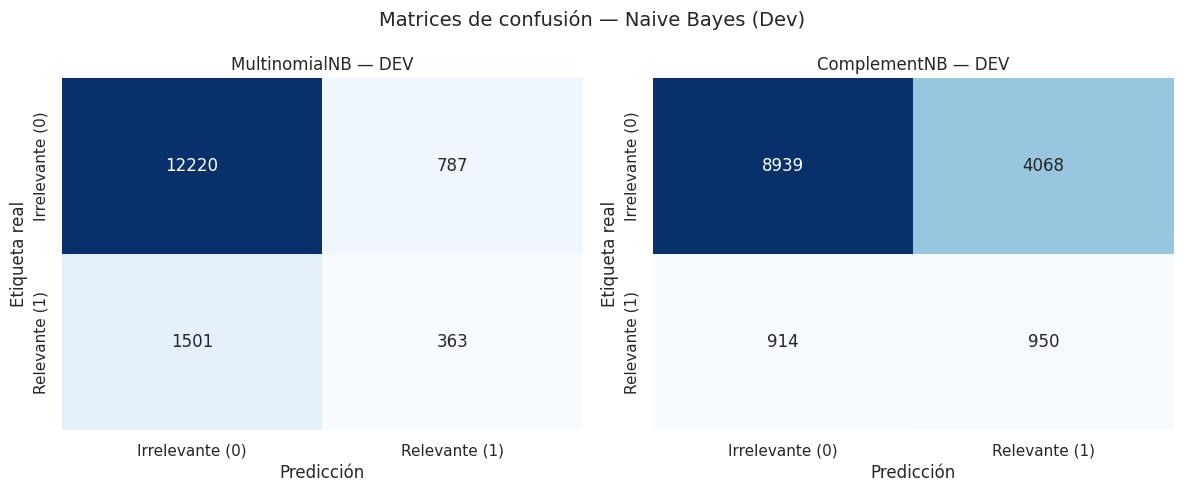

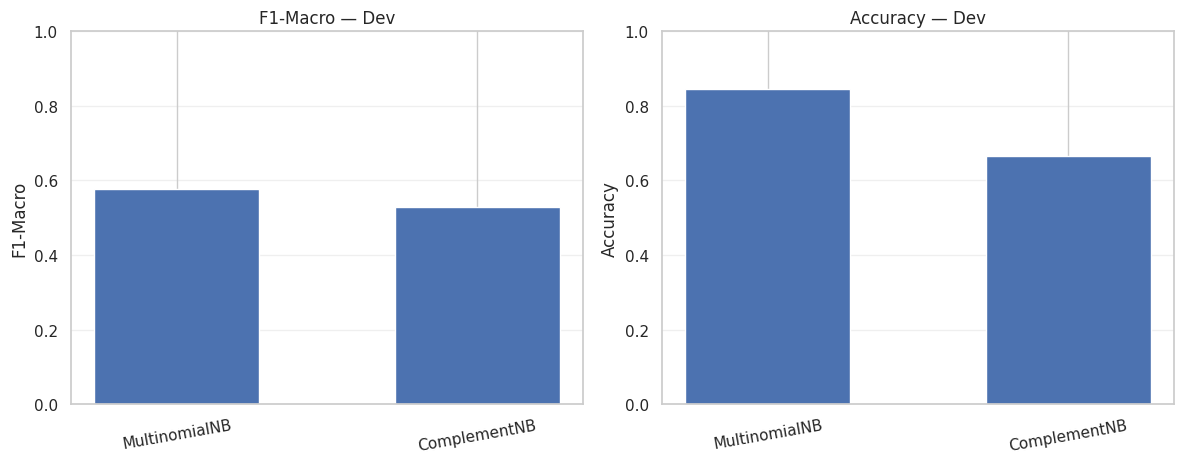

In [84]:
# ============================================================
# ETAPA 3.2.3 — GRÁFICOS DE NAIVE BAYES (SOLO DEV)
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

nombres_nb = list(predicciones_nb_diagnostico.keys())

# ------------------------------------------------------------
# 1. Matrices de confusión: solo Dev
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    len(nombres_nb),
    figsize=(6 * len(nombres_nb), 5)
)

axes = np.atleast_1d(axes)

for ax, nombre in zip(axes, nombres_nb):

    y_pred = predicciones_nb_diagnostico[nombre]["dev"]

    matriz = confusion_matrix(
        y_dev_e3,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Irrelevante (0)", "Relevante (1)"],
        yticklabels=["Irrelevante (0)", "Relevante (1)"],
        ax=ax
    )

    ax.set_title(f"{nombre} — DEV")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Etiqueta real")

plt.suptitle(
    "Matrices de confusión — Naive Bayes (Dev)",
    fontsize=14
)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Comparación de métricas: solo Dev
# ------------------------------------------------------------

x = np.arange(len(tabla_diagnostico_nb))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# F1-Macro en Dev
axes[0].bar(
    x,
    tabla_diagnostico_nb["F1-Macro Dev"],
    width=0.55,
    label="F1-Macro Dev"
)

axes[0].set_title("F1-Macro — Dev")
axes[0].set_ylabel("F1-Macro")
axes[0].set_xticks(x)
axes[0].set_xticklabels(
    tabla_diagnostico_nb["Modelo"],
    rotation=10
)
axes[0].set_ylim(0, 1)
axes[0].grid(axis="y", alpha=0.3)


# Accuracy en Dev
axes[1].bar(
    x,
    tabla_diagnostico_nb["Accuracy Dev"],
    width=0.55,
    label="Accuracy Dev"
)

axes[1].set_title("Accuracy — Dev")
axes[1].set_ylabel("Accuracy")
axes[1].set_xticks(x)
axes[1].set_xticklabels(
    tabla_diagnostico_nb["Modelo"],
    rotation=10
)
axes[1].set_ylim(0, 1)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 3.2.4 Embeddings preentrenados para español

Usamos los vectores de 300 dimensiones del modelo `es_core_news_md` de spaCy. Las palabras cubiertas se inicializan con sus vectores preentrenados; las palabras del vocabulario sin vector reciben una inicialización aleatoria pequeña y pueden ajustarse durante el entrenamiento. La matriz se comparte como punto de partida para los dos modelos que usan embeddings preentrenados.

In [85]:
# El modelo spaCy se descarga en la celda de librerías de la Etapa 1.
nlp_pre = spacy.load(
    "es_core_news_md",
    exclude=["tok2vec", "morphologizer", "parser", "senter", "ner",
             "attribute_ruler", "lemmatizer"]
)

DIM_EMBEDDING = int(nlp_pre.vocab.vectors_length)
assert DIM_EMBEDDING == 300, f"Se esperaban vectores de 300 dimensiones y se obtuvieron {DIM_EMBEDDING}."

# Identificamos las palabras del vocabulario de Keras que tienen vector en spaCy.
tiene_vector = np.zeros(VOCAB_SIZE, dtype=bool)
for i in range(2, VOCAB_SIZE):  # 0=padding, 1=OOV
    tiene_vector[i] = nlp_pre.vocab[str(vocabulario[i])].has_vector

rng = np.random.default_rng(42)
matriz_embeddings_pre = rng.normal(
    loc=0.0, scale=0.05,
    size=(VOCAB_SIZE, DIM_EMBEDDING)
).astype(np.float32)
matriz_embeddings_pre[0] = 0.0  # El índice 0 es padding.

for i in range(2, VOCAB_SIZE):
    if tiene_vector[i]:
        matriz_embeddings_pre[i] = nlp_pre.vocab[str(vocabulario[i])].vector.astype(np.float32)

assert matriz_embeddings_pre.shape == (VOCAB_SIZE, DIM_EMBEDDING)
assert np.isfinite(matriz_embeddings_pre).all()
assert np.all(matriz_embeddings_pre[0] == 0)

# Cobertura por tipo de palabra y por aparición en los textos.
tokens_train = X_train_seq[X_train_seq != 0]
tokens_dev = X_dev_seq[X_dev_seq != 0]
cobertura_vocabulario = tiene_vector[2:].mean() * 100 if VOCAB_SIZE > 2 else 0.0
cobertura_train = tiene_vector[tokens_train].mean() * 100 if len(tokens_train) else 0.0
cobertura_dev = tiene_vector[tokens_dev].mean() * 100 if len(tokens_dev) else 0.0

print("Modelo spaCy: es_core_news_md")
print("Dimensión del embedding:", DIM_EMBEDDING)
print("Matriz de embeddings:", matriz_embeddings_pre.shape)
print(f"Cobertura del vocabulario (tipos): {cobertura_vocabulario:.2f}%")
print(f"Cobertura por apariciones en Train: {cobertura_train:.2f}%")
print(f"Cobertura por apariciones en Dev: {cobertura_dev:.2f}%")

Modelo spaCy: es_core_news_md
Dimensión del embedding: 300
Matriz de embeddings: (20000, 300)
Cobertura del vocabulario (tipos): 89.77%
Cobertura por apariciones en Train: 93.35%
Cobertura por apariciones en Dev: 91.38%


## 3.2.5 Experimento de referencia: embeddings de 300 dimensiones desde cero vs. preentrenados

Los dos modelos leen `pregunta [SEP] oración` y tienen la misma arquitectura: `Embedding → GlobalAveragePooling1D → Dense(128) → Dropout(0,3) → Dense(64) → Dropout(0,2) → salida sigmoide`. La única diferencia intencional es la inicialización de los vectores: aleatoria o preentrenada. Ambos se entrenan con Train reducido y se evalúan sobre todo Dev con umbral 0,50.

### Embedding desde cero

In [86]:
# ============================================================
# ETAPA 3.2.5 — MODELO CON EMBEDDINGS DESDE CERO (300d)
# ============================================================

import time
import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    Embedding,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import f1_score, accuracy_score


# ------------------------------------------------------------
# 1. Construcción del modelo
# ------------------------------------------------------------

def construir_modelo_desde_cero(nombre):

    entrada = Input(
        shape=(MAX_LEN,),
        dtype="int32",
        name="secuencia_tokens"
    )

    # Embeddings inicializados aleatoriamente.
    capa_embedding = Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=DIM_EMBEDDING,
        embeddings_initializer=tf.keras.initializers.RandomNormal(
            mean=0.0,
            stddev=0.05,
            seed=42
        ),
        trainable=True,
        mask_zero=True,
        name=f"embedding_desde_cero_{nombre}"
    )

    x = capa_embedding(entrada)

    x = GlobalAveragePooling1D(
        name=f"promedio_embeddings_{nombre}"
    )(x)

    x = Dense(
        128,
        activation="relu",
        kernel_regularizer=l2(0.001),
        kernel_initializer=tf.keras.initializers.GlorotUniform(seed=111),
        name=f"densa128_{nombre}"
    )(x)

    x = Dropout(
        0.3,
        seed=201,
        name=f"dropout03_{nombre}"
    )(x)

    x = Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.001),
        kernel_initializer=tf.keras.initializers.GlorotUniform(seed=112),
        name=f"densa64_{nombre}"
    )(x)

    x = Dropout(
        0.2,
        seed=202,
        name=f"dropout02_{nombre}"
    )(x)

    salida = Dense(
        1,
        activation="sigmoid",
        name=f"salida_{nombre}"
    )(x)

    modelo = Model(
        entrada,
        salida,
        name=nombre
    )

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return modelo


# ------------------------------------------------------------
# 2. Entrenamiento y evaluación en Dev
# ------------------------------------------------------------

def entrenar_evaluar_desde_cero(modelo, nombre):

    parada_temprana = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    )

    inicio = time.time()

    historia = modelo.fit(
        X_train_seq,
        y_train_e3,
        validation_data=(X_dev_seq, y_dev_e3),
        epochs=15,
        batch_size=256,
        callbacks=[parada_temprana],
        shuffle=True,
        verbose=1
    )

    segundos = time.time() - inicio

    probabilidades = modelo.predict(
        X_dev_seq,
        batch_size=256,
        verbose=0
    ).ravel()

    predicciones = (probabilidades >= 0.50).astype("int32")

    resultado = {
        "Modelo": nombre,
        "F1-Macro Dev": f1_score(
            y_dev_e3,
            predicciones,
            average="macro",
            zero_division=0
        ),
        "Accuracy Dev": accuracy_score(
            y_dev_e3,
            predicciones
        ),
        "Tiempo (segundos)": segundos,
        "Parámetros entrenables": int(modelo.count_params())
    }

    print(f"\n{nombre} — umbral 0,50")
    print(f"F1-Macro Dev: {resultado['F1-Macro Dev']:.4f}")
    print(f"Accuracy Dev: {resultado['Accuracy Dev']:.4f}")
    print(f"Tiempo: {segundos:.2f} segundos")

    return historia, resultado, probabilidades, predicciones


# ------------------------------------------------------------
# 3. Construcción y entrenamiento
# ------------------------------------------------------------

tf.keras.utils.set_random_seed(42)

modelo_cero_300 = construir_modelo_desde_cero(
    "desde_cero_300d"
)

historia_cero_300, resultado_cero_300, prob_cero_300, pred_cero_300 = (
    entrenar_evaluar_desde_cero(
        modelo_cero_300,
        "Embeddings desde cero (300d)"
    )
)

Epoch 1/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 24s 122ms/step - accuracy: 0.6591 - loss: 0.7020 - val_accuracy: 0.8634 - val_loss: 0.4997
Epoch 2/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 24s 140ms/step - accuracy: 0.6902 - loss: 0.6043 - val_accuracy: 0.8402 - val_loss: 0.4702
Epoch 3/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 19s 113ms/step - accuracy: 0.7219 - loss: 0.5671 - val_accuracy: 0.7900 - val_loss: 0.4730
Epoch 4/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 20s 116ms/step - accuracy: 0.7536 - loss: 0.5336 - val_accuracy: 0.7317 - val_loss: 0.5218
Epoch 5/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 20s 114ms/step - accuracy: 0.7592 - loss: 0.5286 - val_accuracy: 0.6961 - val_loss: 0.5519
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.

Embeddings desde cero (300d) — umbral 0,50
F1-Macro Dev: 0.5909
Accuracy Dev: 0.8402
Tiempo: 107.63 segundos


#### Visualización de los datos de embedding desde cero

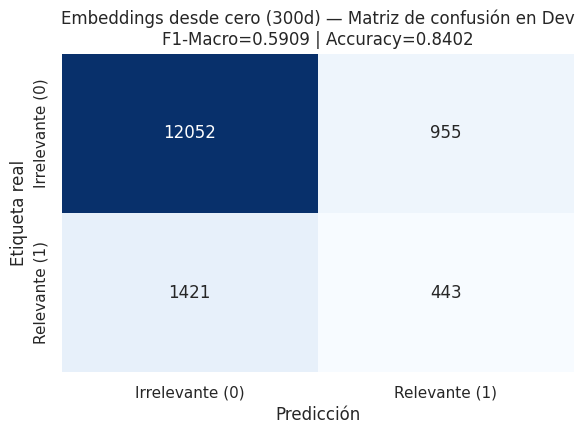

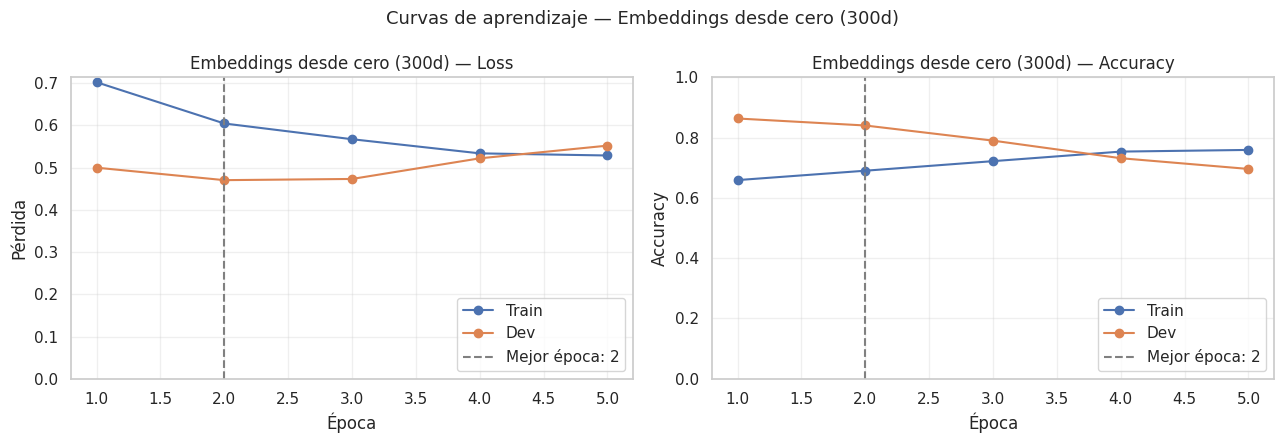


Embeddings desde cero (300d)
Mejor época según val_loss: 2
F1-Macro en Dev: 0.5909
Accuracy en Dev: 0.8402
Matriz de confusión:
[[12052   955]
 [ 1421   443]]


In [87]:
# ============================================================
# ETAPA 3.2.5 — GRÁFICOS: EMBEDDINGS DESDE CERO
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


def graficar_modelo_embeddings(
    nombre,
    historia,
    y_real,
    predicciones,
    f1_macro,
    accuracy
):
    historial = historia.history
    epocas = np.arange(1, len(historial["loss"]) + 1)

    # --------------------------------------------------------
    # 1. Matriz de confusión en Dev
    # --------------------------------------------------------

    matriz = confusion_matrix(
        y_real,
        predicciones,
        labels=[0, 1]
    )

    plt.figure(figsize=(6, 4.5))

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Irrelevante (0)", "Relevante (1)"],
        yticklabels=["Irrelevante (0)", "Relevante (1)"]
    )

    plt.title(
        f"{nombre} — Matriz de confusión en Dev\n"
        f"F1-Macro={f1_macro:.4f} | Accuracy={accuracy:.4f}"
    )
    plt.xlabel("Predicción")
    plt.ylabel("Etiqueta real")
    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # 2. Curvas de aprendizaje: Loss y Accuracy
    # --------------------------------------------------------

    mejor_epoca = int(np.argmin(historial["val_loss"])) + 1

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # Curva de pérdida
    axes[0].plot(
        epocas,
        historial["loss"],
        marker="o",
        label="Train"
    )

    axes[0].plot(
        epocas,
        historial["val_loss"],
        marker="o",
        label="Dev"
    )

    axes[0].axvline(
        mejor_epoca,
        color="gray",
        linestyle="--",
        label=f"Mejor época: {mejor_epoca}"
    )

    axes[0].set_title(f"{nombre} — Loss")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Pérdida")
    axes[0].set_ylim(bottom=0)
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Curva de accuracy
    axes[1].plot(
        epocas,
        historial["accuracy"],
        marker="o",
        label="Train"
    )

    axes[1].plot(
        epocas,
        historial["val_accuracy"],
        marker="o",
        label="Dev"
    )

    axes[1].axvline(
        mejor_epoca,
        color="gray",
        linestyle="--",
        label=f"Mejor época: {mejor_epoca}"
    )

    axes[1].set_title(f"{nombre} — Accuracy")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_ylim(0, 1)
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    fig.suptitle(
        f"Curvas de aprendizaje — {nombre}",
        fontsize=13
    )

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # 3. Resumen de resultados en Dev
    # --------------------------------------------------------

    print(f"\n{nombre}")
    print(f"Mejor época según val_loss: {mejor_epoca}")
    print(f"F1-Macro en Dev: {f1_macro:.4f}")
    print(f"Accuracy en Dev: {accuracy:.4f}")
    print("Matriz de confusión:")
    print(matriz)


# ------------------------------------------------------------
# Ejecutar gráficos del modelo desde cero
# ------------------------------------------------------------

graficar_modelo_embeddings(
    nombre="Embeddings desde cero (300d)",
    historia=historia_cero_300,
    y_real=y_dev_e3,
    predicciones=pred_cero_300,
    f1_macro=resultado_cero_300["F1-Macro Dev"],
    accuracy=resultado_cero_300["Accuracy Dev"]
)

### Embeddings preentrenados

In [88]:
# ============================================================
# ETAPA 3.2.5 — MODELO CON EMBEDDINGS PREENTRENADOS (300d)
# ============================================================

import time
import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    Embedding,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import f1_score, accuracy_score


# ------------------------------------------------------------
# 1. Construcción del modelo
# ------------------------------------------------------------

def construir_modelo_preentrenado(nombre):

    entrada = Input(
        shape=(MAX_LEN,),
        dtype="int32",
        name="secuencia_tokens"
    )

    # Embeddings preentrenados obtenidos mediante spaCy.
    capa_embedding = Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=DIM_EMBEDDING,
        weights=[matriz_embeddings_pre],
        trainable=True,
        mask_zero=True,
        name=f"embedding_preentrenado_{nombre}"
    )

    x = capa_embedding(entrada)

    x = GlobalAveragePooling1D(
        name=f"promedio_embeddings_{nombre}"
    )(x)

    x = Dense(
        128,
        activation="relu",
        kernel_regularizer=l2(0.001),
        kernel_initializer=tf.keras.initializers.GlorotUniform(seed=111),
        name=f"densa128_{nombre}"
    )(x)

    x = Dropout(
        0.3,
        seed=201,
        name=f"dropout03_{nombre}"
    )(x)

    x = Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.001),
        kernel_initializer=tf.keras.initializers.GlorotUniform(seed=112),
        name=f"densa64_{nombre}"
    )(x)

    x = Dropout(
        0.2,
        seed=202,
        name=f"dropout02_{nombre}"
    )(x)

    salida = Dense(
        1,
        activation="sigmoid",
        name=f"salida_{nombre}"
    )(x)

    modelo = Model(
        entrada,
        salida,
        name=nombre
    )

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return modelo


# ------------------------------------------------------------
# 2. Entrenamiento y evaluación en Dev
# ------------------------------------------------------------

def entrenar_evaluar_preentrenado(modelo, nombre):

    parada_temprana = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    )

    inicio = time.time()

    historia = modelo.fit(
        X_train_seq,
        y_train_e3,
        validation_data=(X_dev_seq, y_dev_e3),
        epochs=15,
        batch_size=256,
        callbacks=[parada_temprana],
        shuffle=True,
        verbose=1
    )

    segundos = time.time() - inicio

    probabilidades = modelo.predict(
        X_dev_seq,
        batch_size=256,
        verbose=0
    ).ravel()

    predicciones = (probabilidades >= 0.50).astype("int32")

    resultado = {
        "Modelo": nombre,
        "F1-Macro Dev": f1_score(
            y_dev_e3,
            predicciones,
            average="macro",
            zero_division=0
        ),
        "Accuracy Dev": accuracy_score(
            y_dev_e3,
            predicciones
        ),
        "Tiempo (segundos)": segundos,
        "Parámetros entrenables": int(modelo.count_params())
    }

    print(f"\n{nombre} — umbral 0,50")
    print(f"F1-Macro Dev: {resultado['F1-Macro Dev']:.4f}")
    print(f"Accuracy Dev: {resultado['Accuracy Dev']:.4f}")
    print(f"Tiempo: {segundos:.2f} segundos")

    return historia, resultado, probabilidades, predicciones


# ------------------------------------------------------------
# 3. Construcción y entrenamiento
# ------------------------------------------------------------

tf.keras.utils.set_random_seed(42)

modelo_pre_300 = construir_modelo_preentrenado(
    "preentrenados_300d"
)

historia_pre_300, resultado_pre_300, prob_pre_300, pred_pre_300 = (
    entrenar_evaluar_preentrenado(
        modelo_pre_300,
        "Embeddings preentrenados (300d)"
    )
)

Epoch 1/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 21s 114ms/step - accuracy: 0.6590 - loss: 0.8231 - val_accuracy: 0.8196 - val_loss: 0.6526
Epoch 2/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 21s 123ms/step - accuracy: 0.6760 - loss: 0.7140 - val_accuracy: 0.8269 - val_loss: 0.5724
Epoch 3/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 19s 111ms/step - accuracy: 0.6824 - loss: 0.6693 - val_accuracy: 0.8256 - val_loss: 0.5330
Epoch 4/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 20s 115ms/step - accuracy: 0.6850 - loss: 0.6457 - val_accuracy: 0.8192 - val_loss: 0.5171
Epoch 5/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 20s 111ms/step - accuracy: 0.6882 - loss: 0.6289 - val_accuracy: 0.8233 - val_loss: 0.4977
Epoch 6/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 21s 117ms/step - accuracy: 0.6909 - loss: 0.6170 - val_accuracy: 0.8133 - val_loss: 0.5052
Epoch 7/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 20s 116ms/step - accuracy: 0.6965 - loss: 0.6083 - val_accuracy: 0.8220 - val_loss: 0.4809
Epoch 8/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 20s 116ms/step - accuracy: 0.6991 - loss: 0

#### Visualización de datos de embedding preentrenados

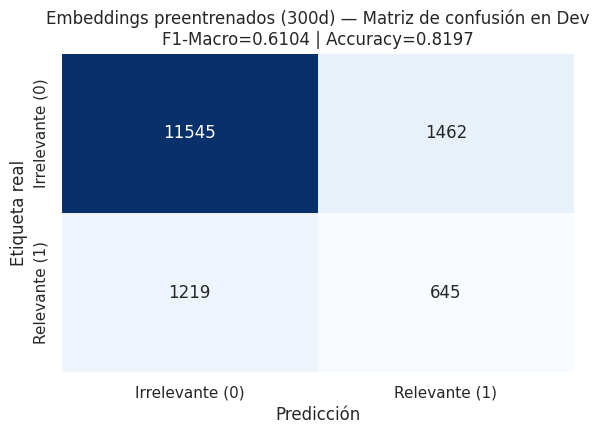

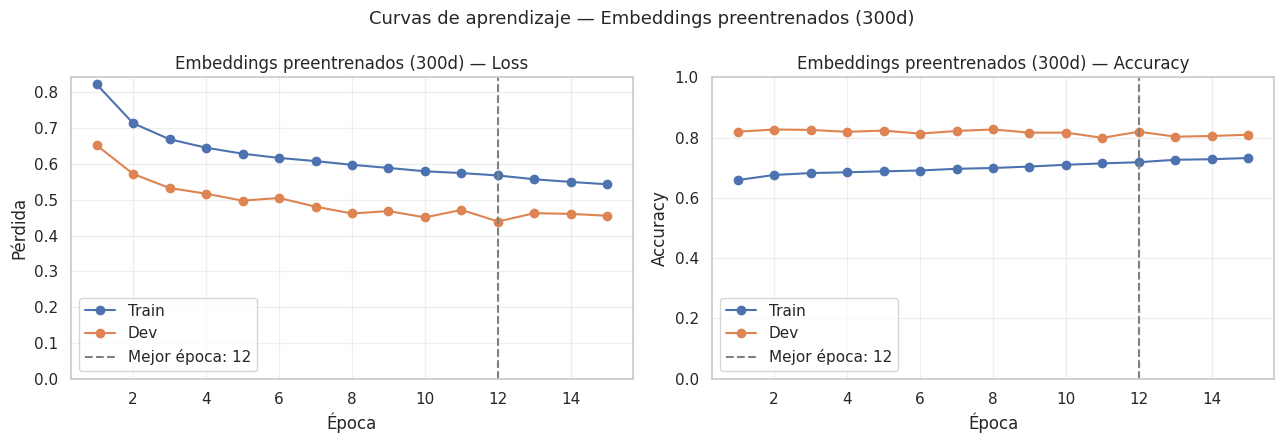


Embeddings preentrenados (300d)
Mejor época según val_loss: 12
F1-Macro en Dev: 0.6104
Accuracy en Dev: 0.8197
Matriz de confusión:
[[11545  1462]
 [ 1219   645]]


In [131]:


graficar_modelo_embeddings(
    nombre="Embeddings preentrenados (300d)",
    historia=historia_pre_300,
    y_real=y_dev_e3,
    predicciones=pred_pre_300,
    f1_macro=resultado_pre_300["F1-Macro Dev"],
    accuracy=resultado_pre_300["Accuracy Dev"]
)

## 3.3 Modelo mejorado a partir del análisis de errores: pregunta y oración separadas
El promedio de embeddings del modelo anterior resume todo el par en un solo vector y no diferencia qué información pertenece a la pregunta y cuál a la oración candidata. Para abordar esa limitación, esta red usa una capa de embeddings **compartida** para ambas entradas y construye cuatro señales: representación de la pregunta, representación de la oración, diferencia absoluta entre ambas y producto elemento a elemento.

La hipótesis es que comparar explícitamente ambas representaciones ayude a distinguir una coincidencia temática de una relación útil para responder, y a reconocer paráfrasis. Es una hipótesis que debe verificarse en Dev: si el F1-Macro no mejora, no afirmaremos que la nueva arquitectura fue superior.

In [132]:
# ============================================================
# ETAPA 3.3 — MODELO PAREADO CON EMBEDDINGS PREENTRENADOS
# La pregunta y la oración comparten la misma capa de embeddings.
# ============================================================

import time
import numpy as np
import tensorflow as tf

from sklearn.metrics import f1_score, accuracy_score
from tensorflow.keras.layers import (
    Input, Embedding, Lambda, Multiply,
    Concatenate, Dense, Dropout
)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2


# ------------------------------------------------------------
# 1. Comprobar que la matriz de embeddings sea válida
# ------------------------------------------------------------

matriz_embeddings_pre = np.asarray(
    matriz_embeddings_pre,
    dtype=np.float32
)

print("Forma de la matriz:", matriz_embeddings_pre.shape)
print("Valores NaN:", np.isnan(matriz_embeddings_pre).sum())
print("Valores infinitos:", np.isinf(matriz_embeddings_pre).sum())

assert matriz_embeddings_pre.shape == (VOCAB_SIZE, DIM_EMBEDDING), (
    "La forma de matriz_embeddings_pre no coincide con "
    "VOCAB_SIZE y DIM_EMBEDDING."
)

assert np.isfinite(matriz_embeddings_pre).all(), (
    "La matriz de embeddings contiene NaN o infinitos. "
    "Hay que corregirla antes de entrenar."
)


# ------------------------------------------------------------
# 2. Entradas separadas para pregunta y oración candidata
# ------------------------------------------------------------

entrada_pregunta = Input(
    shape=(MAX_LEN,),
    dtype="int32",
    name="pregunta_tokens"
)

entrada_oracion = Input(
    shape=(MAX_LEN,),
    dtype="int32",
    name="oracion_tokens"
)


# ------------------------------------------------------------
# 3. Capa de embeddings compartida
# ------------------------------------------------------------

embedding_compartido = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=DIM_EMBEDDING,
    weights=[matriz_embeddings_pre],
    trainable=True,
    mask_zero=False,
    name="embedding_preentrenado_compartido"
)


# ------------------------------------------------------------
# 4. Promedio seguro: ignora el padding y evita dividir por cero
# ------------------------------------------------------------

def promedio_embeddings_seguro(entradas):
    embeddings, tokens = entradas

    # True para tokens reales; False para padding (índice 0).
    tokens_validos = tf.not_equal(tokens, 0)
    mascara_expandida = tf.expand_dims(tokens_validos, axis=-1)

    # Extender la máscara a las dimensiones de los embeddings.
    mascara_bool = tf.broadcast_to(
        mascara_expandida,
        tf.shape(embeddings)
    )

    # Reemplazar los embeddings del padding por ceros.
    embeddings_validos = tf.where(
        mascara_bool,
        embeddings,
        tf.zeros_like(embeddings)
    )

    suma_embeddings = tf.reduce_sum(
        embeddings_validos,
        axis=1
    )

    cantidad_tokens = tf.reduce_sum(
        tf.cast(mascara_expandida, embeddings.dtype),
        axis=1
    )

    # Si la secuencia está vacía, devuelve un vector de ceros.
    return tf.math.divide_no_nan(
        suma_embeddings,
        cantidad_tokens
    )


# Obtener embeddings para las dos entradas usando la misma capa.
embeddings_pregunta = embedding_compartido(entrada_pregunta)
embeddings_oracion = embedding_compartido(entrada_oracion)


# Representación promedio de la pregunta.
vector_pregunta = Lambda(
    promedio_embeddings_seguro,
    output_shape=(DIM_EMBEDDING,),
    name="promedio_pregunta"
)([embeddings_pregunta, entrada_pregunta])


# Representación promedio de la oración candidata.
vector_oracion = Lambda(
    promedio_embeddings_seguro,
    output_shape=(DIM_EMBEDDING,),
    name="promedio_oracion"
)([embeddings_oracion, entrada_oracion])


# ------------------------------------------------------------
# 5. Comparar las representaciones de pregunta y oración
# ------------------------------------------------------------

vector_diferencia = Lambda(
    lambda z: tf.math.abs(z[0] - z[1]),
    output_shape=(DIM_EMBEDDING,),
    name="diferencia_absoluta"
)([vector_pregunta, vector_oracion])

vector_producto = Multiply(
    name="producto_elemento_a_elemento"
)([vector_pregunta, vector_oracion])

caracteristicas_pareadas = Concatenate(
    name="comparacion_pregunta_oracion"
)([
    vector_pregunta,
    vector_oracion,
    vector_diferencia,
    vector_producto
])


# ------------------------------------------------------------
# 6. Red densa clasificadora
# ------------------------------------------------------------

x = Dense(
    128,
    activation="relu",
    kernel_regularizer=l2(0.001),
    name="pareado_densa128"
)(caracteristicas_pareadas)

x = Dropout(
    0.3,
    seed=301,
    name="pareado_dropout03"
)(x)

x = Dense(
    64,
    activation="relu",
    kernel_regularizer=l2(0.001),
    name="pareado_densa64"
)(x)

x = Dropout(
    0.2,
    seed=302,
    name="pareado_dropout02"
)(x)

salida_pareada = Dense(
    1,
    activation="sigmoid",
    name="salida_pareada"
)(x)


# ------------------------------------------------------------
# 7. Compilar el modelo
# ------------------------------------------------------------

modelo_pareado = Model(
    inputs=[entrada_pregunta, entrada_oracion],
    outputs=salida_pareada,
    name="modelo_pareado_preentrenado"
)

modelo_pareado.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

modelo_pareado.summary()


# ------------------------------------------------------------
# 8. Entrenar usando Train y evaluar durante el entrenamiento en Dev
# ------------------------------------------------------------

parada_temprana_pareado = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

tiempo_inicial_pareado = time.time()

historia_pareado = modelo_pareado.fit(
    [X_train_pregunta, X_train_oracion],
    y_train_e3,
    validation_data=(
        [X_dev_pregunta, X_dev_oracion],
        y_dev_e3
    ),
    epochs=15,
    batch_size=256,
    callbacks=[parada_temprana_pareado],
    shuffle=True,
    verbose=1
)

tiempo_pareado = time.time() - tiempo_inicial_pareado


# ------------------------------------------------------------
# 9. Predecir en Dev y comprobar que las probabilidades sean válidas
# ------------------------------------------------------------

prob_pareado = modelo_pareado.predict(
    [X_dev_pregunta, X_dev_oracion],
    batch_size=256,
    verbose=0
).ravel()

cantidad_nan = int(np.isnan(prob_pareado).sum())
cantidad_inf = int(np.isinf(prob_pareado).sum())

print("\nNaN en las probabilidades:", cantidad_nan)
print("Infinitos en las probabilidades:", cantidad_inf)

assert np.isfinite(prob_pareado).all(), (
    "El modelo volvió a producir probabilidades NaN o infinitas. "
    "No interpretar sus métricas; revisar las pérdidas del entrenamiento."
)


# ------------------------------------------------------------
# 10. Evaluar con umbral fijo de 0.50
# ------------------------------------------------------------

pred_pareado = (prob_pareado >= 0.50).astype("int32")

resultado_pareado = {
    "Modelo": "Pregunta–oración por separado (preentrenados 300d)",
    "F1-Macro Dev": f1_score(
        y_dev_e3,
        pred_pareado,
        average="macro",
        zero_division=0
    ),
    "Accuracy Dev": accuracy_score(
        y_dev_e3,
        pred_pareado
    ),
    "Tiempo (segundos)": tiempo_pareado,
    "Parámetros entrenables": int(
        modelo_pareado.count_params()
    )
}

print("\nMODELO PAREADO — umbral 0,50")
print(f"F1-Macro Dev: {resultado_pareado['F1-Macro Dev']:.4f}")
print(f"Accuracy Dev: {resultado_pareado['Accuracy Dev']:.4f}")
print(f"Tiempo: {tiempo_pareado:.2f} segundos")

Forma de la matriz: (20000, 300)
Valores NaN: 0
Valores infinitos: 0


Model: "modelo_pareado_preentrenado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ pregunta_tokens     │ (None, 72)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ oracion_tokens      │ (None, 72)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_preentre… │ (None, 72, 300)   │  6,000,000 │ pregunta_tokens[… │
│ (Embedding)         │                   │            │ oracion_tokens[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ promedio_pregunta   │ (None, 300)       │          0 │ embedding_preent… │
│ (Lambda)            │                   │            │ pregunta_tokens[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ promedio_oracion    │ (None, 300)       │          0 │ embedding_preent… │
│ (Lambda)            │                   │            │ oracion_tokens[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ diferencia_absoluta │ (None, 300)       │          0 │ promedio_pregunt… │
│ (Lambda)            │                   │            │ promedio_oracion… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ producto_elemento_… │ (None, 300)       │          0 │ promedio_pregunt… │
│ (Multiply)          │                   │            │ promedio_oracion… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ comparacion_pregun… │ (None, 1200)      │          0 │ promedio_pregunt… │
│ (Concatenate)       │                   │            │ promedio_oracion… │
│                     │                   │            │ diferencia_absol… │
│                     │                   │            │ producto_element… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pareado_densa128    │ (None, 128)       │    153,728 │ comparacion_preg… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pareado_dropout03   │ (None, 128)       │          0 │ pareado_densa128… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pareado_densa64     │ (None, 64)        │      8,256 │ pareado_dropout0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pareado_dropout02   │ (None, 64)        │          0 │ pareado_densa64[… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ salida_pareada      │ (None, 1)         │         65 │ pareado_dropout0… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,162,049 (23.51 MB)

 Trainable params: 6,162,049 (23.51 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 47s 263ms/step - accuracy: 0.6593 - loss: 0.8708 - val_accuracy: 0.8338 - val_loss: 0.6342
Epoch 2/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 84s 273ms/step - accuracy: 0.6906 - loss: 0.7216 - val_accuracy: 0.8638 - val_loss: 0.5122
Epoch 3/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 80s 260ms/step - accuracy: 0.7035 - loss: 0.6589 - val_accuracy: 0.8392 - val_loss: 0.4908
Epoch 4/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 44s 257ms/step - accuracy: 0.7131 - loss: 0.6172 - val_accuracy: 0.8295 - val_loss: 0.4637
Epoch 5/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 82s 256ms/step - accuracy: 0.7255 - loss: 0.5869 - val_accuracy: 0.8445 - val_loss: 0.4259
Epoch 6/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 44s 257ms/step - accuracy: 0.7358 - loss: 0.5641 - val_accuracy: 0.8068 - val_loss: 0.4547
Epoch 7/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 85s 274ms/step - accuracy: 0.7469 - loss: 0.5431 - val_accuracy: 0.8119 - val_loss: 0.4309
Epoch 8/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 44s 257ms/step - accuracy: 0.7625 - loss: 0

### 3.3.1 Diagnóstico de ajuste y generalización

**Visualización del entrenamiento y evaluación del modelo pareado original.**

Se muestran la matriz de confusión en Dev y las curvas de pérdida y accuracy de Train y Dev. Se reutiliza la función definida en 3.2.5; esta celda no vuelve a entrenar el modelo.

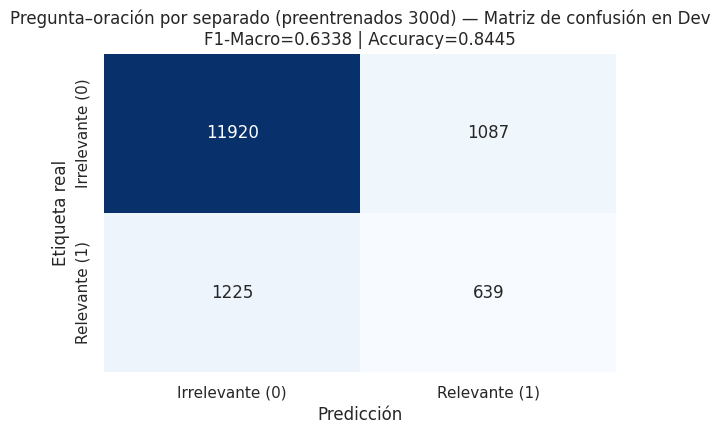

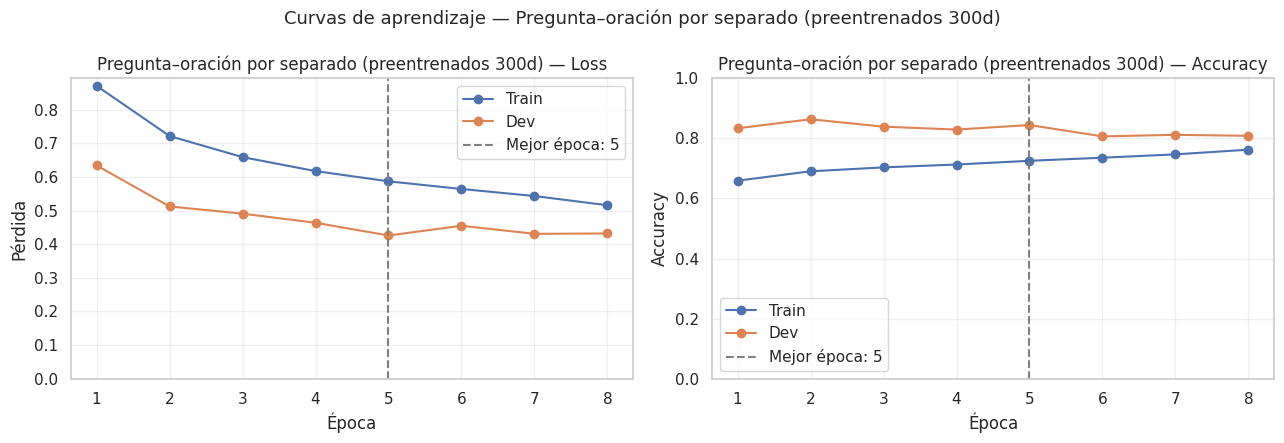


Pregunta–oración por separado (preentrenados 300d)
Mejor época según val_loss: 5
F1-Macro en Dev: 0.6338
Accuracy en Dev: 0.8445
Matriz de confusión:
[[11920  1087]
 [ 1225   639]]


In [133]:

# ============================================================
# ETAPA 3.3.1 — GRÁFICOS DEL MODELO PAREADO
# ============================================================

# Reutilizamos la función de visualización definida en la sección 3.2.5.
# No se vuelve a entrenar el modelo.

graficar_modelo_embeddings(
    nombre="Pregunta–oración por separado (preentrenados 300d)",
    historia=historia_pareado,
    y_real=y_dev_e3,
    predicciones=pred_pareado,
    f1_macro=resultado_pareado["F1-Macro Dev"],
    accuracy=resultado_pareado["Accuracy Dev"]
)


**Resultado del entrenamiento y selección de pesos.** El modelo pareado utiliza embeddings preentrenados compartidos para representar por separado la pregunta y la oración candidata. Se aplicó EarlyStopping con paciencia de 3 épocas, monitoreando la pérdida de validación y restaurando los mejores pesos.

En esta ejecución, el entrenamiento se detuvo al finalizar la época 8 y restauró los pesos de la época 5, que obtuvo la menor `val_loss` observada, de 0,4259. En las épocas posteriores, la pérdida de validación fue mayor, lo que sugiere que continuar entrenando no ofrecía una mejora de validación. La matriz de embeddings no contenía valores NaN ni infinitos, y las probabilidades generadas también fueron finitas.

Con umbral 0,50, el modelo obtuvo un F1-Macro de **0,6338** y una accuracy de **0,8445** en Dev. Frente al F1-Macro de referencia del Modelo 6 de la Etapa 2 (**0,5979**), la mejora fue de **0,0359 puntos**. Este resultado respalda la hipótesis de que representar la pregunta y la oración por separado puede mejorar la clasificación de pares pregunta–oración. La conclusión se basa en Dev y deberá evaluarse sobre Test en la Etapa 5.

#### Interpretación del diagnóstico de ajuste y generalización

El análisis de las curvas de aprendizaje permite identificar diferencias en el comportamiento de los modelos durante el entrenamiento.

En el modelo con embeddings entrenados desde cero, la pérdida de validación alcanzó su mínimo en la época 2 (0,4702). A partir de ese momento aumentó, mientras que la pérdida de entrenamiento continuó disminuyendo. Esta divergencia constituye una señal clara de sobreajuste. El mecanismo EarlyStopping detuvo el entrenamiento en la época 5 y restauró los pesos de la época 2.

En el modelo con embeddings preentrenados, la pérdida de validación mejoró hasta alcanzar su mínimo en la época 12 (0,4393). Aunque posteriormente presentó algunas oscilaciones, no se observó una divergencia marcada entre las curvas de entrenamiento y validación. Por este motivo, no identificamos evidencia suficiente de sobreajuste importante en esta arquitectura.

En el modelo pareado, que representa por separado la pregunta y la oración candidata, la pérdida de validación alcanzó su mínimo en la época 5 (0,4259). En las épocas siguientes aumentó ligeramente, mientras que la pérdida de entrenamiento continuó disminuyendo. Este comportamiento sugiere una señal moderada de sobreajuste. EarlyStopping restauró correctamente los pesos de la época 5.

En cuanto a los modelos Naive Bayes, MultinomialNB no mostró una brecha negativa de F1-Macro entre Train y Dev. ComplementNB presentó una diferencia mayor entre ambos conjuntos, lo que sugiere una generalización menos estable. Sin embargo, esta diferencia debe interpretarse con cautela porque Train y Dev tienen proporciones distintas de ejemplos positivos.

No se encontraron evidencias concluyentes de underfitting en los modelos neuronales. En todos ellos, la pérdida de validación mostró una mejora durante las primeras épocas. Además, la utilización de EarlyStopping con restauración de los mejores pesos permitió conservar los parámetros correspondientes al menor valor de pérdida de validación.

En conclusión, las curvas muestran señales de sobreajuste durante las últimas épocas en el modelo desde cero y en el modelo pareado, pero el mecanismo de parada temprana ya mitiga este comportamiento en los modelos seleccionados. Las arquitecturas originales se conservan como referencia para cualquier experimento posterior de regularización.

### 3.3.2 Experimentos adicionales con regularización reforzada

A partir del análisis de las curvas de aprendizaje, realizamos dos experimentos adicionales para estudiar si una regularización más fuerte puede reducir las señales de sobreajuste observadas en los modelos con embeddings entrenados desde cero y en la arquitectura pareada.

Mantenemos las dimensiones de las redes y los conjuntos de datos utilizados originalmente. Modificamos únicamente la regularización de las capas densas y agregamos Dropout sobre las representaciones antes de la clasificación. También conservamos el optimizador Adam, el tamaño de lote, el máximo de épocas y el mecanismo EarlyStopping.

Los modelos originales no se reemplazan: se mantienen como referencia para comparar los resultados de las nuevas variantes. La comparación se realiza con umbral 0,50, utilizando F1-Macro como métrica principal y accuracy como complemento. También observamos las diferencias entre Train y Dev para evaluar la generalización.

El objetivo no es asumir que una regularización mayor necesariamente mejora el desempeño, sino comprobarlo experimentalmente. Solo consideraremos una variante como mejora si reduce el sobreajuste sin perjudicar el F1-Macro obtenido en Dev.

#### Función auxiliar de evaluación

Antes de los experimentos definimos una función común para calcular las métricas de Train y Dev, las brechas de generalización y la mejor época según `val_loss`. Esta función se reutiliza en los dos modelos regularizados.

In [134]:
# ============================================================
# ETAPA 3.3.2 — IMPORTACIONES Y FUNCIÓN AUXILIAR DE EVALUACIÓN
# ============================================================
# Se conservan los modelos originales.
# Se entrenan dos variantes nuevas:
# 1. Embeddings desde cero con regularización reforzada.
# 2. Modelo pareado con regularización reforzada.
# ============================================================

import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.layers import (
    Input,
    Embedding,
    GlobalAveragePooling1D,
    Dense,
    Dropout,
    Lambda,
    Multiply,
    Concatenate
)
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import f1_score, accuracy_score


# ------------------------------------------------------------
# 1. Función común de evaluación sobre Train y Dev
# ------------------------------------------------------------

def evaluar_generalizacion(
    modelo,
    entrada_train,
    entrada_dev,
    nombre,
    historia,
    tiempo
):
    prob_train = modelo.predict(
        entrada_train,
        batch_size=256,
        verbose=0
    ).ravel()

    prob_dev = modelo.predict(
        entrada_dev,
        batch_size=256,
        verbose=0
    ).ravel()

    pred_train = (prob_train >= 0.50).astype("int32")
    pred_dev = (prob_dev >= 0.50).astype("int32")

    f1_train = f1_score(
        y_train_e3,
        pred_train,
        average="macro",
        zero_division=0
    )

    f1_dev = f1_score(
        y_dev_e3,
        pred_dev,
        average="macro",
        zero_division=0
    )

    acc_train = accuracy_score(y_train_e3, pred_train)
    acc_dev = accuracy_score(y_dev_e3, pred_dev)

    mejor_epoca = int(
        np.argmin(historia.history["val_loss"]) + 1
    )

    return {
        "Modelo": nombre,
        "F1-Macro Train": f1_train,
        "F1-Macro Dev": f1_dev,
        "Brecha F1": f1_train - f1_dev,
        "Accuracy Train": acc_train,
        "Accuracy Dev": acc_dev,
        "Brecha Accuracy": acc_train - acc_dev,
        "Mejor época": mejor_epoca,
        "Tiempo (segundos)": tiempo,
        "Probabilidades Dev": prob_dev,
        "Predicciones Dev": pred_dev
    }


# ------------------------------------------------------------

#### Modelo 1: embeddings desde cero con regularización reforzada

Este experimento mantiene la arquitectura de entradas combinadas y modifica la regularización para comprobar su efecto sobre la generalización.

In [135]:
# 2. NUEVO MODELO: EMBEDDINGS DESDE CERO REGULARIZADOS
# ------------------------------------------------------------

def construir_modelo_cero_regularizado():

    entrada = Input(
        shape=(MAX_LEN,),
        dtype="int32",
        name="secuencia_cero_regularizada"
    )

    embedding = Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=DIM_EMBEDDING,
        embeddings_initializer=tf.keras.initializers.RandomNormal(
            mean=0.0,
            stddev=0.05,
            seed=42
        ),
        trainable=True,
        mask_zero=True,
        name="embedding_cero_regularizado"
    )(entrada)

    x = GlobalAveragePooling1D(
        name="promedio_cero_regularizado"
    )(embedding)

    # Regularización adicional sobre la representación.
    x = Dropout(
        0.20,
        seed=401,
        name="dropout_representacion_cero"
    )(x)

    x = Dense(
        128,
        activation="relu",
        kernel_regularizer=l2(0.002),
        name="densa128_cero_regularizada"
    )(x)

    x = Dropout(
        0.40,
        seed=402,
        name="dropout040_cero"
    )(x)

    x = Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.002),
        name="densa64_cero_regularizada"
    )(x)

    x = Dropout(
        0.30,
        seed=403,
        name="dropout030_cero"
    )(x)

    salida = Dense(
        1,
        activation="sigmoid",
        name="salida_cero_regularizada"
    )(x)

    modelo = Model(
        inputs=entrada,
        outputs=salida,
        name="modelo_cero_regularizado"
    )

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return modelo


# Semilla reproducible.
tf.keras.utils.set_random_seed(42)

modelo_cero_reg = construir_modelo_cero_regularizado()

parada_cero_reg = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

print("ENTRENAMIENTO — EMBEDDINGS DESDE CERO REGULARIZADOS")

inicio_cero_reg = time.time()

historia_cero_reg = modelo_cero_reg.fit(
    X_train_seq,
    y_train_e3,
    validation_data=(X_dev_seq, y_dev_e3),
    epochs=15,
    batch_size=256,
    callbacks=[parada_cero_reg],
    shuffle=True,
    verbose=1
)

tiempo_cero_reg = time.time() - inicio_cero_reg

resultado_cero_reg = evaluar_generalizacion(
    modelo=modelo_cero_reg,
    entrada_train=X_train_seq,
    entrada_dev=X_dev_seq,
    nombre="Embeddings desde cero — regularización reforzada",
    historia=historia_cero_reg,
    tiempo=tiempo_cero_reg
)


# ------------------------------------------------------------

ENTRENAMIENTO — EMBEDDINGS DESDE CERO REGULARIZADOS
Epoch 1/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 26s 137ms/step - accuracy: 0.6577 - loss: 0.7676 - val_accuracy: 0.8747 - val_loss: 0.5081
Epoch 2/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 40s 134ms/step - accuracy: 0.6611 - loss: 0.6165 - val_accuracy: 0.8528 - val_loss: 0.4830
Epoch 3/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 23s 133ms/step - accuracy: 0.7023 - loss: 0.5922 - val_accuracy: 0.8339 - val_loss: 0.4569
Epoch 4/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 41s 133ms/step - accuracy: 0.7372 - loss: 0.5613 - val_accuracy: 0.7806 - val_loss: 0.4788
Epoch 5/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 41s 135ms/step - accuracy: 0.7667 - loss: 0.5298 - val_accuracy: 0.7000 - val_loss: 0.5349
Epoch 6/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 41s 136ms/step - accuracy: 0.7645 - loss: 0.5256 - val_accuracy: 0.7081 - val_loss: 0.5353
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 3.


##### Visualización del modelo con embeddings desde cero regularizados

Se muestra la matriz de confusión en Dev y las curvas de pérdida y accuracy de Train y Dev.

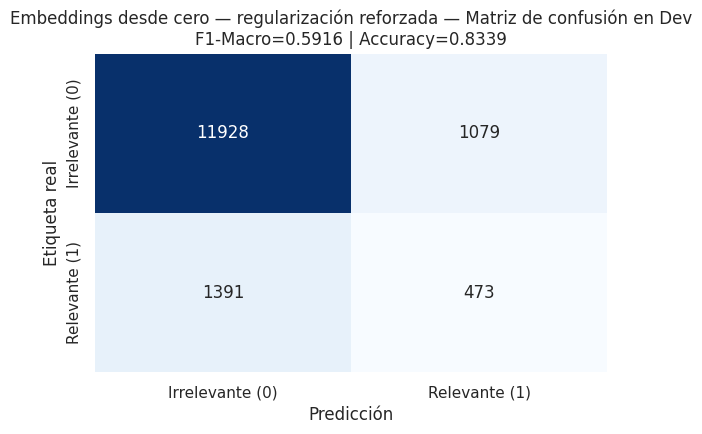

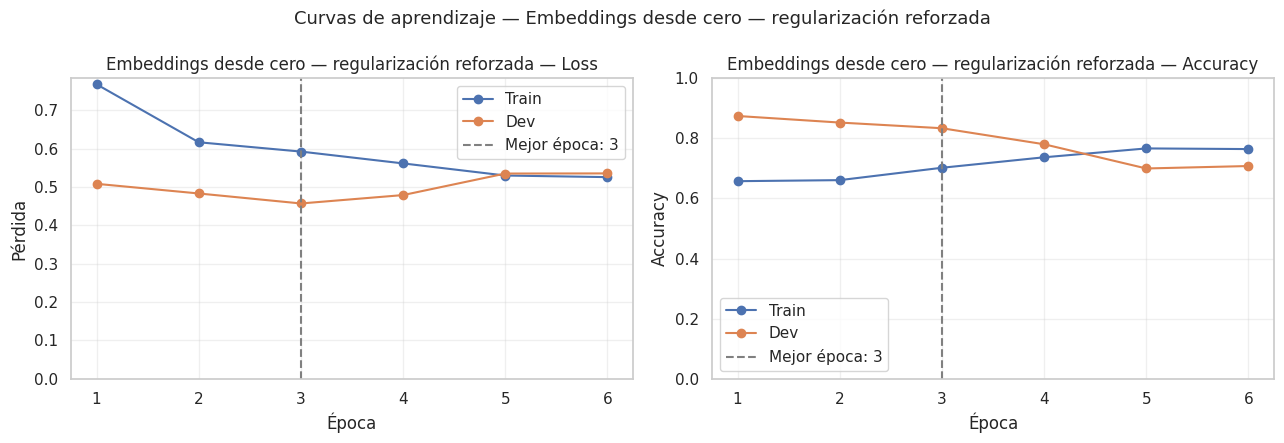


Embeddings desde cero — regularización reforzada
Mejor época según val_loss: 3
F1-Macro en Dev: 0.5916
Accuracy en Dev: 0.8339
Matriz de confusión:
[[11928  1079]
 [ 1391   473]]


In [136]:
# ============================================================
# ETAPA 3.3.2 — GRÁFICOS: EMBEDDINGS DESDE CERO REGULARIZADOS
# ============================================================

graficar_modelo_embeddings(
    nombre="Embeddings desde cero — regularización reforzada",
    historia=historia_cero_reg,
    y_real=y_dev_e3,
    predicciones=resultado_cero_reg["Predicciones Dev"],
    f1_macro=resultado_cero_reg["F1-Macro Dev"],
    accuracy=resultado_cero_reg["Accuracy Dev"]
)

#### Modelo 2: arquitectura pareada con regularización reforzada

Este segundo experimento conserva las dos entradas —pregunta y oración candidata— y la capa de embeddings compartida. Se refuerza la regularización de la representación y de las capas densas.

In [137]:
# 3. NUEVO MODELO PAREADO CON REGULARIZACIÓN REFORZADA
# ------------------------------------------------------------

def construir_modelo_pareado_regularizado():

    entrada_pregunta_reg = Input(
        shape=(MAX_LEN,),
        dtype="int32",
        name="pregunta_tokens_regularizada"
    )

    entrada_oracion_reg = Input(
        shape=(MAX_LEN,),
        dtype="int32",
        name="oracion_tokens_regularizada"
    )

    # Se conserva la matriz preentrenada y se comparte
    # la misma capa entre pregunta y oración.
    embedding_compartido_reg = Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=DIM_EMBEDDING,
        weights=[matriz_embeddings_pre],
        trainable=True,
        mask_zero=False,
        name="embedding_compartido_regularizado"
    )

    embeddings_pregunta_reg = embedding_compartido_reg(
        entrada_pregunta_reg
    )

    embeddings_oracion_reg = embedding_compartido_reg(
        entrada_oracion_reg
    )

    # Reutilizamos la función de promedio seguro de la
    # arquitectura pareada original.
    vector_pregunta_reg = Lambda(
        promedio_embeddings_seguro,
        output_shape=(DIM_EMBEDDING,),
        name="promedio_pregunta_regularizado"
    )([
        embeddings_pregunta_reg,
        entrada_pregunta_reg
    ])

    vector_oracion_reg = Lambda(
        promedio_embeddings_seguro,
        output_shape=(DIM_EMBEDDING,),
        name="promedio_oracion_regularizado"
    )([
        embeddings_oracion_reg,
        entrada_oracion_reg
    ])

    vector_diferencia_reg = Lambda(
        lambda z: tf.math.abs(z[0] - z[1]),
        output_shape=(DIM_EMBEDDING,),
        name="diferencia_absoluta_regularizada"
    )([
        vector_pregunta_reg,
        vector_oracion_reg
    ])

    vector_producto_reg = Multiply(
        name="producto_elemento_regularizado"
    )([
        vector_pregunta_reg,
        vector_oracion_reg
    ])

    caracteristicas_reg = Concatenate(
        name="comparacion_pareada_regularizada"
    )([
        vector_pregunta_reg,
        vector_oracion_reg,
        vector_diferencia_reg,
        vector_producto_reg
    ])

    # Regularización adicional antes de las capas densas.
    x = Dropout(
        0.20,
        seed=411,
        name="dropout_representacion_pareada"
    )(caracteristicas_reg)

    x = Dense(
        128,
        activation="relu",
        kernel_regularizer=l2(0.002),
        name="pareado_densa128_regularizada"
    )(x)

    x = Dropout(
        0.40,
        seed=412,
        name="pareado_dropout040"
    )(x)

    x = Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.002),
        name="pareado_densa64_regularizada"
    )(x)

    x = Dropout(
        0.30,
        seed=413,
        name="pareado_dropout030"
    )(x)

    salida = Dense(
        1,
        activation="sigmoid",
        name="salida_pareada_regularizada"
    )(x)

    modelo = Model(
        inputs=[
            entrada_pregunta_reg,
            entrada_oracion_reg
        ],
        outputs=salida,
        name="modelo_pareado_regularizado"
    )

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return modelo


tf.keras.utils.set_random_seed(42)

modelo_pareado_reg = construir_modelo_pareado_regularizado()

parada_pareado_reg = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

print("\nENTRENAMIENTO — MODELO PAREADO REGULARIZADO")

inicio_pareado_reg = time.time()

historia_pareado_reg = modelo_pareado_reg.fit(
    [
        X_train_pregunta,
        X_train_oracion
    ],
    y_train_e3,
    validation_data=(
        [
            X_dev_pregunta,
            X_dev_oracion
        ],
        y_dev_e3
    ),
    epochs=15,
    batch_size=256,
    callbacks=[parada_pareado_reg],
    shuffle=True,
    verbose=1
)

tiempo_pareado_reg = time.time() - inicio_pareado_reg

resultado_pareado_reg = evaluar_generalizacion(
    modelo=modelo_pareado_reg,
    entrada_train=[
        X_train_pregunta,
        X_train_oracion
    ],
    entrada_dev=[
        X_dev_pregunta,
        X_dev_oracion
    ],
    nombre="Modelo pareado — regularización reforzada",
    historia=historia_pareado_reg,
    tiempo=tiempo_pareado_reg
)


# ------------------------------------------------------------


ENTRENAMIENTO — MODELO PAREADO REGULARIZADO
Epoch 1/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 45s 250ms/step - accuracy: 0.6466 - loss: 1.0875 - val_accuracy: 0.8231 - val_loss: 0.7640
Epoch 2/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 81s 246ms/step - accuracy: 0.6751 - loss: 0.7943 - val_accuracy: 0.8149 - val_loss: 0.6189
Epoch 3/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 82s 244ms/step - accuracy: 0.6838 - loss: 0.6891 - val_accuracy: 0.8346 - val_loss: 0.5139
Epoch 4/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 83s 248ms/step - accuracy: 0.6952 - loss: 0.6389 - val_accuracy: 0.8258 - val_loss: 0.4968
Epoch 5/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 42s 245ms/step - accuracy: 0.6971 - loss: 0.6132 - val_accuracy: 0.8420 - val_loss: 0.4553
Epoch 6/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 86s 267ms/step - accuracy: 0.7049 - loss: 0.5969 - val_accuracy: 0.8295 - val_loss: 0.4516
Epoch 7/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 42s 244ms/step - accuracy: 0.7116 - loss: 0.5839 - val_accuracy: 0.8106 - val_loss: 0.4531
Epoch 8/15
173/173 ━━━━━━━━━━━━━━━━━━━

##### Visualización del modelo pareado regularizado

Se muestra la matriz de confusión en Dev y las curvas de pérdida y accuracy de Train y Dev.

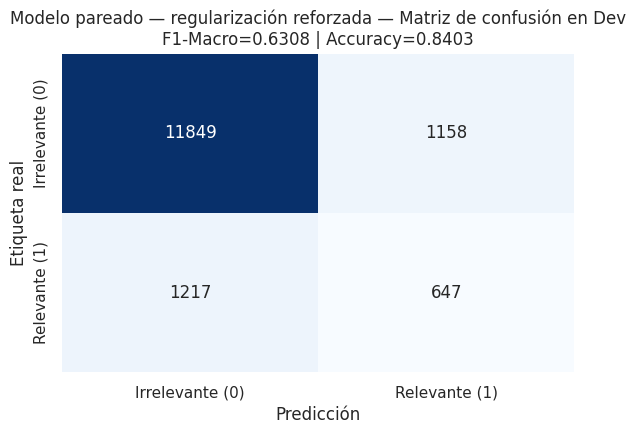

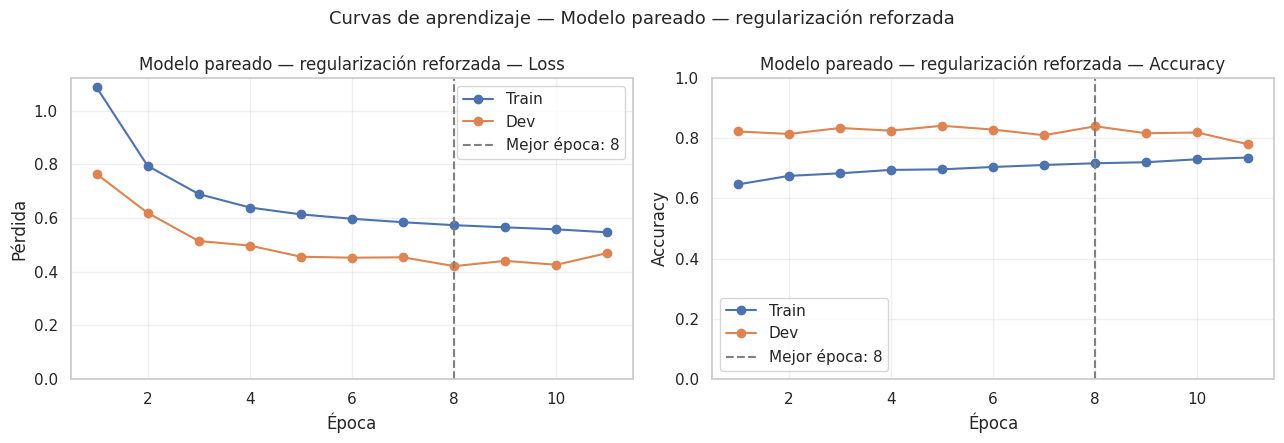


Modelo pareado — regularización reforzada
Mejor época según val_loss: 8
F1-Macro en Dev: 0.6308
Accuracy en Dev: 0.8403
Matriz de confusión:
[[11849  1158]
 [ 1217   647]]


In [138]:
# ============================================================
# ETAPA 3.3.2 — GRÁFICOS: MODELO PAREADO REGULARIZADO
# ============================================================

graficar_modelo_embeddings(
    nombre="Modelo pareado — regularización reforzada",
    historia=historia_pareado_reg,
    y_real=y_dev_e3,
    predicciones=resultado_pareado_reg["Predicciones Dev"],
    f1_macro=resultado_pareado_reg["F1-Macro Dev"],
    accuracy=resultado_pareado_reg["Accuracy Dev"]
)

#### Comparación de los modelos originales y las variantes regularizadas

La tabla compara los resultados de los modelos originales con los de las variantes regularizadas.

In [139]:
# 4. COMPARACIÓN CON LOS MODELOS ORIGINALES
# ------------------------------------------------------------

# Evaluamos también los modelos originales sobre Train y Dev.
# No se vuelven a entrenar ni se modifican sus pesos.

resultado_cero_original_completo = evaluar_generalizacion(
    modelo=modelo_cero_300,
    entrada_train=X_train_seq,
    entrada_dev=X_dev_seq,
    nombre="Embeddings desde cero — original",
    historia=historia_cero_300,
    tiempo=resultado_cero_300["Tiempo (segundos)"]
)

resultado_pareado_original_completo = evaluar_generalizacion(
    modelo=modelo_pareado,
    entrada_train=[
        X_train_pregunta,
        X_train_oracion
    ],
    entrada_dev=[
        X_dev_pregunta,
        X_dev_oracion
    ],
    nombre="Modelo pareado — original",
    historia=historia_pareado,
    tiempo=tiempo_pareado
)

resultados_regularizacion = [
    resultado_cero_original_completo,
    resultado_cero_reg,
    resultado_pareado_original_completo,
    resultado_pareado_reg
]

columnas_comparacion = [
    "Modelo",
    "F1-Macro Train",
    "F1-Macro Dev",
    "Brecha F1",
    "Accuracy Train",
    "Accuracy Dev",
    "Brecha Accuracy",
    "Mejor época",
    "Tiempo (segundos)"
]

tabla_regularizacion = pd.DataFrame(
    resultados_regularizacion
)[columnas_comparacion]

print("\nCOMPARACIÓN — MODELOS ORIGINALES VS REGULARIZADOS")
display(tabla_regularizacion.round(4))


# ------------------------------------------------------------


COMPARACIÓN — MODELOS ORIGINALES VS REGULARIZADOS


,Modelo,F1-Macro Train,F1-Macro Dev,Brecha F1,Accuracy Train,Accuracy Dev,Brecha Accuracy,Mejor época,Tiempo (segundos)
0,Embeddings desde cero — original,0.6157,0.5909,0.0248,0.7184,0.8402,-0.1219,2,170.7300
1,Embeddings desde cero — regularización reforzada,0.6244,0.5916,0.0328,0.7180,0.8339,-0.1159,3,212.3111
2,Modelo pareado — original,0.6567,0.6338,0.0229,0.7380,0.8445,-0.1065,5,548.1792
3,Modelo pareado — regularización reforzada,0.6538,0.6308,0.0230,0.7345,0.8403,-0.1058,8,671.4053


#### Resultados y decisión sobre las variantes regularizadas

Los experimentos con regularización reforzada permitieron evaluar si aumentar Dropout y L2 mejoraba la generalización de los modelos que habían presentado señales de sobreajuste.

En el modelo con embeddings entrenados desde cero, la nueva variante alcanzó su mejor pérdida de validación en la época 3, con un valor aproximado de 0,4569, frente a 0,4702 del modelo original en su época óptima. Sin embargo, el F1-Macro de Dev pasó de 0,5909 a 0,5916, una diferencia muy pequeña. Además, la brecha de F1 entre Train y Dev aumentó de 0,0248 a 0,0328 y la accuracy de Dev disminuyó de 0,8402 a 0,8339.

En el modelo pareado, la variante regularizada obtuvo una pérdida mínima de validación de aproximadamente 0,4201 en la época 8, frente a 0,4259 en la época 5 del modelo original. No obstante, el F1-Macro de Dev disminuyó de 0,6338 a 0,6308 y la accuracy pasó de 0,8445 a 0,8403. La brecha de F1 se mantuvo prácticamente igual.

Estos resultados muestran que una pérdida de validación menor no garantiza necesariamente una mejora en la clasificación con umbral fijo de 0,50. Por este motivo, mantenemos el F1-Macro como criterio principal de selección, acompañado por la accuracy y el análisis de las curvas de aprendizaje.

En consecuencia, conservamos los modelos originales como las versiones principales de la Etapa 3. Las variantes con regularización reforzada quedan documentadas como experimentos adicionales, pero no reemplazan a los modelos originales porque no demostraron una mejora consistente en las métricas de Dev.

El mecanismo EarlyStopping permitió conservar los pesos correspondientes a las mejores épocas de cada entrenamiento. De esta manera, evitamos utilizar las épocas posteriores en las que la pérdida de validación dejó de mejorar.

### 3.3.3 Optimización de las longitudes de entrada del modelo pareado

In [140]:

# ============================================================
# ETAPA 3.3.3 — DIAGNÓSTICO DE LONGITUDES
# No entrena modelos ni modifica las secuencias existentes.
# Los límites se calculan exclusivamente con Train.
# ============================================================

longitudes_pregunta = (
    train_e3["pregunta"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
    .to_numpy()
)

longitudes_oracion = (
    train_e3["oracion"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
    .to_numpy()
)

percentiles = [50, 75, 90, 95, 99, 100]

tabla_longitudes = pd.DataFrame({
    "Percentil": percentiles,
    "Pregunta": [
        int(np.ceil(np.percentile(longitudes_pregunta, p)))
        for p in percentiles
    ],
    "Oración": [
        int(np.ceil(np.percentile(longitudes_oracion, p)))
        for p in percentiles
    ]
})

print("LONGITUDES DE ENTRADA — TRAIN")
display(tabla_longitudes)

# Límites candidatos conservadores: percentil 99 por separado.
LIMITE_PREGUNTA_99 = max(
    10, int(np.ceil(np.percentile(longitudes_pregunta, 99)))
)

LIMITE_ORACION_99 = max(
    10, int(np.ceil(np.percentile(longitudes_oracion, 99)))
)

# Comparación con la configuración actual: 72 + 72 posiciones.
posiciones_actuales = 2 * MAX_LEN
posiciones_candidatas = LIMITE_PREGUNTA_99 + LIMITE_ORACION_99

reduccion_estimada = (
    1 - posiciones_candidatas / posiciones_actuales
) * 100

cobertura_pregunta = (
    np.minimum(longitudes_pregunta, LIMITE_PREGUNTA_99).sum()
    / longitudes_pregunta.sum()
) * 100

cobertura_oracion = (
    np.minimum(longitudes_oracion, LIMITE_ORACION_99).sum()
    / longitudes_oracion.sum()
) * 100

print("\nCOMPARACIÓN DE LONGITUDES")
print(f"Configuración actual: {MAX_LEN} + {MAX_LEN} = {posiciones_actuales} posiciones")
print(
    f"Candidata P99: {LIMITE_PREGUNTA_99} + "
    f"{LIMITE_ORACION_99} = {posiciones_candidatas} posiciones"
)
print(f"Reducción estimada de posiciones: {reduccion_estimada:.2f}%")
print(f"Tokens conservados en preguntas: {cobertura_pregunta:.2f}%")
print(f"Tokens conservados en oraciones: {cobertura_oracion:.2f}%")


LONGITUDES DE ENTRADA — TRAIN


,Percentil,Pregunta,Oración
0,50,8,30
1,75,11,41
2,90,13,53
3,95,15,62
4,99,19,90
5,100,31,257



COMPARACIÓN DE LONGITUDES
Configuración actual: 72 + 72 = 144 posiciones
Candidata P99: 19 + 90 = 109 posiciones
Reducción estimada de posiciones: 24.31%
Tokens conservados en preguntas: 99.72%
Tokens conservados en oraciones: 99.40%


In [141]:

# ============================================================
# ETAPA 3.3.3 — VALIDACIÓN DE LOS LÍMITES P99
# No entrena modelos ni modifica los datos existentes.
# Los límites se calculan exclusivamente con Train.
# ============================================================

def contar_tokens_normalizados(textos):
    textos_tf = tf.constant(textos.tolist(), dtype=tf.string)
    textos_norm = estandarizar_espanol(textos_tf)
    return tf.strings.split(textos_norm).row_lengths().numpy()


# Longitudes usando exactamente la normalización del vectorizador.
q_train_len = contar_tokens_normalizados(preguntas_train)
s_train_len = contar_tokens_normalizados(oraciones_train)

q_dev_len = contar_tokens_normalizados(preguntas_dev)
s_dev_len = contar_tokens_normalizados(oraciones_dev)


# Límites P99 calculados solamente con Train.
MAX_LEN_PREGUNTA = max(
    10, int(np.ceil(np.percentile(q_train_len, 99)))
)

MAX_LEN_ORACION = max(
    10, int(np.ceil(np.percentile(s_train_len, 99)))
)


def resumen_truncamiento(nombre, longitudes, limite):
    ejemplos_truncados = np.sum(longitudes > limite)

    porcentaje_truncado = (
        ejemplos_truncados / len(longitudes) * 100
    )

    tokens_conservados = (
        np.minimum(longitudes, limite).sum()
        / max(longitudes.sum(), 1) * 100
    )

    return {
        "Conjunto": nombre,
        "Límite": limite,
        "Ejemplos truncados": int(ejemplos_truncados),
        "% ejemplos truncados": round(porcentaje_truncado, 2),
        "% tokens conservados": round(tokens_conservados, 2)
    }


tabla_truncamiento = pd.DataFrame([
    resumen_truncamiento("Train - Preguntas", q_train_len, MAX_LEN_PREGUNTA),
    resumen_truncamiento("Train - Oraciones", s_train_len, MAX_LEN_ORACION),
    resumen_truncamiento("Dev - Preguntas", q_dev_len, MAX_LEN_PREGUNTA),
    resumen_truncamiento("Dev - Oraciones", s_dev_len, MAX_LEN_ORACION)
])

print("LÍMITES PROPUESTOS")
print("Pregunta:", MAX_LEN_PREGUNTA)
print("Oración:", MAX_LEN_ORACION)

print("\nANÁLISIS DE TRUNCAMIENTO")
display(tabla_truncamiento)

print("\nCOMPARACIÓN DE POSICIONES")
print("Actual:", MAX_LEN * 2)
print("Propuesta:", MAX_LEN_PREGUNTA + MAX_LEN_ORACION)


LÍMITES PROPUESTOS
Pregunta: 19
Oración: 90

ANÁLISIS DE TRUNCAMIENTO


,Conjunto,Límite,Ejemplos truncados,% ejemplos truncados,% tokens conservados
0,Train - Preguntas,19,404,0.92,99.71
1,Train - Oraciones,90,438,0.99,99.36
2,Dev - Preguntas,19,118,0.79,99.70
3,Dev - Oraciones,90,72,0.48,99.73



COMPARACIÓN DE POSICIONES
Actual: 144
Propuesta: 109


In [142]:

# ============================================================
# ETAPA 3.3.3 — TRUNCAMIENTO SEGÚN LA CLASE
# Comprobamos si se pierden más ejemplos positivos que negativos.
# ============================================================

def reporte_truncamiento_clase(nombre, longitudes, etiquetas, limite):
    filas = []

    for clase in [0, 1]:
        mascara = etiquetas == clase
        longitudes_clase = longitudes[mascara]

        total = len(longitudes_clase)
        truncados = int(np.sum(longitudes_clase > limite))

        filas.append({
            "Conjunto": nombre,
            "Clase": clase,
            "Muestras": total,
            "Truncadas": truncados,
            "% truncadas": round(
                truncados / total * 100, 2
            ) if total else 0
        })

    return filas


resultados_clase = []

resultados_clase += reporte_truncamiento_clase(
    "Train - Preguntas", q_train_len, y_train_e3,
    MAX_LEN_PREGUNTA
)

resultados_clase += reporte_truncamiento_clase(
    "Train - Oraciones", s_train_len, y_train_e3,
    MAX_LEN_ORACION
)

resultados_clase += reporte_truncamiento_clase(
    "Dev - Preguntas", q_dev_len, y_dev_e3,
    MAX_LEN_PREGUNTA
)

resultados_clase += reporte_truncamiento_clase(
    "Dev - Oraciones", s_dev_len, y_dev_e3,
    MAX_LEN_ORACION
)

tabla_clases = pd.DataFrame(resultados_clase)

print("TRUNCAMIENTO SEGÚN LA CLASE")
display(tabla_clases)


TRUNCAMIENTO SEGÚN LA CLASE


,Conjunto,Clase,Muestras,Truncadas,% truncadas
0,Train - Preguntas,0,29069,265,0.91
1,Train - Preguntas,1,15036,139,0.92
2,Train - Oraciones,0,29069,152,0.52
3,Train - Oraciones,1,15036,286,1.90
4,Dev - Preguntas,0,13007,95,0.73
5,Dev - Preguntas,1,1864,23,1.23
6,Dev - Oraciones,0,13007,47,0.36
7,Dev - Oraciones,1,1864,25,1.34


In [143]:

# ============================================================
# ETAPA 3.3.3 — COMPARACIÓN DE LÍMITES PARA ORACIONES
# ============================================================

limite_maximo = max(
    int(s_train_len.max()),
    int(s_dev_len.max())
)

limites = [90, 100, 110, 120, 150, 200, limite_maximo]
limites = sorted(set(limites))

resultados_limites = []

for conjunto, longitudes, etiquetas in [
    ("Train", s_train_len, y_train_e3),
    ("Dev", s_dev_len, y_dev_e3)
]:
    for limite in limites:
        for clase in [0, 1]:
            mascara = etiquetas == clase
            longitudes_clase = longitudes[mascara]

            truncadas = int(np.sum(longitudes_clase > limite))
            total = len(longitudes_clase)

            resultados_limites.append({
                "Conjunto": conjunto,
                "Límite": limite,
                "Clase": clase,
                "Muestras truncadas": truncadas,
                "% truncadas": round(
                    truncadas / total * 100, 2
                ) if total else 0
            })

tabla_limites = pd.DataFrame(resultados_limites)

print("COMPARACIÓN DEL TRUNCAMIENTO DE ORACIONES POR CLASE")
display(tabla_limites)


COMPARACIÓN DEL TRUNCAMIENTO DE ORACIONES POR CLASE


,Conjunto,Límite,Clase,Muestras truncadas,% truncadas
0,Train,90,0,152,0.52
1,Train,90,1,286,1.90
2,Train,100,0,90,0.31
3,Train,100,1,163,1.08
4,Train,110,0,64,0.22
5,Train,110,1,101,0.67
6,Train,120,0,40,0.14
7,Train,120,1,62,0.41
8,Train,150,0,11,0.04
9,Train,150,1,10,0.07


In [144]:

# ============================================================
# ETAPA 3.3.3 — VERIFICACIÓN DE CONSERVACIÓN DE RESPUESTAS
# Comprueba si el truncamiento elimina total o parcialmente
# el fragmento de la respuesta anotada.
# ============================================================

def tokens_normalizados_python(texto):
    texto = str(texto).lower()
    texto = re.sub(patron_puntuacion, " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto.split() if texto else []


def recuperar_posiciones_respuesta(dataset_split, nombre):
    registros = []
    sin_oracion = 0
    offsets_inconsistentes = 0

    for entry_wrapper in dataset_split:
        for doc in entry_wrapper["data"]:
            for para in doc["paragraphs"]:
                contexto = para["context"]
                oraciones_spans = segmentar_oraciones_con_indices(contexto)

                for qa in para["qas"]:
                    respuestas = qa.get("answers", [])

                    if not respuestas:
                        continue

                    respuesta = respuestas[0]
                    answer_start = int(respuesta["answer_start"])
                    answer_text = respuesta["text"]

                    coincidencias = [
                        (oracion, ini, fin)
                        for oracion, ini, fin in oraciones_spans
                        if ini <= answer_start < fin
                    ]

                    if not coincidencias:
                        sin_oracion += 1
                        continue

                    oracion, ini, fin = coincidencias[0]

                    fragmento_original = contexto[ini:fin]
                    espacios_iniciales = (
                        len(fragmento_original)
                        - len(fragmento_original.lstrip())
                    )

                    oracion_limpia = fragmento_original.strip()

                    inicio_relativo = (
                        answer_start - (ini + espacios_iniciales)
                    )

                    fin_relativo = inicio_relativo + len(answer_text)

                    if inicio_relativo < 0 or fin_relativo > len(oracion_limpia):
                        offsets_inconsistentes += 1
                        continue

                    respuesta_en_oracion = oracion_limpia[
                        inicio_relativo:fin_relativo
                    ]

                    if respuesta_en_oracion != answer_text:
                        offsets_inconsistentes += 1
                        continue

                    tokens_antes = len(
                        tokens_normalizados_python(
                            oracion_limpia[:inicio_relativo]
                        )
                    )

                    tokens_respuesta = len(
                        tokens_normalizados_python(respuesta_en_oracion)
                    )

                    registros.append({
                        "Conjunto": nombre,
                        "Tokens antes de respuesta": tokens_antes,
                        "Tokens de respuesta": tokens_respuesta,
                        "Fin de respuesta": tokens_antes + tokens_respuesta
                    })

    return registros, sin_oracion, offsets_inconsistentes


registros_train, sin_train, inconsistentes_train = (
    recuperar_posiciones_respuesta(raw_dataset["train"], "Train")
)

registros_dev, sin_dev, inconsistentes_dev = (
    recuperar_posiciones_respuesta(raw_dataset["validation"], "Dev")
)

respuestas_df = pd.DataFrame(registros_train + registros_dev)

print("VERIFICACIÓN DE RESPUESTAS")
print("Respuestas localizadas en Train:", len(registros_train))
print("Respuestas localizadas en Dev:", len(registros_dev))
print("Sin oración contenedora - Train:", sin_train)
print("Sin oración contenedora - Dev:", sin_dev)
print("Offsets inconsistentes - Train:", inconsistentes_train)
print("Offsets inconsistentes - Dev:", inconsistentes_dev)


# Evaluar distintos límites de oración.
resultados_respuestas = []

for conjunto in ["Train", "Dev"]:
    datos = respuestas_df[
        respuestas_df["Conjunto"] == conjunto
    ]

    total = len(datos)

    for limite in [90, 100, 110, 120, 150]:
        inicio_cortado = (
            datos["Tokens antes de respuesta"] >= limite
        )

        respuesta_parcial = (
            (datos["Tokens antes de respuesta"] < limite)
            & (datos["Fin de respuesta"] > limite)
        )

        respuestas_afectadas = inicio_cortado | respuesta_parcial

        resultados_respuestas.append({
            "Conjunto": conjunto,
            "Límite": limite,
            "Respuestas completas": int((~respuestas_afectadas).sum()),
            "Respuestas afectadas": int(respuestas_afectadas.sum()),
            "% respuestas afectadas": round(
                respuestas_afectadas.mean() * 100, 3
            ) if total else 0
        })

tabla_respuestas = pd.DataFrame(resultados_respuestas)

print("\nCONSERVACIÓN DE LAS RESPUESTAS ANOTADAS")
display(tabla_respuestas)


VERIFICACIÓN DE RESPUESTAS
Respuestas localizadas en Train: 15024
Respuestas localizadas en Dev: 1863
Sin oración contenedora - Train: 0
Sin oración contenedora - Dev: 0
Offsets inconsistentes - Train: 12
Offsets inconsistentes - Dev: 1

CONSERVACIÓN DE LAS RESPUESTAS ANOTADAS


,Conjunto,Límite,Respuestas completas,Respuestas afectadas,% respuestas afectadas
0,Train,90,14984,40,0.266
1,Train,100,14997,27,0.180
2,Train,110,15007,17,0.113
3,Train,120,15012,12,0.080
4,Train,150,15022,2,0.013
5,Dev,90,1858,5,0.268
6,Dev,100,1860,3,0.161
7,Dev,110,1861,2,0.107
8,Dev,120,1862,1,0.054
9,Dev,150,1863,0,0.000


In [145]:

# ETAPA 3.3.3 — COMPARACIÓN DIRECTA: CONFIGURACIÓN ORIGINAL Y LÍMITES CANDIDATOS

resultados_comparacion = []

for conjunto in ["Train", "Dev"]:
    datos = respuestas_df[
        respuestas_df["Conjunto"] == conjunto
    ]

    for limite in [72, 90, 100, 110, 120, 150]:
        inicio_cortado = (
            datos["Tokens antes de respuesta"] >= limite
        )

        respuesta_parcial = (
            (datos["Tokens antes de respuesta"] < limite)
            & (datos["Fin de respuesta"] > limite)
        )

        afectadas = inicio_cortado | respuesta_parcial

        resultados_comparacion.append({
            "Conjunto": conjunto,
            "Límite de oración": limite,
            "Respuestas afectadas": int(afectadas.sum()),
            "% respuestas afectadas": round(
                afectadas.mean() * 100, 3
            )
        })

tabla_comparacion_final = pd.DataFrame(
    resultados_comparacion
)

display(tabla_comparacion_final)


,Conjunto,Límite de oración,Respuestas afectadas,% respuestas afectadas
0,Train,72,122,0.812
1,Train,90,40,0.266
2,Train,100,27,0.180
3,Train,110,17,0.113
4,Train,120,12,0.080
5,Train,150,2,0.013
6,Dev,72,14,0.751
7,Dev,90,5,0.268
8,Dev,100,3,0.161
9,Dev,110,2,0.107


In [146]:

# ============================================================
# ETAPA 3.3.3 — PREPARACIÓN DE ENTRADAS OPTIMIZADAS
# Reutilizamos el vocabulario original y separamos las longitudes.
# No modificamos las entradas ni el modelo original.
# ============================================================

MAX_LEN_PREGUNTA_OPT = 19
MAX_LEN_ORACION_OPT = 100

# Recuperamos el vocabulario ya aprendido exclusivamente con Train.
# TextVectorization reserva los índices 0 y 1 para padding y OOV.
vocabulario_sin_reservados = vocabulario[2:]


# Vectorizador para preguntas.
vectorizador_pregunta_opt = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    standardize=estandarizar_espanol,
    split="whitespace",
    output_mode="int",
    output_sequence_length=MAX_LEN_PREGUNTA_OPT,
    vocabulary=vocabulario_sin_reservados,
    name="vectorizador_pregunta_optimizado"
)


# Vectorizador para oraciones.
vectorizador_oracion_opt = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    standardize=estandarizar_espanol,
    split="whitespace",
    output_mode="int",
    output_sequence_length=MAX_LEN_ORACION_OPT,
    vocabulary=vocabulario_sin_reservados,
    name="vectorizador_oracion_optimizado"
)


# Verificar que ambos vectorizadores conservan el vocabulario original.
assert vectorizador_pregunta_opt.get_vocabulary() == vocabulario
assert vectorizador_oracion_opt.get_vocabulary() == vocabulario


# Generar nuevas secuencias sin modificar las originales.
X_train_pregunta_opt = vectorizador_pregunta_opt(
    preguntas_train
).numpy()

X_train_oracion_opt = vectorizador_oracion_opt(
    oraciones_train
).numpy()

X_dev_pregunta_opt = vectorizador_pregunta_opt(
    preguntas_dev
).numpy()

X_dev_oracion_opt = vectorizador_oracion_opt(
    oraciones_dev
).numpy()


# Comprobar que los índices coinciden con los originales
# en todas las posiciones que ambos tienen en común.
assert np.array_equal(
    X_train_pregunta_opt,
    X_train_pregunta[:, :MAX_LEN_PREGUNTA_OPT]
)

assert np.array_equal(
    X_dev_pregunta_opt,
    X_dev_pregunta[:, :MAX_LEN_PREGUNTA_OPT]
)

assert np.array_equal(
    X_train_oracion_opt[:, :MAX_LEN],
    X_train_oracion
)

assert np.array_equal(
    X_dev_oracion_opt[:, :MAX_LEN],
    X_dev_oracion
)


# Comprobar dimensiones y correspondencia con las etiquetas.
assert X_train_pregunta_opt.shape == (
    len(y_train_e3), MAX_LEN_PREGUNTA_OPT
)

assert X_train_oracion_opt.shape == (
    len(y_train_e3), MAX_LEN_ORACION_OPT
)

assert X_dev_pregunta_opt.shape == (
    len(y_dev_e3), MAX_LEN_PREGUNTA_OPT
)

assert X_dev_oracion_opt.shape == (
    len(y_dev_e3), MAX_LEN_ORACION_OPT
)


print("Vocabulario original conservado:", len(vocabulario))
print("\nDimensiones de las entradas optimizadas:")
print("Train preguntas:", X_train_pregunta_opt.shape)
print("Train oraciones:", X_train_oracion_opt.shape)
print("Dev preguntas:", X_dev_pregunta_opt.shape)
print("Dev oraciones:", X_dev_oracion_opt.shape)

print("\nPosiciones por ejemplo:")
print("Original:", 2 * MAX_LEN)
print(
    "Optimizado:",
    MAX_LEN_PREGUNTA_OPT + MAX_LEN_ORACION_OPT
)

print(
    "Reducción:",
    f"{(1 - (MAX_LEN_PREGUNTA_OPT + MAX_LEN_ORACION_OPT) / (2 * MAX_LEN)) * 100:.2f}%"
)

print("\nTodas las verificaciones finalizaron correctamente.")


Vocabulario original conservado: 20000

Dimensiones de las entradas optimizadas:
Train preguntas: (44105, 19)
Train oraciones: (44105, 100)
Dev preguntas: (14871, 19)
Dev oraciones: (14871, 100)

Posiciones por ejemplo:
Original: 144
Optimizado: 119
Reducción: 17.36%

Todas las verificaciones finalizaron correctamente.


In [147]:

# ============================================================
# ETAPA 3.3.3 — MODELO PAREADO CON ENTRADAS OPTIMIZADAS
# Pregunta: 19 tokens | Oración: 100 tokens
# Misma arquitectura y configuración que el modelo original.
# ============================================================

# ------------------------------------------------------------
# 1. Entradas con longitudes independientes
# ------------------------------------------------------------

entrada_pregunta_opt = Input(
    shape=(MAX_LEN_PREGUNTA_OPT,),
    dtype="int32",
    name="pregunta_tokens_optimizada"
)

entrada_oracion_opt = Input(
    shape=(MAX_LEN_ORACION_OPT,),
    dtype="int32",
    name="oracion_tokens_optimizada"
)


# ------------------------------------------------------------
# 2. Capa de embeddings preentrenados compartida
# ------------------------------------------------------------

embedding_compartido_opt = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=DIM_EMBEDDING,
    weights=[matriz_embeddings_pre],
    trainable=True,
    mask_zero=False,
    name="embedding_preentrenado_compartido_opt"
)


# ------------------------------------------------------------
# 3. Promedio seguro: ignora el padding
# ------------------------------------------------------------

def promedio_embeddings_seguro_opt(entradas):
    embeddings, tokens = entradas

    tokens_validos = tf.not_equal(tokens, 0)
    mascara_expandida = tf.expand_dims(tokens_validos, axis=-1)

    mascara_bool = tf.broadcast_to(
        mascara_expandida,
        tf.shape(embeddings)
    )

    embeddings_validos = tf.where(
        mascara_bool,
        embeddings,
        tf.zeros_like(embeddings)
    )

    suma_embeddings = tf.reduce_sum(
        embeddings_validos,
        axis=1
    )

    cantidad_tokens = tf.reduce_sum(
        tf.cast(mascara_expandida, embeddings.dtype),
        axis=1
    )

    return tf.math.divide_no_nan(
        suma_embeddings,
        cantidad_tokens
    )


# Obtener embeddings usando la misma capa para ambas entradas.
embeddings_pregunta_opt = embedding_compartido_opt(
    entrada_pregunta_opt
)

embeddings_oracion_opt = embedding_compartido_opt(
    entrada_oracion_opt
)


# ------------------------------------------------------------
# 4. Representaciones individuales
# ------------------------------------------------------------

vector_pregunta_opt = Lambda(
    promedio_embeddings_seguro_opt,
    output_shape=(DIM_EMBEDDING,),
    name="promedio_pregunta_opt"
)([embeddings_pregunta_opt, entrada_pregunta_opt])


vector_oracion_opt = Lambda(
    promedio_embeddings_seguro_opt,
    output_shape=(DIM_EMBEDDING,),
    name="promedio_oracion_opt"
)([embeddings_oracion_opt, entrada_oracion_opt])


# ------------------------------------------------------------
# 5. Comparación entre pregunta y oración
# ------------------------------------------------------------

vector_diferencia_opt = Lambda(
    lambda z: tf.math.abs(z[0] - z[1]),
    output_shape=(DIM_EMBEDDING,),
    name="diferencia_absoluta_opt"
)([vector_pregunta_opt, vector_oracion_opt])


vector_producto_opt = Multiply(
    name="producto_elemento_a_elemento_opt"
)([vector_pregunta_opt, vector_oracion_opt])


caracteristicas_pareadas_opt = Concatenate(
    name="comparacion_pregunta_oracion_opt"
)([
    vector_pregunta_opt,
    vector_oracion_opt,
    vector_diferencia_opt,
    vector_producto_opt
])


# ------------------------------------------------------------
# 6. Red densa clasificadora: misma arquitectura original
# ------------------------------------------------------------

x_opt = Dense(
    128,
    activation="relu",
    kernel_regularizer=l2(0.001),
    name="pareado_opt_densa128"
)(caracteristicas_pareadas_opt)

x_opt = Dropout(
    0.3,
    seed=301,
    name="pareado_opt_dropout03"
)(x_opt)

x_opt = Dense(
    64,
    activation="relu",
    kernel_regularizer=l2(0.001),
    name="pareado_opt_densa64"
)(x_opt)

x_opt = Dropout(
    0.2,
    seed=302,
    name="pareado_opt_dropout02"
)(x_opt)

salida_pareada_opt = Dense(
    1,
    activation="sigmoid",
    name="salida_pareada_opt"
)(x_opt)


# ------------------------------------------------------------
# 7. Construir y compilar el modelo
# ------------------------------------------------------------

modelo_pareado_opt = Model(
    inputs=[entrada_pregunta_opt, entrada_oracion_opt],
    outputs=salida_pareada_opt,
    name="modelo_pareado_preentrenado_optimizado"
)

modelo_pareado_opt.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

modelo_pareado_opt.summary()


# ------------------------------------------------------------
# 8. Entrenamiento con las mismas condiciones originales
# ------------------------------------------------------------

parada_temprana_pareado_opt = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

tiempo_inicial_pareado_opt = time.time()

historia_pareado_opt = modelo_pareado_opt.fit(
    [X_train_pregunta_opt, X_train_oracion_opt],
    y_train_e3,
    validation_data=(
        [X_dev_pregunta_opt, X_dev_oracion_opt],
        y_dev_e3
    ),
    epochs=15,
    batch_size=256,
    callbacks=[parada_temprana_pareado_opt],
    shuffle=True,
    verbose=1
)

tiempo_pareado_opt = time.time() - tiempo_inicial_pareado_opt


# ------------------------------------------------------------
# 9. Predicciones en Train y Dev
# ------------------------------------------------------------

prob_pareado_opt_train = modelo_pareado_opt.predict(
    [X_train_pregunta_opt, X_train_oracion_opt],
    batch_size=256,
    verbose=0
).ravel()

prob_pareado_opt_dev = modelo_pareado_opt.predict(
    [X_dev_pregunta_opt, X_dev_oracion_opt],
    batch_size=256,
    verbose=0
).ravel()


assert np.isfinite(prob_pareado_opt_train).all()
assert np.isfinite(prob_pareado_opt_dev).all()


# ------------------------------------------------------------
# 10. Evaluación con umbral fijo de 0.50
# ------------------------------------------------------------

pred_pareado_opt_train = (
    prob_pareado_opt_train >= 0.50
).astype("int32")

pred_pareado_opt_dev = (
    prob_pareado_opt_dev >= 0.50
).astype("int32")


resultado_pareado_opt = {
    "Modelo": "Pregunta–oración optimizado (19 + 100)",
    "F1-Macro Train": f1_score(
        y_train_e3,
        pred_pareado_opt_train,
        average="macro",
        zero_division=0
    ),
    "F1-Macro Dev": f1_score(
        y_dev_e3,
        pred_pareado_opt_dev,
        average="macro",
        zero_division=0
    ),
    "Accuracy Train": accuracy_score(
        y_train_e3,
        pred_pareado_opt_train
    ),
    "Accuracy Dev": accuracy_score(
        y_dev_e3,
        pred_pareado_opt_dev
    ),
    "Tiempo (segundos)": tiempo_pareado_opt,
    "Mejor época": int(
        np.argmin(historia_pareado_opt.history["val_loss"]) + 1
    ),
    "Parámetros entrenables": int(
        modelo_pareado_opt.count_params()
    )
}


print("\nRESULTADOS — MODELO PAREADO OPTIMIZADO")
for clave, valor in resultado_pareado_opt.items():
    if isinstance(valor, (float, np.floating)):
        print(f"{clave}: {valor:.4f}")
    else:
        print(f"{clave}: {valor}")


Model: "modelo_pareado_preentrenado_optimizado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ pregunta_tokens_op… │ (None, 19)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ oracion_tokens_opt… │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_preentre… │ (None, 100, 300)  │  6,000,000 │ pregunta_tokens_… │
│ (Embedding)         │                   │            │ oracion_tokens_o… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ promedio_pregunta_… │ (None, 300)       │          0 │ embedding_preent… │
│ (Lambda)            │                   │            │ pregunta_tokens_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ promedio_oracion_o… │ (None, 300)       │          0 │ embedding_preent… │
│ (Lambda)            │                   │            │ oracion_tokens_o… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ diferencia_absolut… │ (None, 300)       │          0 │ promedio_pregunt… │
│ (Lambda)            │                   │            │ promedio_oracion… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ producto_elemento_… │ (None, 300)       │          0 │ promedio_pregunt… │
│ (Multiply)          │                   │            │ promedio_oracion… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ comparacion_pregun… │ (None, 1200)      │          0 │ promedio_pregunt… │
│ (Concatenate)       │                   │            │ promedio_oracion… │
│                     │                   │            │ diferencia_absol… │
│                     │                   │            │ producto_element… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pareado_opt_densa1… │ (None, 128)       │    153,728 │ comparacion_preg… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pareado_opt_dropou… │ (None, 128)       │          0 │ pareado_opt_dens… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pareado_opt_densa64 │ (None, 64)        │      8,256 │ pareado_opt_drop… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pareado_opt_dropou… │ (None, 64)        │          0 │ pareado_opt_dens… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ salida_pareada_opt  │ (None, 1)         │         65 │ pareado_opt_drop… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,162,049 (23.51 MB)

 Trainable params: 6,162,049 (23.51 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 50s 271ms/step - accuracy: 0.6569 - loss: 0.8786 - val_accuracy: 0.8286 - val_loss: 0.6340
Epoch 2/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 45s 258ms/step - accuracy: 0.6891 - loss: 0.7279 - val_accuracy: 0.8402 - val_loss: 0.5328
Epoch 3/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 45s 259ms/step - accuracy: 0.7023 - loss: 0.6649 - val_accuracy: 0.8340 - val_loss: 0.4953
Epoch 4/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 46s 267ms/step - accuracy: 0.7126 - loss: 0.6241 - val_accuracy: 0.8491 - val_loss: 0.4596
Epoch 5/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 79s 253ms/step - accuracy: 0.7213 - loss: 0.5954 - val_accuracy: 0.8231 - val_loss: 0.4519
Epoch 6/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 44s 255ms/step - accuracy: 0.7332 - loss: 0.5694 - val_accuracy: 0.8344 - val_loss: 0.4166
Epoch 7/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 84s 267ms/step - accuracy: 0.7449 - loss: 0.5455 - val_accuracy: 0.7900 - val_loss: 0.4606
Epoch 8/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 45s 262ms/step - accuracy: 0.7592 - loss: 0

**Visualización del entrenamiento y evaluación del modelo pareado optimizado.**

Se muestran la matriz de confusión en Dev y las curvas de pérdida y accuracy de Train y Dev. Se reutiliza la misma función de visualización del modelo original; esta celda no vuelve a entrenar el modelo.

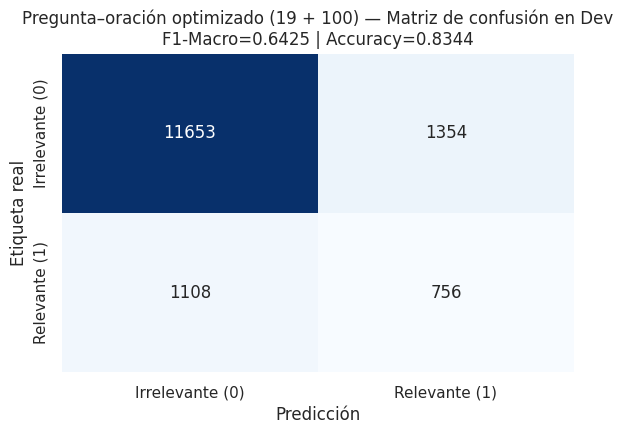

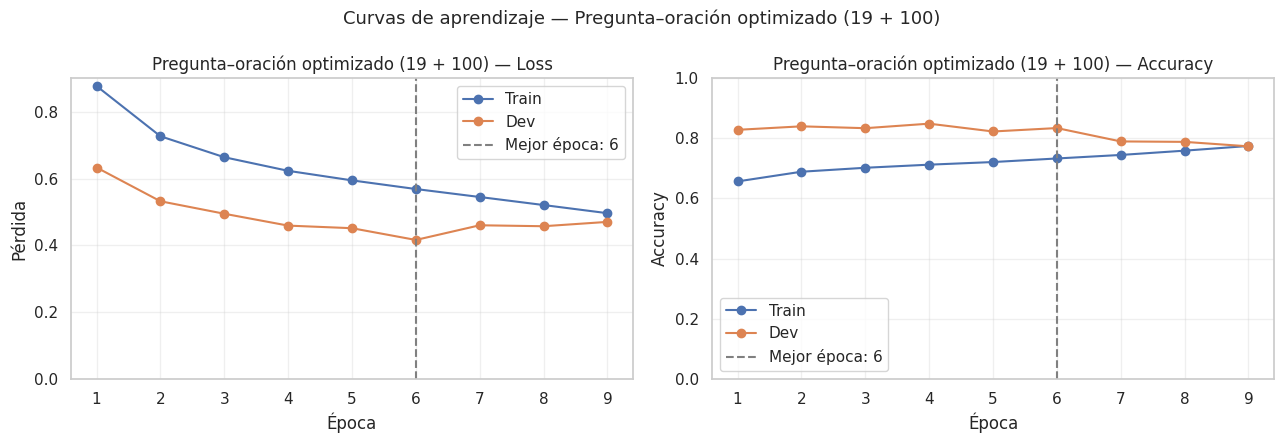


Pregunta–oración optimizado (19 + 100)
Mejor época según val_loss: 6
F1-Macro en Dev: 0.6425
Accuracy en Dev: 0.8344
Matriz de confusión:
[[11653  1354]
 [ 1108   756]]


In [148]:
# ============================================================
# ETAPA 3.3.3 — GRÁFICOS DEL MODELO PAREADO OPTIMIZADO
# ============================================================

graficar_modelo_embeddings(
    nombre="Pregunta–oración optimizado (19 + 100)",
    historia=historia_pareado_opt,
    y_real=y_dev_e3,
    predicciones=pred_pareado_opt_dev,
    f1_macro=resultado_pareado_opt["F1-Macro Dev"],
    accuracy=resultado_pareado_opt["Accuracy Dev"]
)

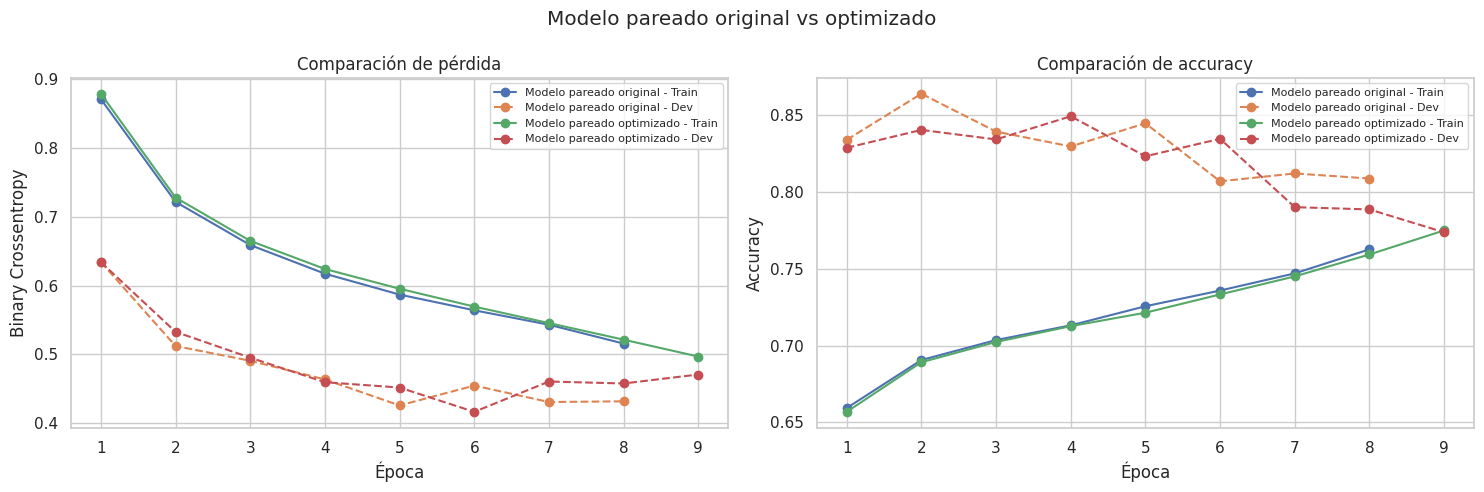

In [149]:

# ============================================================
# ETAPA 3.3.3 — COMPARACIÓN DE CURVAS: MODELO PAREADO ORIGINAL VS OPTIMIZADO
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

historias = [
    (historia_pareado, "Modelo pareado original"),
    (historia_pareado_opt, "Modelo pareado optimizado")
]

for historia, nombre in historias:
    h = historia.history
    epocas_loss = range(1, len(h["loss"]) + 1)
    epocas_acc = range(1, len(h["accuracy"]) + 1)

    axes[0].plot(
        epocas_loss, h["loss"],
        marker="o", label=f"{nombre} - Train"
    )
    axes[0].plot(
        epocas_loss, h["val_loss"],
        marker="o", linestyle="--",
        label=f"{nombre} - Dev"
    )

    axes[1].plot(
        epocas_acc, h["accuracy"],
        marker="o", label=f"{nombre} - Train"
    )
    axes[1].plot(
        epocas_acc, h["val_accuracy"],
        marker="o", linestyle="--",
        label=f"{nombre} - Dev"
    )

axes[0].set_title("Comparación de pérdida")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Binary Crossentropy")
axes[0].legend(fontsize=8)
axes[0].grid(True)

axes[1].set_title("Comparación de accuracy")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend(fontsize=8)
axes[1].grid(True)

fig.suptitle("Modelo pareado original vs optimizado")
plt.tight_layout()
plt.show()


#### Análisis comparativo de las curvas y resultados

Se compararon las curvas de entrenamiento y validación del modelo pareado original y de la variante optimizada mediante longitudes de entrada diferenciadas.

En el modelo original, la menor pérdida de validación se obtuvo en la época 5, con un valor de 0,4259. En las épocas posteriores, la pérdida de entrenamiento continuó descendiendo, mientras que la pérdida de validación presentó fluctuaciones sin superar su mejor resultado. Esto sugiere la presencia de sobreajuste moderado.

En la variante optimizada, la menor pérdida de validación se alcanzó en la época 6, con un valor de 0,4166. A partir de esa época, la pérdida de entrenamiento siguió disminuyendo, pero la pérdida de validación aumentó durante las tres épocas siguientes. Por este motivo, EarlyStopping detuvo el entrenamiento y restauró los pesos de la época 6.

En cuanto al rendimiento, la variante optimizada obtuvo un F1-Macro de 0,6425 en Dev, frente al 0,6338 del modelo original. La accuracy fue de 0,8344 y 0,8445, respectivamente. Por lo tanto, la nueva configuración consiguió una mejora de 0,0087 en F1-Macro, aunque presentó una disminución de 0,0101 en accuracy.

Respecto del tiempo de ejecución, el modelo original tardó 543,34 segundos, mientras que la variante optimizada necesitó 324,79 segundos. La variante optimizada ejecutó 9 épocas, frente a las 8 del modelo original. Por lo tanto, en esta corrida el menor tiempo de entrenamiento (324,79 frente a 543,34 segundos) se observó a pesar de que la variante ejecutó una época más. Como se trata de una única ejecución por configuración, no es posible atribuir esa diferencia temporal exclusivamente a la disminución de posiciones de entrada (de 144 a 119).

En conclusión, la variante optimizada presentó una mejora en F1-Macro y en la pérdida mínima de validación y, en esta ejecución, un menor tiempo de entrenamiento pese a haber ejecutado una época más (9 frente a 8). Por tratarse de una única ejecución, sus resultados se consideran exploratorios. Se conserva el modelo original como referencia y la variante optimizada como una alternativa complementaria, sin reemplazar los resultados históricos.

Ambos modelos muestran señales de sobreajuste moderado, controladas parcialmente mediante EarlyStopping. No se encontró evidencia clara de subajuste.

In [150]:
# ============================================================
# ETAPA 3.3.3 — EVALUACIÓN COMPLEMENTARIA: MODELO PAREADO OPTIMIZADO
# Reporte de clasificación en Dev | Umbral 0.50
# La matriz de confusión y las curvas ya se muestran debajo del entrenamiento.
# ============================================================

print("Reporte de clasificación — modelo pareado optimizado")
print(
    classification_report(
        y_dev_e3,
        pred_pareado_opt_dev,
        target_names=["Irrelevante (0)", "Relevante (1)"],
        digits=4,
        zero_division=0
    )
)

Reporte de clasificación — modelo pareado optimizado
                 precision    recall  f1-score   support

Irrelevante (0)     0.9132    0.8959    0.9045     13007
  Relevante (1)     0.3583    0.4056    0.3805      1864

       accuracy                         0.8344     14871
      macro avg     0.6357    0.6507    0.6425     14871
   weighted avg     0.8436    0.8344    0.8388     14871



#### Interpretación de los resultados del modelo pareado optimizado

El modelo pareado con longitudes de entrada optimizadas obtuvo un **F1-Macro de 0,6425** y una accuracy de **0,8344** en Dev. El reporte de clasificación muestra un desempeño considerablemente mayor en la clase irrelevante (F1 = 0,9045) que en la clase relevante (F1 = 0,3805), lo que refleja que todavía existe una dificultad para identificar las oraciones que contienen respuestas.

La matriz de confusión registra **11.653 verdaderos negativos, 1.354 falsos positivos, 1.108 falsos negativos y 756 verdaderos positivos**. En comparación con el modelo pareado original, la variante optimizada identifica correctamente 117 respuestas relevantes adicionales y reduce en la misma cantidad los falsos negativos. Sin embargo, también genera 267 falsos positivos adicionales.

Este comportamiento se refleja en las métricas de la clase positiva: el recall aumenta aproximadamente de 0,3428 a 0,4056, mientras que la precisión disminuye de 0,3702 a 0,3583. Por lo tanto, el modelo consigue recuperar una mayor proporción de respuestas relevantes, aunque también selecciona más oraciones irrelevantes.

En términos generales, la variante optimizada presenta una mejora de F1-Macro respecto del modelo pareado original, pero pierde algo de accuracy. En esta ejecución redujo el tiempo de entrenamiento pese a ejecutar una época más que el modelo original (9 frente a 8). Como se dispone de una única corrida por configuración, esa diferencia temporal no puede atribuirse exclusivamente a la reducción de las longitudes de entrada. Por eso, estos resultados deben interpretarse como un experimento complementario, y no como evidencia de una mejora general en todos los aspectos del modelo.

### 3.3.4 Ablación: modelo pareado sin Dropout

Después de comparar el modelo pareado original, la variante con regularización reforzada y la optimización de longitudes, incorporamos una prueba de control para estudiar específicamente el efecto de Dropout.

El experimento conserva las **dos entradas independientes** (pregunta y oración), los embeddings preentrenados compartidos, el promedio enmascarado, las características de comparación, las longitudes originales (`MAX_LEN` para ambas entradas), las capas densas y la regularización L2 del modelo pareado original. La única modificación es retirar las dos capas Dropout.

Por lo tanto, este experimento **no elimina toda la regularización**: mantiene L2 y EarlyStopping. Esta decisión permite aislar mejor el efecto de Dropout, en lugar de cambiar varias cosas a la vez. La comparación principal se realiza con umbral fijo de 0,50 y F1-Macro como métrica principal.

#### Entrenamiento del modelo pareado sin Dropout

Se utiliza el mismo Train submuestreado y el mismo Dev completo que en los modelos pareados anteriores. Se conservan Adam (`learning_rate=0.001`), `batch_size=256`, un máximo de 15 épocas y EarlyStopping con paciencia 3, restaurando los pesos de menor `val_loss`.

La semilla se fija en 42 para facilitar la reproducibilidad. El modelo se entrena como un experimento nuevo; sus resultados no se suponen de antemano y se comparan con las salidas obtenidas al ejecutar esta celda.

In [151]:
# ============================================================
# ETAPA 3.3.4 — MODELO PAREADO SIN DROPOUT (ABLACIÓN)
# Mismas condiciones del modelo original; se retira solo Dropout.
# ============================================================

import time
import numpy as np
import tensorflow as tf

from tensorflow.keras.layers import (
    Input, Embedding, Lambda, Multiply, Concatenate, Dense
)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2

# Semilla reproducible para esta nueva corrida.
tf.keras.utils.set_random_seed(42)


def construir_modelo_pareado_sin_dropout():
    # Dos entradas independientes, con las longitudes originales.
    entrada_pregunta_sd = Input(
        shape=(MAX_LEN,), dtype="int32", name="pregunta_tokens_sin_dropout"
    )
    entrada_oracion_sd = Input(
        shape=(MAX_LEN,), dtype="int32", name="oracion_tokens_sin_dropout"
    )

    # La misma matriz preentrenada se comparte entre ambas entradas.
    embedding_compartido_sd = Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=DIM_EMBEDDING,
        weights=[matriz_embeddings_pre],
        trainable=True,
        mask_zero=False,
        name="embedding_compartido_sin_dropout"
    )

    embeddings_pregunta_sd = embedding_compartido_sd(entrada_pregunta_sd)
    embeddings_oracion_sd = embedding_compartido_sd(entrada_oracion_sd)

    vector_pregunta_sd = Lambda(
        promedio_embeddings_seguro,
        output_shape=(DIM_EMBEDDING,),
        name="promedio_pregunta_sin_dropout"
    )([embeddings_pregunta_sd, entrada_pregunta_sd])

    vector_oracion_sd = Lambda(
        promedio_embeddings_seguro,
        output_shape=(DIM_EMBEDDING,),
        name="promedio_oracion_sin_dropout"
    )([embeddings_oracion_sd, entrada_oracion_sd])

    vector_diferencia_sd = Lambda(
        lambda z: tf.math.abs(z[0] - z[1]),
        output_shape=(DIM_EMBEDDING,),
        name="diferencia_absoluta_sin_dropout"
    )([vector_pregunta_sd, vector_oracion_sd])

    vector_producto_sd = Multiply(
        name="producto_elemento_sin_dropout"
    )([vector_pregunta_sd, vector_oracion_sd])

    caracteristicas_sd = Concatenate(
        name="comparacion_pareada_sin_dropout"
    )([
        vector_pregunta_sd,
        vector_oracion_sd,
        vector_diferencia_sd,
        vector_producto_sd
    ])

    # Misma arquitectura densa y misma L2 que el modelo pareado original.
    # No se inserta ninguna capa Dropout.
    x_sd = Dense(
        128,
        activation="relu",
        kernel_regularizer=l2(0.001),
        name="pareado_sin_dropout_densa128"
    )(caracteristicas_sd)

    x_sd = Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.001),
        name="pareado_sin_dropout_densa64"
    )(x_sd)

    salida_sd = Dense(
        1,
        activation="sigmoid",
        name="salida_pareada_sin_dropout"
    )(x_sd)

    modelo_sd = Model(
        inputs=[entrada_pregunta_sd, entrada_oracion_sd],
        outputs=salida_sd,
        name="modelo_pareado_sin_dropout"
    )

    modelo_sd.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return modelo_sd


modelo_pareado_sin_dropout = construir_modelo_pareado_sin_dropout()

# Verificación explícita: el modelo no contiene capas Dropout.
assert not any(
    isinstance(capa, tf.keras.layers.Dropout)
    for capa in modelo_pareado_sin_dropout.layers
), "El modelo de control no debería contener capas Dropout."

print("Resumen del modelo pareado sin Dropout:")
modelo_pareado_sin_dropout.summary()

parada_pareado_sin_dropout = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

inicio_pareado_sin_dropout = time.time()
historia_pareado_sin_dropout = modelo_pareado_sin_dropout.fit(
    [X_train_pregunta, X_train_oracion],
    y_train_e3,
    validation_data=(
        [X_dev_pregunta, X_dev_oracion],
        y_dev_e3
    ),
    epochs=15,
    batch_size=256,
    callbacks=[parada_pareado_sin_dropout],
    shuffle=True,
    verbose=1
)
tiempo_pareado_sin_dropout = time.time() - inicio_pareado_sin_dropout

# Métricas de Train y Dev, brechas y mejor época.
resultado_pareado_sin_dropout = evaluar_generalizacion(
    modelo=modelo_pareado_sin_dropout,
    entrada_train=[X_train_pregunta, X_train_oracion],
    entrada_dev=[X_dev_pregunta, X_dev_oracion],
    nombre="Modelo pareado — sin Dropout (L2 conservada)",
    historia=historia_pareado_sin_dropout,
    tiempo=tiempo_pareado_sin_dropout
)
resultado_pareado_sin_dropout["Parámetros entrenables"] = int(
    modelo_pareado_sin_dropout.count_params()
)

print("\nRESULTADOS — MODELO PAREADO SIN DROPOUT")
for clave, valor in resultado_pareado_sin_dropout.items():
    if clave in {"Probabilidades Dev", "Predicciones Dev"}:
        continue
    if isinstance(valor, (float, np.floating)):
        print(f"{clave}: {valor:.4f}")
    else:
        print(f"{clave}: {valor}")


Resumen del modelo pareado sin Dropout:


Model: "modelo_pareado_sin_dropout"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ pregunta_tokens_si… │ (None, 72)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ oracion_tokens_sin… │ (None, 72)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_comparti… │ (None, 72, 300)   │  6,000,000 │ pregunta_tokens_… │
│ (Embedding)         │                   │            │ oracion_tokens_s… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ promedio_pregunta_… │ (None, 300)       │          0 │ embedding_compar… │
│ (Lambda)            │                   │            │ pregunta_tokens_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ promedio_oracion_s… │ (None, 300)       │          0 │ embedding_compar… │
│ (Lambda)            │                   │            │ oracion_tokens_s… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ diferencia_absolut… │ (None, 300)       │          0 │ promedio_pregunt… │
│ (Lambda)            │                   │            │ promedio_oracion… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ producto_elemento_… │ (None, 300)       │          0 │ promedio_pregunt… │
│ (Multiply)          │                   │            │ promedio_oracion… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ comparacion_paread… │ (None, 1200)      │          0 │ promedio_pregunt… │
│ (Concatenate)       │                   │            │ promedio_oracion… │
│                     │                   │            │ diferencia_absol… │
│                     │                   │            │ producto_element… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pareado_sin_dropou… │ (None, 128)       │    153,728 │ comparacion_pare… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pareado_sin_dropou… │ (None, 64)        │      8,256 │ pareado_sin_drop… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ salida_pareada_sin… │ (None, 1)         │         65 │ pareado_sin_drop… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,162,049 (23.51 MB)

 Trainable params: 6,162,049 (23.51 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 42s 233ms/step - accuracy: 0.6858 - loss: 0.8217 - val_accuracy: 0.7981 - val_loss: 0.6228
Epoch 2/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 38s 222ms/step - accuracy: 0.7130 - loss: 0.6876 - val_accuracy: 0.7963 - val_loss: 0.5561
Epoch 3/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 41s 224ms/step - accuracy: 0.7279 - loss: 0.6262 - val_accuracy: 0.8155 - val_loss: 0.4946
Epoch 4/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 41s 222ms/step - accuracy: 0.7430 - loss: 0.5841 - val_accuracy: 0.8140 - val_loss: 0.4771
Epoch 5/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 39s 225ms/step - accuracy: 0.7580 - loss: 0.5508 - val_accuracy: 0.8082 - val_loss: 0.4709
Epoch 6/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 41s 228ms/step - accuracy: 0.7735 - loss: 0.5195 - val_accuracy: 0.7784 - val_loss: 0.5068
Epoch 7/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 39s 227ms/step - accuracy: 0.7929 - loss: 0.4861 - val_accuracy: 0.7727 - val_loss: 0.5227
Epoch 8/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 41s 228ms/step - accuracy: 0.8166 - loss: 0

#### Diagnóstico visual del modelo pareado sin Dropout

La matriz de confusión y las curvas de aprendizaje permiten evaluar el comportamiento del nuevo modelo. La separación entre `loss` de Train y Dev, junto con la evolución de `val_loss`, se debe interpretar en conjunto con F1-Macro y accuracy; no se concluye que haya sobreajuste únicamente porque se haya quitado Dropout.

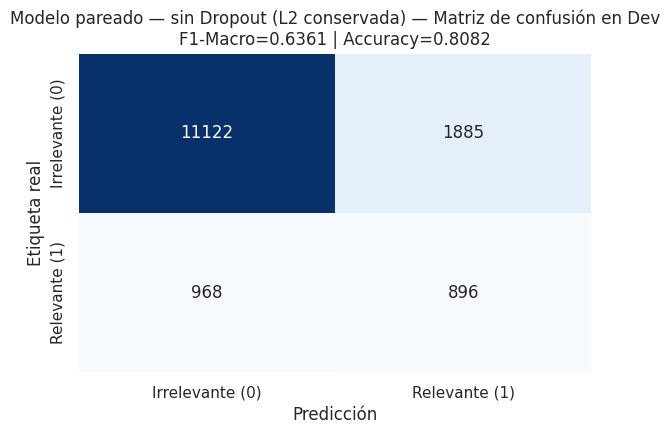

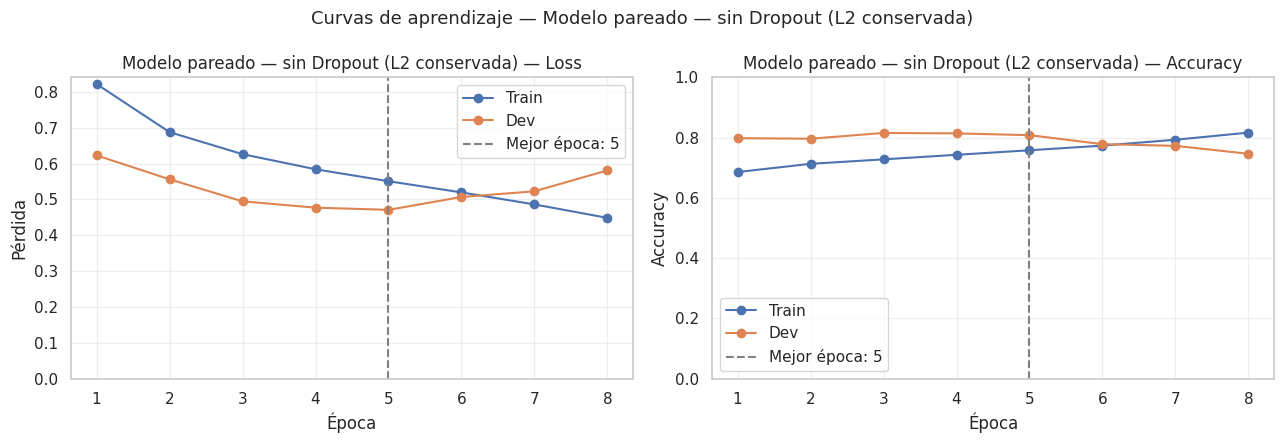


Modelo pareado — sin Dropout (L2 conservada)
Mejor época según val_loss: 5
F1-Macro en Dev: 0.6361
Accuracy en Dev: 0.8082
Matriz de confusión:
[[11122  1885]
 [  968   896]]


In [152]:
# ============================================================
# ETAPA 3.3.4 — GRÁFICOS: MODELO PAREADO SIN DROPOUT
# ============================================================

graficar_modelo_embeddings(
    nombre="Modelo pareado — sin Dropout (L2 conservada)",
    historia=historia_pareado_sin_dropout,
    y_real=y_dev_e3,
    predicciones=resultado_pareado_sin_dropout["Predicciones Dev"],
    f1_macro=resultado_pareado_sin_dropout["F1-Macro Dev"],
    accuracy=resultado_pareado_sin_dropout["Accuracy Dev"]
)

In [153]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    y_dev_e3,
    resultado_pareado_sin_dropout["Predicciones Dev"],
    target_names=["Irrelevante (0)", "Relevante (1)"],
    digits=4
))

print("Matriz de confusión:")
print(confusion_matrix(
    y_dev_e3,
    resultado_pareado_sin_dropout["Predicciones Dev"]
))

                 precision    recall  f1-score   support

Irrelevante (0)     0.9199    0.8551    0.8863     13007
  Relevante (1)     0.3222    0.4807    0.3858      1864

       accuracy                         0.8082     14871
      macro avg     0.6211    0.6679    0.6361     14871
   weighted avg     0.8450    0.8082    0.8236     14871

Matriz de confusión:
[[11122  1885]
 [  968   896]]


In [154]:
from sklearn.metrics import f1_score, accuracy_score

pred_sd = resultado_pareado_sin_dropout["Predicciones Dev"]

print("F1-Macro recalculado:",
      f1_score(y_dev_e3, pred_sd, average="macro"))

print("Accuracy recalculada:",
      accuracy_score(y_dev_e3, pred_sd))

print("F1-Macro guardado:",
      resultado_pareado_sin_dropout["F1-Macro Dev"])

print("Accuracy guardada:",
      resultado_pareado_sin_dropout["Accuracy Dev"])

F1-Macro recalculado: 0.6360561237683042
Accuracy recalculada: 0.8081500907807141
F1-Macro guardado: 0.6360561237683042
Accuracy guardada: 0.8081500907807141


#### Comparación controlada: modelo pareado original vs. sin Dropout

La comparación de interés es entre el modelo pareado original y esta variante sin Dropout. Ambos conservan las mismas entradas, longitudes, embeddings compartidos, dimensiones densas y regularización L2; por ello, el cambio principal es la ausencia de Dropout. Las otras variantes se incluyen como contexto, pero modifican además la regularización o las longitudes.


In [155]:
# Evaluar las variantes pareadas sobre Train y Dev con el mismo umbral (0.50).
resultado_pareado_original_control = evaluar_generalizacion(
    modelo=modelo_pareado,
    entrada_train=[X_train_pregunta, X_train_oracion],
    entrada_dev=[X_dev_pregunta, X_dev_oracion],
    nombre="Pareado original (Dropout 0.30/0.20)",
    historia=historia_pareado,
    tiempo=tiempo_pareado
)

resultado_pareado_regularizado_control = resultado_pareado_reg

resultado_pareado_optimizado_control = evaluar_generalizacion(
    modelo=modelo_pareado_opt,
    entrada_train=[X_train_pregunta_opt, X_train_oracion_opt],
    entrada_dev=[X_dev_pregunta_opt, X_dev_oracion_opt],
    nombre="Pareado optimizado (19 + 100)",
    historia=historia_pareado_opt,
    tiempo=tiempo_pareado_opt
)

resultados_control_pareado = [
    resultado_pareado_original_control,
    resultado_pareado_regularizado_control,
    resultado_pareado_optimizado_control,
    resultado_pareado_sin_dropout
]

tabla_control_pareado = pd.DataFrame(resultados_control_pareado)[
    columnas_comparacion
]

print("COMPARACIÓN DE LOS CUATRO EXPERIMENTOS PAREADOS — UMBRAL 0.50")
display(tabla_control_pareado.round(4))

print("\nDiferencia de F1-Macro Dev: sin Dropout menos pareado original =",
      f"{resultado_pareado_sin_dropout['F1-Macro Dev'] - resultado_pareado_original_control['F1-Macro Dev']:+.4f}")
print("Diferencia de Accuracy Dev: sin Dropout menos pareado original =",
      f"{resultado_pareado_sin_dropout['Accuracy Dev'] - resultado_pareado_original_control['Accuracy Dev']:+.4f}")


COMPARACIÓN DE LOS CUATRO EXPERIMENTOS PAREADOS — UMBRAL 0.50


,Modelo,F1-Macro Train,F1-Macro Dev,Brecha F1,Accuracy Train,Accuracy Dev,Brecha Accuracy,Mejor época,Tiempo (segundos)
0,Pareado original (Dropout 0.30/0.20),0.6567,0.6338,0.0229,0.7380,0.8445,-0.1065,5,548.1792
1,Modelo pareado — regularización reforzada,0.6538,0.6308,0.0230,0.7345,0.8403,-0.1058,8,671.4053
2,Pareado optimizado (19 + 100),0.6917,0.6425,0.0492,0.7541,0.8344,-0.0804,6,519.7427
3,Modelo pareado — sin Dropout (L2 conservada),0.7311,0.6361,0.0950,0.7733,0.8082,-0.0349,5,323.5973



Diferencia de F1-Macro Dev: sin Dropout menos pareado original = +0.0023
Diferencia de Accuracy Dev: sin Dropout menos pareado original = -0.0364


In [156]:
# Calibración exploratoria del umbral en Dev para el modelo pareado original.
# La comparación principal sigue siendo a umbral 0.50.
# Test permanece reservado para la Etapa 5.

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

umbrales_pareado_e3 = np.round(np.arange(0.01, 1.00, 0.01), 2)
filas_umbrales_pareado = []

for umbral in umbrales_pareado_e3:
    pred = (prob_pareado >= umbral).astype("int32")
    tn, fp, fn, tp = confusion_matrix(
        y_dev_e3, pred, labels=[0, 1]
    ).ravel()

    filas_umbrales_pareado.append({
        "Modelo": "Pregunta–oración separadas (300d)",
        "Umbral": float(umbral),
        "F1-Macro": f1_score(
            y_dev_e3, pred, average="macro", zero_division=0
        ),
        "Accuracy": accuracy_score(y_dev_e3, pred),
        "Precision positiva": precision_score(
            y_dev_e3, pred, zero_division=0
        ),
        "Recall positivo": recall_score(
            y_dev_e3, pred, zero_division=0
        ),
        "Falsos positivos": int(fp),
        "Falsos negativos": int(fn)
    })

tabla_umbrales_pareado_e3 = pd.DataFrame(filas_umbrales_pareado)
mejor_indice_pareado = tabla_umbrales_pareado_e3["F1-Macro"].idxmax()

print("Mejor umbral del modelo pareado en Dev:")
display(
    tabla_umbrales_pareado_e3.loc[[mejor_indice_pareado]]
    .round(4)
    .reset_index(drop=True)
)

print("Resultado del modelo pareado a umbral 0.50:")
display(
    tabla_umbrales_pareado_e3[
        np.isclose(tabla_umbrales_pareado_e3["Umbral"], 0.50)
    ].round(4).reset_index(drop=True)
)


Mejor umbral del modelo pareado en Dev:


,Modelo,Umbral,F1-Macro,Accuracy,Precision positiva,Recall positivo,Falsos positivos,Falsos negativos
0,Pregunta–oración separadas (300d),0.46,0.6417,0.8305,0.3516,0.4174,1435,1086


Resultado del modelo pareado a umbral 0.50:


,Modelo,Umbral,F1-Macro,Accuracy,Precision positiva,Recall positivo,Falsos positivos,Falsos negativos
0,Pregunta–oración separadas (300d),0.5,0.6338,0.8445,0.3702,0.3428,1087,1225


### 3.3.5 Calibración exploratoria del umbral del modelo pareado original

En la Etapa 2 observamos que modificar el umbral de clasificación cambia el equilibrio entre falsos positivos y falsos negativos. Aplicamos el mismo procedimiento **al **modelo pareado original con Dropout**, que recibe pregunta y oración como entradas separadas, utilizando exclusivamente el conjunto Dev.

La comparación principal entre arquitecturas se realiza con umbral 0,50. En esta ejecución, el modelo pareado obtuvo F1-Macro **0,6338** con ese umbral. Como análisis complementario, la búsqueda alcanzó un F1-Macro de **0,6417** con umbral **0,46**. Este punto de corte aumenta el recall de la clase positiva respecto de 0,50, aunque también produce más falsos positivos; por eso, la selección del umbral depende del equilibrio entre ambos tipos de error.

El resultado calibrado es exploratorio, ya que el umbral se seleccionó utilizando Dev. La evaluación final sobre Test permanece reservada para la Etapa 5.


In [157]:
# Calibración exploratoria del umbral en Dev para el modelo pareado original.
# La comparación principal sigue siendo a umbral 0.50.
# Test permanece reservado para la Etapa 5.

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

umbrales_pareado_e3 = np.round(np.arange(0.01, 1.00, 0.01), 2)
filas_umbrales_pareado = []

for umbral in umbrales_pareado_e3:
    pred = (prob_pareado >= umbral).astype("int32")
    tn, fp, fn, tp = confusion_matrix(
        y_dev_e3, pred, labels=[0, 1]
    ).ravel()

    filas_umbrales_pareado.append({
        "Modelo": "Pregunta–oración separadas (300d)",
        "Umbral": float(umbral),
        "F1-Macro": f1_score(
            y_dev_e3, pred, average="macro", zero_division=0
        ),
        "Accuracy": accuracy_score(y_dev_e3, pred),
        "Precision positiva": precision_score(
            y_dev_e3, pred, zero_division=0
        ),
        "Recall positivo": recall_score(
            y_dev_e3, pred, zero_division=0
        ),
        "Falsos positivos": int(fp),
        "Falsos negativos": int(fn)
    })

tabla_umbrales_pareado_e3 = pd.DataFrame(filas_umbrales_pareado)
mejor_indice_pareado = tabla_umbrales_pareado_e3["F1-Macro"].idxmax()

print("Mejor umbral del modelo pareado en Dev:")
display(
    tabla_umbrales_pareado_e3.loc[[mejor_indice_pareado]]
    .round(4)
    .reset_index(drop=True)
)

print("Resultado del modelo pareado a umbral 0.50:")
display(
    tabla_umbrales_pareado_e3[
        np.isclose(tabla_umbrales_pareado_e3["Umbral"], 0.50)
    ].round(4).reset_index(drop=True)
)


Mejor umbral del modelo pareado en Dev:


,Modelo,Umbral,F1-Macro,Accuracy,Precision positiva,Recall positivo,Falsos positivos,Falsos negativos
0,Pregunta–oración separadas (300d),0.46,0.6417,0.8305,0.3516,0.4174,1435,1086


Resultado del modelo pareado a umbral 0.50:


,Modelo,Umbral,F1-Macro,Accuracy,Precision positiva,Recall positivo,Falsos positivos,Falsos negativos
0,Pregunta–oración separadas (300d),0.5,0.6338,0.8445,0.3702,0.3428,1087,1225


### 3.3.6 Entrenamiento extendido del mejor modelo de la Etapa 3

En las ejecuciones registradas hasta aquí, el mejor F1-Macro de Dev de la Etapa 3 corresponde al **modelo pareado con longitudes optimizadas**: pregunta de 19 tokens y oración candidata de 100 tokens. Su resultado de referencia fue F1-Macro **0,6425** y accuracy **0,8344**, con un máximo de 15 épocas y `EarlyStopping` con paciencia 3.

En este experimento estudiamos si darle un presupuesto de entrenamiento mayor permite mejorar ese resultado. Conservamos la arquitectura, los embeddings preentrenados de 300 dimensiones, las dos entradas separadas, las longitudes 19 + 100, las capas densas, la regularización L2, las tasas de `Dropout`, el optimizador Adam, el tamaño de lote y los conjuntos Train/Dev. **La única modificación del protocolo de entrenamiento es ampliar el máximo a 100 épocas y la paciencia de `EarlyStopping` a 15.**

Construimos una instancia nueva del mismo modelo e inicializamos la capa de embeddings con la misma matriz preentrenada. No continuamos desde los pesos ya ajustados en la corrida anterior: así la prueba comienza desde una inicialización comparable y permite evaluar el efecto de cambiar el presupuesto de entrenamiento. La selección de pesos sigue dependiendo de `val_loss` en Dev y se restauran los mejores pesos. Test permanece reservado para la Etapa 5.

La nueva corrida se incorpora a la comparación de la sección 3.4 junto con el modelo optimizado original. El criterio principal continúa siendo F1-Macro con umbral 0,50; accuracy y métricas por clase se informan como complemento.


RESUMEN — MODELO PAREADO OPTIMIZADO, ENTRENAMIENTO EXTENDIDO


Model: "modelo_pareado_preentrenado_optimizado_100ep"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ pregunta_tokens_op… │ (None, 19)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ oracion_tokens_opt… │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_preentre… │ (None, 100, 300)  │  6,000,000 │ pregunta_tokens_… │
│ (Embedding)         │                   │            │ oracion_tokens_o… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ promedio_pregunta_… │ (None, 300)       │          0 │ embedding_preent… │
│ (Lambda)            │                   │            │ pregunta_tokens_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ promedio_oracion_o… │ (None, 300)       │          0 │ embedding_preent… │
│ (Lambda)            │                   │            │ oracion_tokens_o… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ diferencia_absolut… │ (None, 300)       │          0 │ promedio_pregunt… │
│ (Lambda)            │                   │            │ promedio_oracion… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ producto_elemento_… │ (None, 300)       │          0 │ promedio_pregunt… │
│ (Multiply)          │                   │            │ promedio_oracion… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ comparacion_pregun… │ (None, 1200)      │          0 │ promedio_pregunt… │
│ (Concatenate)       │                   │            │ promedio_oracion… │
│                     │                   │            │ diferencia_absol… │
│                     │                   │            │ producto_element… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pareado_opt_100ep_… │ (None, 128)       │    153,728 │ comparacion_preg… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pareado_opt_100ep_… │ (None, 128)       │          0 │ pareado_opt_100e… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pareado_opt_100ep_… │ (None, 64)        │      8,256 │ pareado_opt_100e… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pareado_opt_100ep_… │ (None, 64)        │          0 │ pareado_opt_100e… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ salida_pareada_opt… │ (None, 1)         │         65 │ pareado_opt_100e… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,162,049 (23.51 MB)

 Trainable params: 6,162,049 (23.51 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 38s 206ms/step - accuracy: 0.6598 - loss: 0.8585 - val_accuracy: 0.8410 - val_loss: 0.6275
Epoch 2/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 41s 205ms/step - accuracy: 0.6891 - loss: 0.7143 - val_accuracy: 0.8519 - val_loss: 0.5137
Epoch 3/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 41s 205ms/step - accuracy: 0.7040 - loss: 0.6496 - val_accuracy: 0.8402 - val_loss: 0.4672
Epoch 4/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 36s 210ms/step - accuracy: 0.7147 - loss: 0.6113 - val_accuracy: 0.8246 - val_loss: 0.4667
Epoch 5/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 37s 213ms/step - accuracy: 0.7225 - loss: 0.5851 - val_accuracy: 0.8428 - val_loss: 0.4163
Epoch 6/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 36s 208ms/step - accuracy: 0.7362 - loss: 0.5594 - val_accuracy: 0.8187 - val_loss: 0.4350
Epoch 7/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 37s 214ms/step - accuracy: 0.7480 - loss: 0.5393 - val_accuracy: 0.8106 - val_loss: 0.4410
Epoch 8/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 37s 212ms/step - accuracy: 0.7601 -

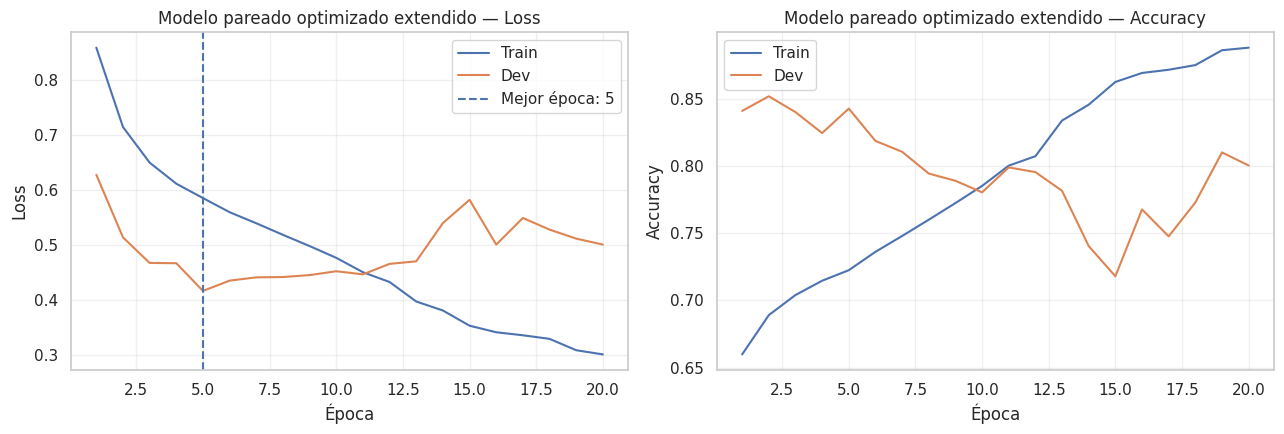

In [158]:
# ============================================================
# ETAPA 3.3.6 — ENTRENAMIENTO EXTENDIDO DEL MEJOR MODELO
# Modelo pareado optimizado: pregunta 19 tokens + oración 100 tokens
# Máximo 100 épocas | EarlyStopping patience=15
# ============================================================

import time
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Semilla para facilitar la reproducibilidad de esta nueva corrida.
tf.keras.utils.set_random_seed(42)

# ------------------------------------------------------------
# 1. Construcción de una instancia nueva de la misma arquitectura
# ------------------------------------------------------------

def promedio_embeddings_seguro_extendido(entradas):
    embeddings, tokens = entradas
    mascara = tf.not_equal(tokens, 0)
    mascara_expandida = tf.expand_dims(mascara, axis=-1)
    mascara_completa = tf.broadcast_to(mascara_expandida, tf.shape(embeddings))
    embeddings_validos = tf.where(
        mascara_completa,
        embeddings,
        tf.zeros_like(embeddings)
    )
    suma = tf.reduce_sum(embeddings_validos, axis=1)
    cantidad = tf.reduce_sum(
        tf.cast(mascara_expandida, embeddings.dtype),
        axis=1
    )
    return tf.math.divide_no_nan(suma, cantidad)


entrada_pregunta_opt_100 = tf.keras.layers.Input(
    shape=(MAX_LEN_PREGUNTA_OPT,),
    dtype="int32",
    name="pregunta_tokens_opt_100ep"
)
entrada_oracion_opt_100 = tf.keras.layers.Input(
    shape=(MAX_LEN_ORACION_OPT,),
    dtype="int32",
    name="oracion_tokens_opt_100ep"
)

# Se vuelve a inicializar con la misma matriz de embeddings preentrenados.
embedding_compartido_opt_100 = tf.keras.layers.Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=DIM_EMBEDDING,
    weights=[matriz_embeddings_pre],
    trainable=True,
    mask_zero=False,
    name="embedding_preentrenado_compartido_opt_100ep"
)

embeddings_pregunta_opt_100 = embedding_compartido_opt_100(
    entrada_pregunta_opt_100
)
embeddings_oracion_opt_100 = embedding_compartido_opt_100(
    entrada_oracion_opt_100
)

vector_pregunta_opt_100 = tf.keras.layers.Lambda(
    promedio_embeddings_seguro_extendido,
    output_shape=(DIM_EMBEDDING,),
    name="promedio_pregunta_opt_100ep"
)([embeddings_pregunta_opt_100, entrada_pregunta_opt_100])

vector_oracion_opt_100 = tf.keras.layers.Lambda(
    promedio_embeddings_seguro_extendido,
    output_shape=(DIM_EMBEDDING,),
    name="promedio_oracion_opt_100ep"
)([embeddings_oracion_opt_100, entrada_oracion_opt_100])

vector_diferencia_opt_100 = tf.keras.layers.Lambda(
    lambda z: tf.math.abs(z[0] - z[1]),
    output_shape=(DIM_EMBEDDING,),
    name="diferencia_absoluta_opt_100ep"
)([vector_pregunta_opt_100, vector_oracion_opt_100])

vector_producto_opt_100 = tf.keras.layers.Multiply(
    name="producto_elemento_a_elemento_opt_100ep"
)([vector_pregunta_opt_100, vector_oracion_opt_100])

caracteristicas_pareadas_opt_100 = tf.keras.layers.Concatenate(
    name="comparacion_pregunta_oracion_opt_100ep"
)([
    vector_pregunta_opt_100,
    vector_oracion_opt_100,
    vector_diferencia_opt_100,
    vector_producto_opt_100
])

x_opt_100 = tf.keras.layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=tf.keras.regularizers.l2(0.001),
    name="pareado_opt_100ep_densa128"
)(caracteristicas_pareadas_opt_100)
x_opt_100 = tf.keras.layers.Dropout(
    0.3,
    seed=301,
    name="pareado_opt_100ep_dropout03"
)(x_opt_100)
x_opt_100 = tf.keras.layers.Dense(
    64,
    activation="relu",
    kernel_regularizer=tf.keras.regularizers.l2(0.001),
    name="pareado_opt_100ep_densa64"
)(x_opt_100)
x_opt_100 = tf.keras.layers.Dropout(
    0.2,
    seed=302,
    name="pareado_opt_100ep_dropout02"
)(x_opt_100)
salida_pareada_opt_100 = tf.keras.layers.Dense(
    1,
    activation="sigmoid",
    name="salida_pareada_opt_100ep"
)(x_opt_100)

modelo_pareado_opt_100 = tf.keras.Model(
    inputs=[entrada_pregunta_opt_100, entrada_oracion_opt_100],
    outputs=salida_pareada_opt_100,
    name="modelo_pareado_preentrenado_optimizado_100ep"
)
modelo_pareado_opt_100.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("RESUMEN — MODELO PAREADO OPTIMIZADO, ENTRENAMIENTO EXTENDIDO")
modelo_pareado_opt_100.summary()

# ------------------------------------------------------------
# 2. Entrenamiento: 100 épocas como máximo y paciencia 15
# ------------------------------------------------------------

parada_pareado_opt_100 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

inicio_pareado_opt_100 = time.time()
historia_pareado_opt_100 = modelo_pareado_opt_100.fit(
    [X_train_pregunta_opt, X_train_oracion_opt],
    y_train_e3,
    validation_data=(
        [X_dev_pregunta_opt, X_dev_oracion_opt],
        y_dev_e3
    ),
    epochs=100,
    batch_size=256,
    callbacks=[parada_pareado_opt_100],
    shuffle=True,
    verbose=1
)
tiempo_pareado_opt_100 = time.time() - inicio_pareado_opt_100

# ------------------------------------------------------------
# 3. Predicciones y métricas con umbral fijo 0.50
# ------------------------------------------------------------

prob_pareado_opt_100_train = modelo_pareado_opt_100.predict(
    [X_train_pregunta_opt, X_train_oracion_opt],
    batch_size=256,
    verbose=0
).ravel()
prob_pareado_opt_100_dev = modelo_pareado_opt_100.predict(
    [X_dev_pregunta_opt, X_dev_oracion_opt],
    batch_size=256,
    verbose=0
).ravel()

pred_pareado_opt_100_train = (
    prob_pareado_opt_100_train >= 0.50
).astype("int32")
pred_pareado_opt_100_dev = (
    prob_pareado_opt_100_dev >= 0.50
).astype("int32")

assert np.isfinite(prob_pareado_opt_100_train).all()
assert np.isfinite(prob_pareado_opt_100_dev).all()

f1_train_opt_100 = f1_score(
    y_train_e3, pred_pareado_opt_100_train,
    average="macro", zero_division=0
)
f1_dev_opt_100 = f1_score(
    y_dev_e3, pred_pareado_opt_100_dev,
    average="macro", zero_division=0
)
acc_train_opt_100 = accuracy_score(y_train_e3, pred_pareado_opt_100_train)
acc_dev_opt_100 = accuracy_score(y_dev_e3, pred_pareado_opt_100_dev)
mejor_epoca_opt_100 = int(
    np.argmin(historia_pareado_opt_100.history["val_loss"]) + 1
)
epocas_ejecutadas_opt_100 = len(historia_pareado_opt_100.history["loss"])

resultado_pareado_opt_100 = {
    "Modelo": "Pareado optimizado — 100 épocas máx., paciencia 15",
    "F1-Macro Train": f1_train_opt_100,
    "F1-Macro Dev": f1_dev_opt_100,
    "Brecha F1": f1_train_opt_100 - f1_dev_opt_100,
    "Accuracy Train": acc_train_opt_100,
    "Accuracy Dev": acc_dev_opt_100,
    "Brecha Accuracy": acc_train_opt_100 - acc_dev_opt_100,
    "Mejor época": mejor_epoca_opt_100,
    "Épocas ejecutadas": epocas_ejecutadas_opt_100,
    "Tiempo (segundos)": tiempo_pareado_opt_100,
    "Parámetros entrenables": int(modelo_pareado_opt_100.count_params()),
    "Probabilidades Dev": prob_pareado_opt_100_dev,
    "Predicciones Dev": pred_pareado_opt_100_dev
}

print("\nRESULTADOS — MODELO PAREADO OPTIMIZADO CON ENTRENAMIENTO EXTENDIDO")
for clave, valor in resultado_pareado_opt_100.items():
    if clave in {"Probabilidades Dev", "Predicciones Dev"}:
        continue
    if isinstance(valor, (float, np.floating)):
        print(f"{clave}: {valor:.4f}")
    else:
        print(f"{clave}: {valor}")

print("\nREPORTE DE CLASIFICACIÓN EN DEV — UMBRAL 0.50")
print(classification_report(
    y_dev_e3,
    pred_pareado_opt_100_dev,
    labels=[0, 1],
    target_names=["Irrelevante (0)", "Relevante (1)"],
    digits=4,
    zero_division=0
))

print("MATRIZ DE CONFUSIÓN EN DEV:")
print(confusion_matrix(y_dev_e3, pred_pareado_opt_100_dev, labels=[0, 1]))

print("\nDIFERENCIA RESPECTO DEL PAREADO OPTIMIZADO ORIGINAL")
print(
    "Diferencia de F1-Macro Dev:",
    f"{f1_dev_opt_100 - resultado_pareado_optimizado_control['F1-Macro Dev']:+.4f}"
)
print(
    "Diferencia de Accuracy Dev:",
    f"{acc_dev_opt_100 - resultado_pareado_optimizado_control['Accuracy Dev']:+.4f}"
)

# ------------------------------------------------------------
# 4. Curvas de aprendizaje para diagnosticar generalización
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
epocas_opt_100 = range(1, epocas_ejecutadas_opt_100 + 1)
axes[0].plot(
    epocas_opt_100,
    historia_pareado_opt_100.history["loss"],
    label="Train"
)
axes[0].plot(
    epocas_opt_100,
    historia_pareado_opt_100.history["val_loss"],
    label="Dev"
)
axes[0].axvline(
    mejor_epoca_opt_100,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca_opt_100}"
)
axes[0].set_title("Modelo pareado optimizado extendido — Loss")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    epocas_opt_100,
    historia_pareado_opt_100.history["accuracy"],
    label="Train"
)
axes[1].plot(
    epocas_opt_100,
    historia_pareado_opt_100.history["val_accuracy"],
    label="Dev"
)
axes[1].set_title("Modelo pareado optimizado extendido — Accuracy")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 3.4 Comparación final en Dev

En esta sección reunimos los resultados de los modelos evaluados sobre el conjunto Dev para comparar las distintas estrategias de representación y clasificación utilizadas durante el trabajo.

Incluimos el baseline TF-IDF con Regresión Logística de la Etapa 1, las dos variantes de Naive Bayes incorporadas como experimento complementario, el mejor MLP de la Etapa 2 y los tres modelos de embeddings desarrollados en la Etapa 3.

Para mantener una comparación consistente, utilizamos las predicciones con umbral 0,50. El F1-Macro es la métrica principal debido al desbalance de clases, mientras que la accuracy permite complementar el análisis. También informamos el tiempo de entrenamiento y predicción cuando está disponible. Las diferencias de F1-Macro se calculan respecto del MLP de referencia de la Etapa 2, cuyo resultado se obtiene directamente de `resultado_m6`.

COMPARACIÓN DE MODELOS EN DEV — UMBRAL 0,50


,Modelo,F1-Macro Dev,Accuracy Dev,Tiempo (segundos),Parámetros entrenables,Diferencia F1 vs MLP Etapa 2
0,Baseline TF-IDF (Etapa 1),0.5633,0.6842,NaN,NaN,-0.0379
1,MultinomialNB (TF-IDF),0.5776,0.8461,0.03,NaN,-0.0235
2,ComplementNB (TF-IDF),0.5291,0.6650,0.03,NaN,-0.0721
3,"Mejor MLP TF-IDF (Etapa 2, umbral 0,50)",0.6012,0.8324,NaN,NaN,0.0000
4,Embeddings desde cero (300d),0.5909,0.8402,170.73,6046849.0,-0.0102
5,Embeddings preentrenados (300d),0.6104,0.8197,326.80,6046849.0,0.0092
6,Pregunta–oración por separado (preentrenados 3...,0.6338,0.8445,548.18,6162049.0,0.0326



MEJOR MODELO DE ETAPA 3 POR F1-MACRO
Modelo: Pregunta–oración por separado (preentrenados 300d)
F1-Macro Dev: 0.6338
Referencia MLP Etapa 2 (umbral 0.50): 0.6012
Diferencia vs. MLP Etapa 2: +0.0326
Conclusión cuantitativa: el mejor modelo de Etapa 3 supera el F1-Macro del MLP de Etapa 2 con umbral 0,50.


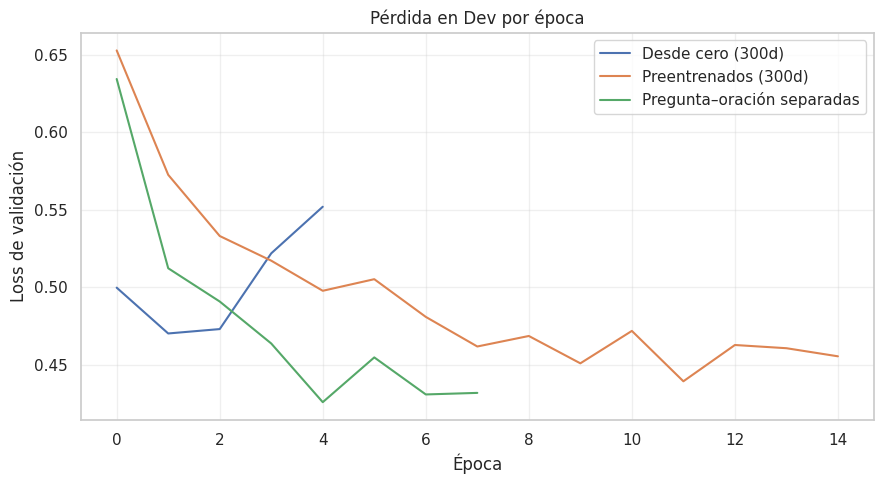

In [159]:
# Referencia de Etapa 2: Modelo 6 a umbral fijo 0.50.
# Se calculan las métricas a partir de las predicciones disponibles del código de Etapa 2,
# evitando hardcodear valores de una corrida anterior.
prob_mlp_e2_050 = np.asarray(resultado_m6["probabilidades"]).ravel()

pred_mlp_e2_050 = (prob_mlp_e2_050 >= 0.50).astype("int32")
y_mlp_e2 = np.asarray(y_dev_mlp).astype("int32").ravel()
f1_mlp_e2_050 = f1_score(y_mlp_e2, pred_mlp_e2_050, average="macro", zero_division=0)
acc_mlp_e2_050 = accuracy_score(y_mlp_e2, pred_mlp_e2_050)

resultados_modelos_e3 = [resultado_cero_300, resultado_pre_300, resultado_pareado]

filas_referencia = [
    {
        "Modelo": "Baseline TF-IDF (Etapa 1)",
        "F1-Macro Dev": 0.5633,
        "Accuracy Dev": 0.6842,
        "Tiempo (segundos)": np.nan,
        "Parámetros entrenables": np.nan
    },
    {
        "Modelo": "Mejor MLP TF-IDF (Etapa 2, umbral 0,50)",
        "F1-Macro Dev": f1_mlp_e2_050,
        "Accuracy Dev": acc_mlp_e2_050,
        "Tiempo (segundos)": np.nan,
        "Parámetros entrenables": np.nan
    }
]


# Incorporamos las dos variantes de Naive Bayes ya evaluadas.
# Sus resultados provienen de la sección 3.2.1.

filas_naive_bayes = [
    {
        "Modelo": f"{fila['Modelo']} (TF-IDF)",
        "F1-Macro Dev": fila["F1-Macro Dev"],
        "Accuracy Dev": fila["Accuracy Dev"],
        "Tiempo (segundos)": fila["Tiempo (segundos)"],
        "Parámetros entrenables": np.nan
    }
    for _, fila in tabla_naive_bayes.iterrows()
]



tabla_comparacion_e3 = pd.DataFrame(
    [filas_referencia[0]] +
    filas_naive_bayes +
    [filas_referencia[1]] +
    resultados_modelos_e3
)

tabla_comparacion_e3["Diferencia F1 vs MLP Etapa 2"] = (
    tabla_comparacion_e3["F1-Macro Dev"] - f1_mlp_e2_050
)

print("COMPARACIÓN DE MODELOS EN DEV — UMBRAL 0,50")
display(tabla_comparacion_e3.round({
    "F1-Macro Dev": 4,
    "Accuracy Dev": 4,
    "Tiempo (segundos)": 2,
    "Diferencia F1 vs MLP Etapa 2": 4
}))

mejor_resultado_e3 = max(resultados_modelos_e3, key=lambda r: r["F1-Macro Dev"])
diferencia_mejor_e3 = mejor_resultado_e3["F1-Macro Dev"] - f1_mlp_e2_050
print("\nMEJOR MODELO DE ETAPA 3 POR F1-MACRO")
print("Modelo:", mejor_resultado_e3["Modelo"])
print(f"F1-Macro Dev: {mejor_resultado_e3['F1-Macro Dev']:.4f}")
print(f"Referencia MLP Etapa 2 (umbral 0.50): {f1_mlp_e2_050:.4f}")
print(f"Diferencia vs. MLP Etapa 2: {diferencia_mejor_e3:+.4f}")
if mejor_resultado_e3["F1-Macro Dev"] > f1_mlp_e2_050:
    print("Conclusión cuantitativa: el mejor modelo de Etapa 3 supera el F1-Macro del MLP de Etapa 2 con umbral 0,50.")
else:
    print("Conclusión cuantitativa: con esta corrida, el mejor modelo de Etapa 3 no supera el F1-Macro del MLP de Etapa 2 con umbral 0,50.")

# Curvas de pérdida de validación para comparar las tres arquitecturas.
plt.figure(figsize=(9, 5))
plt.plot(historia_cero_300.history["val_loss"], label="Desde cero (300d)")
plt.plot(historia_pre_300.history["val_loss"], label="Preentrenados (300d)")
plt.plot(historia_pareado.history["val_loss"], label="Pregunta–oración separadas")
plt.title("Pérdida en Dev por época")
plt.xlabel("Época")
plt.ylabel("Loss de validación")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Experimento complementario: optimización de las longitudes de entrada

Además de la comparación principal entre arquitecturas, realizamos un experimento complementario sobre el modelo pareado para evaluar el efecto de utilizar longitudes diferenciadas para la pregunta y la oración candidata.

La configuración original utilizaba 72 posiciones para cada entrada (144 en total), mientras que la variante optimizada utilizó 19 posiciones para la pregunta y 100 para la oración (119 en total). Se conservaron el vocabulario, los embeddings preentrenados de 300 dimensiones y la arquitectura clasificadora.

La variante optimizada obtuvo un F1-Macro de **0,6425** y una accuracy de **0,8344** en Dev, frente a 0,6338 y 0,8445, respectivamente, del modelo pareado original. Esto representa una mejora de **0,0087 puntos de F1-Macro**, aunque la accuracy disminuyó en 0,0101 puntos.

En cuanto al tiempo de entrenamiento, la variante optimizada tardó **324,79 segundos**, frente a los **543,34 segundos** del modelo original. En esta ejecución se observó una reducción del tiempo, aunque la variante ejecutó 9 épocas frente a las 8 del modelo original. Como se trata de una única corrida por configuración, la diferencia temporal no puede atribuirse exclusivamente a la reducción de posiciones de entrada.

Este experimento se informa por separado porque modifica la configuración de entrada de una arquitectura ya evaluada, en lugar de introducir una nueva arquitectura. Sus resultados son exploratorios, ya que corresponden a una única ejecución y los límites de entrada fueron evaluados utilizando Dev. Por este motivo, se conserva el modelo original como referencia de la comparación principal y no se considera que la variante optimizada lo haya reemplazado.

### 3.4.1 Calibración del umbral de clasificación

En la Etapa 2 observamos que modificar el umbral de clasificación cambia el equilibrio entre falsos positivos y falsos negativos. Aplicamos el mismo procedimiento a los modelos de embeddings de la Etapa 3, utilizando exclusivamente el conjunto Dev.

La comparación principal entre arquitecturas se realiza con umbral 0,50. En esta ejecución, el modelo pareado obtuvo un F1-Macro de 0,6338, mientras que el modelo con embeddings preentrenados simples obtuvo 0,6104.

Como análisis complementario, la búsqueda de umbral alcanzó un F1-Macro de 0,6417 para el modelo pareado con umbral 0,46. Este punto de corte aumenta el recall de la clase positiva respecto de 0,50, aunque también produce más falsos positivos. Por eso, la selección del umbral depende del equilibrio entre ambos tipos de error.

El resultado calibrado es exploratorio, ya que el umbral se seleccionó utilizando Dev. La evaluación final sobre Test permanece reservada para la Etapa 5.

In [160]:
# Calibración exploratoria del umbral en Dev.
# La comparación principal entre modelos sigue siendo a umbral 0.50.
# Test permanece reservado para la Etapa 5.

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

modelos_calibrar = {
    "Embeddings preentrenados (300d)": prob_pre_300,
    "Pregunta-oración separadas (300d)": prob_pareado
}

umbrales_e3 = np.round(np.arange(0.01, 1.00, 0.01), 2)
filas_umbrales = []

for nombre_modelo, probabilidades in modelos_calibrar.items():
    for umbral in umbrales_e3:
        pred = (probabilidades >= umbral).astype("int32")

        tn, fp, fn, tp = confusion_matrix(
            y_dev_e3, pred, labels=[0, 1]
        ).ravel()

        filas_umbrales.append({
            "Modelo": nombre_modelo,
            "Umbral": float(umbral),
            "F1-Macro": f1_score(
                y_dev_e3, pred,
                average="macro",
                zero_division=0
            ),
            "Accuracy": accuracy_score(y_dev_e3, pred),
            "Precision positiva": precision_score(
                y_dev_e3, pred, zero_division=0
            ),
            "Recall positivo": recall_score(
                y_dev_e3, pred, zero_division=0
            ),
            "Falsos positivos": int(fp),
            "Falsos negativos": int(fn)
        })

tabla_umbrales_e3 = pd.DataFrame(filas_umbrales)

# Mejor umbral por modelo; se selecciona usando Dev.
indices_mejores = tabla_umbrales_e3.groupby(
    "Modelo"
)["F1-Macro"].idxmax()

print("Mejor umbral de cada modelo en Dev:")
display(
    tabla_umbrales_e3.loc[indices_mejores]
    .sort_values("F1-Macro", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

# Comparación justa a umbral fijo de 0.50.
print("Comparación de ambos modelos con umbral 0.50:")
display(
    tabla_umbrales_e3[
        np.isclose(tabla_umbrales_e3["Umbral"], 0.50)
    ]
    .round(4)
    .reset_index(drop=True)
)

Mejor umbral de cada modelo en Dev:


,Modelo,Umbral,F1-Macro,Accuracy,Precision positiva,Recall positivo,Falsos positivos,Falsos negativos
0,Pregunta-oración separadas (300d),0.46,0.6417,0.8305,0.3516,0.4174,1435,1086
1,Embeddings preentrenados (300d),0.51,0.6128,0.8258,0.3163,0.3353,1351,1239


Comparación de ambos modelos con umbral 0.50:


,Modelo,Umbral,F1-Macro,Accuracy,Precision positiva,Recall positivo,Falsos positivos,Falsos negativos
0,Embeddings preentrenados (300d),0.5,0.6104,0.8197,0.3061,0.3460,1462,1219
1,Pregunta-oración separadas (300d),0.5,0.6338,0.8445,0.3702,0.3428,1087,1225


## 3.5 Análisis de diez ejemplos difíciles

El análisis de errores permite relacionar los resultados obtenidos con las limitaciones que todavía presenta el modelo seleccionado. En las etapas anteriores identificamos falsos positivos asociados con la similitud temática y falsos negativos relacionados con paráfrasis y respuestas que dependen del contexto.

En esta sección examinamos cinco falsos positivos y cinco falsos negativos del **modelo pareado original con embeddings preentrenados**, seleccionado como mejor modelo de la comparación principal de arquitecturas de la Etapa 3. Los ejemplos se ordenan por confianza de la predicción y provienen del conjunto Dev, que se utiliza para evaluar el comportamiento del modelo y no para entrenarlo.

La variante optimizada de longitudes de entrada se informa por separado en la sección 3.3.3, por lo que no interviene en esta selección de errores.

In [161]:
# Elegimos el mejor modelo de Etapa 3 según F1-Macro en Dev.
predicciones_por_modelo = {
    resultado_cero_300["Modelo"]: (prob_cero_300, pred_cero_300),
    resultado_pre_300["Modelo"]: (prob_pre_300, pred_pre_300),
    resultado_pareado["Modelo"]: (prob_pareado, pred_pareado)
}
prob_mejor, pred_mejor = predicciones_por_modelo[mejor_resultado_e3["Modelo"]]

errores = dev_e3.reset_index(drop=True).copy()
errores["label_real"] = y_dev_e3
errores["prediccion"] = pred_mejor
errores["prob_relevante"] = prob_mejor
errores["tipo_error"] = np.select(
    [
        (errores["label_real"] == 0) & (errores["prediccion"] == 1),
        (errores["label_real"] == 1) & (errores["prediccion"] == 0)
    ],
    ["Falso positivo", "Falso negativo"],
    default="Correcto"
)

solo_errores = errores[errores["tipo_error"] != "Correcto"].copy()
falsos_positivos = solo_errores[solo_errores["tipo_error"] == "Falso positivo"].sort_values(
    "prob_relevante", ascending=False
).head(5)
falsos_negativos = solo_errores[solo_errores["tipo_error"] == "Falso negativo"].sort_values(
    "prob_relevante", ascending=True
).head(5)
muestra_10_errores = pd.concat([falsos_positivos, falsos_negativos])
# Si faltan errores de uno de los tipos para completar diez filas, rellenamos
# con otros errores de mayor confianza, sin duplicar instancias.
if len(muestra_10_errores) < min(10, len(solo_errores)):
    restantes = solo_errores.drop(index=muestra_10_errores.index, errors="ignore").copy()
    restantes["confianza_error"] = (restantes["prob_relevante"] - 0.50).abs()
    faltan = min(10, len(solo_errores)) - len(muestra_10_errores)
    adicionales = restantes.sort_values("confianza_error", ascending=False).head(faltan)
    muestra_10_errores = pd.concat([muestra_10_errores, adicionales])
muestra_10_errores = muestra_10_errores.reset_index(drop=True)

print("Modelo analizado:", mejor_resultado_e3["Modelo"])
print("Distribución total de errores en Dev:")
display(solo_errores["tipo_error"].value_counts().rename_axis("Tipo de error").to_frame("Cantidad"))

# ============================================================
# VISUALIZACIÓN HTML DE LOS DIEZ ERRORES — ETAPA 3
# Mismo estilo desplegable utilizado en la Etapa 2.
# ============================================================

filas_html_e3 = []

for numero, (_, fila) in enumerate(
    muestra_10_errores.iterrows(), start=1
):
    tipo = html.escape(str(fila["tipo_error"]))
    pregunta = html.escape(str(fila["pregunta"]))
    oracion = html.escape(str(fila["oracion"]))

    real = int(fila["label_real"])
    pred = int(fila["prediccion"])
    probabilidad = float(fila["prob_relevante"])

    clase_tipo = (
        "falso-positivo"
        if tipo == "Falso positivo"
        else "falso-negativo"
    )

    filas_html_e3.append(f"""
    <details class="caso-error-e3">
      <summary>
        <span class="numero-caso-e3">Caso {numero:02d}</span>
        <span class="tipo-error-e3 {clase_tipo}">{tipo}</span>
        <span class="etiquetas-e3">
          Real: {real} · Predicción: {pred}
        </span>
      </summary>

      <div class="contenido-caso-e3">

        <p><strong>Pregunta</strong></p>
        <div class="texto-caso-e3">{pregunta}</div>

        <p><strong>Oración candidata</strong></p>
        <div class="texto-caso-e3">{oracion}</div>

        <div class="metadatos-e3">
          <span><strong>Etiqueta real:</strong> {real}</span>
          <span><strong>Predicción:</strong> {pred}</span>
          <span>
            <strong>Probabilidad de relevancia:</strong>
            {probabilidad:.4f}
          </span>
        </div>

      </div>
    </details>
    """)


contenido_html_e3 = """
<style>
.panel-errores-e3 {
    font-family: Arial, sans-serif;
    line-height: 1.5;
    color: var(--colab-primary-text-color, #222);
}

.caso-error-e3 {
    border: 1px solid var(--colab-border-color, #ccc);
    border-radius: 9px;
    margin: 9px 0;
    overflow: hidden;
}

.caso-error-e3 summary {
    cursor: pointer;
    padding: 12px;
    background: var(--colab-secondary-surface-color, #f3f5f7);
    display: flex;
    flex-wrap: wrap;
    gap: 8px 14px;
    align-items: center;
}

.numero-caso-e3 {
    font-weight: bold;
}

.tipo-error-e3 {
    font-weight: bold;
}

.falso-positivo {
    color: #c0392b;
}

.falso-negativo {
    color: #b7791f;
}

.etiquetas-e3 {
    margin-left: auto;
    font-size: 0.92em;
}

.contenido-caso-e3 {
    padding: 14px;
}

.texto-caso-e3 {
    padding: 11px;
    border-radius: 6px;
    background: var(--colab-primary-surface-color, #fff);
    border: 1px solid var(--colab-border-color, #ddd);
    overflow-wrap: anywhere;
    white-space: normal;
}

.metadatos-e3 {
    display: flex;
    flex-wrap: wrap;
    gap: 8px 16px;
    margin: 12px 0;
    font-size: 0.9em;
}
</style>

<div class="panel-errores-e3">
<p>
<strong>Guía:</strong> abrí cada caso para leer la pregunta
y la oración completa. La probabilidad expresa la estimación
del modelo para la clase relevante.
</p>
""" + "".join(filas_html_e3) + "</div>"


print("MUESTRA DE DIEZ ERRORES — MODELO PAREADO")
print("Modelo analizado:", mejor_resultado_e3["Modelo"])

display(HTML(contenido_html_e3))

assert len(muestra_10_errores) >= min(
    10, len(solo_errores)
), "Verificar la muestra de errores generada."


Modelo analizado: Pregunta–oración por separado (preentrenados 300d)
Distribución total de errores en Dev:


,Cantidad
Tipo de error,
Falso negativo,1225
Falso positivo,1087


MUESTRA DE DIEZ ERRORES — MODELO PAREADO
Modelo analizado: Pregunta–oración por separado (preentrenados 300d)


### 3.5.1 Interpretación de los errores

El modelo pareado, evaluado con umbral 0,50, obtuvo un F1-Macro de 0,6338 en Dev. Sin embargo, registró 1.087 falsos positivos y 1.225 falsos negativos. Estos errores muestran que todavía tiene dificultades para distinguir una oración relacionada con el tema de una oración que responde efectivamente a la pregunta.

Entre los falsos positivos aparecen casos en los que hay coincidencia temática, pero la información visible no parece responder directamente a lo preguntado. Por ejemplo, una oración que menciona el título de la Sinfonía n.º 3, Op. 36, no identifica por sí sola a su compositor. Del mismo modo, una oración que indica el inicio de una campaña electoral no necesariamente informa el día de las votaciones. Estos casos ilustran la diferencia entre compartir palabras o entidades y aportar la respuesta solicitada.

Entre los falsos negativos aparecen pares cuya interpretación puede requerir más contexto. Por ejemplo, la pregunta sobre el marido de Lisa Jolstad se acompaña de una oración que menciona a Gregory Jolstad, pero la relación entre ambos no queda explícita en el fragmento mostrado. También aparecen ejemplos relacionados con la democracia en Turquía o con la canción «Aserejé», donde puede ser necesario examinar el contexto completo para determinar si la oración responde a la pregunta.

Por lo tanto, los errores deben analizarse con cautela: los fragmentos mostrados pueden estar truncados y no permiten concluir por sí solos que exista un problema de etiquetado. Cuando una respuesta parezca dudosa, será necesario revisar el ejemplo original y su contexto antes de atribuir el error exclusivamente al modelo.

En conjunto, el análisis indica que la arquitectura pareada mejora el F1-Macro respecto del MLP de la Etapa 2, pero todavía confunde similitud temática con relevancia efectiva y tiene dificultades para reconocer respuestas implícitas o formuladas de manera diferente. Estos resultados permiten identificar limitaciones concretas y orientar posibles mejoras futuras.

También se identificaron posibles limitaciones en los datos de entrada. Algunas oraciones candidatas aparecen incompletas o contienen repeticiones, como el fragmento sobre la Sinfonía n.º 3, Op. 36 y la oración que repite «las restricciones». Estos casos pueden dificultar la clasificación independientemente de la arquitectura utilizada. Por eso, los errores se interpretan considerando tanto las limitaciones del modelo como posibles problemas de segmentación o calidad textual. Para confirmar estas hipótesis sería necesario revisar los ejemplos originales y su contexto completo.

## 3.6 Conclusiones y límites

La Etapa 3 se construyó a partir de los resultados de las etapas anteriores y amplió la comparación mediante distintas estrategias de representación y clasificación de pares pregunta–oración.

En la Etapa 1, el baseline TF-IDF con Regresión Logística obtuvo un F1-Macro de **0,5633**. En la Etapa 2, el mejor MLP sobre TF-IDF alcanzó **0,5979** con umbral 0,50 (el Modelo 8, entrenado después de la selección, obtuvo 0,6004). Estos resultados mostraron que las redes neuronales densas podían mejorar la clasificación respecto del baseline inicial, aunque ambos enfoques utilizaban representaciones basadas en frecuencias de palabras.

Como experimento complementario, incorporamos Multinomial Naive Bayes y Complement Naive Bayes, también sobre características TF-IDF. MultinomialNB obtuvo un F1-Macro de **0,5776**, mientras que ComplementNB alcanzó **0,5291**. La primera variante presentó la mejor accuracy de toda la comparación (**0,8461**), pero su recall positivo fue de apenas **0,1947**. ComplementNB obtuvo un recall positivo mayor (**0,5097**), aunque con una precisión positiva de **0,1893** y un F1-Macro inferior. Estos resultados muestran que la accuracy por sí sola no permite valorar adecuadamente el desempeño en un problema con clases desbalanceadas. Por eso mantenemos el F1-Macro como métrica principal.

A partir de las limitaciones de las representaciones TF-IDF, evaluamos embeddings entrenados desde cero, embeddings preentrenados para español y una arquitectura pareada que representa por separado la pregunta y la oración candidata.

#### Comparación de modelos en Dev

| Modelo | F1-Macro | Accuracy | Tiempo (s) | Parámetros entrenables | Diferencia F1 frente al MLP de Etapa 2 |
|---|---:|---:|---:|---:|---:|
| Baseline TF-IDF (Etapa 1) | 0,5633 | 0,6842 | — | — | -0,0346 |
| MultinomialNB (TF-IDF) | 0,5776 | 0,8461 | 0,03 | — | -0,0203 |
| ComplementNB (TF-IDF) | 0,5291 | 0,6650 | 0,02 | — | -0,0689 |
| MLP TF-IDF (Etapa 2) | 0,5979 | 0,8414 | — | — | 0,0000 |
| Embeddings desde cero (300d) | 0,5909 | 0,8402 | 103,99 | 6.046.849 | -0,0070 |
| Embeddings preentrenados (300d) | 0,6104 | 0,8197 | 294,97 | 6.046.849 | +0,0125 |
| Pregunta–oración por separado (300d) | **0,6338** | 0,8445 | 543,34 | 6.162.049 | **+0,0359** |

Los tiempos informados no son directamente comparables entre todas las familias de modelos. En Naive Bayes se midieron el ajuste de los clasificadores y la predicción sobre Dev, sin incluir la construcción y transformación de las características TF-IDF. En las redes neuronales, el tiempo registrado corresponde al entrenamiento mediante `fit`, que incluye las evaluaciones de validación durante las épocas, pero no la predicción final ni la preparación previa de las entradas. Por lo tanto, estos valores se presentan como referencias del costo computacional de cada experimento y no como una medición uniforme de velocidad. Los guiones indican valores no registrados o no aplicables.

La arquitectura pareada fue el mejor modelo según el F1-Macro en la comparación con umbral fijo de 0,50. Su resultado de **0,6338** representa una mejora de **0,0359 puntos** respecto del MLP de la Etapa 2. También obtuvo una accuracy de 0,8445, superior a la del MLP de referencia (0,8414). Por otra parte, MultinomialNB alcanzó una accuracy ligeramente mayor (0,8461), pero su menor recall positivo se refleja en un F1-Macro inferior. Esto refuerza la decisión de priorizar el F1-Macro para seleccionar el modelo.

Los embeddings preentrenados simples mejoraron el F1-Macro respecto de la Etapa 2 en 0,0125 puntos, mientras que los embeddings entrenados desde cero no alcanzaron el resultado del MLP. Dentro de la **comparación principal entre arquitecturas**, el modelo pareado obtuvo el mejor desempeño, con un F1-Macro de 0,6338. Este resultado respalda la hipótesis de que representar por separado la pregunta y la oración y comparar sus vectores puede aportar información útil para la clasificación.

#### Experimento complementario: optimización de las longitudes de entrada

Además de la comparación principal, realizamos un experimento complementario sobre el modelo pareado para evaluar el efecto de utilizar longitudes diferenciadas para la pregunta y la oración candidata.

La configuración original utilizaba 72 posiciones para cada entrada (144 en total), mientras que la variante optimizada utilizó 19 posiciones para la pregunta y 100 para la oración (119 en total). Esto representa una reducción del 17,36 % en las posiciones de entrada.

En Dev, la variante optimizada obtuvo un F1-Macro de **0,6425** y una accuracy de **0,8344**, frente a 0,6338 y 0,8445, respectivamente, del modelo pareado original. Por lo tanto, presentó una mejora de **0,0087 puntos de F1-Macro**, aunque la accuracy disminuyó en 0,0101 puntos.

La reducción de posiciones coincidió con un menor tiempo de entrenamiento: la variante optimizada tardó **324,79 segundos**, frente a los **543,34 segundos** del modelo original. En esta ejecución, el tiempo disminuyó aproximadamente un 40,2 %, aunque la variante ejecutó 9 épocas frente a las 8 del modelo original. Por lo tanto, el menor tiempo se observó pese a que la variante ejecutó una época más; al contar con una única corrida por configuración, no puede atribuirse la diferencia exclusivamente a la reducción de posiciones.

Estos resultados corresponden a una única ejecución y deben interpretarse como exploratorios. Los límites de entrada se analizaron considerando la distribución de longitudes y su efecto sobre Dev, por lo que no constituyen una evaluación independiente. En consecuencia, informamos esta variante por separado y conservamos el modelo pareado original como referencia de la comparación principal.

#### Calibración del umbral

La exploración de umbrales sobre Dev encontró un F1-Macro de **0,6417** para el modelo pareado con umbral 0,46, frente a 0,6338 con umbral 0,50. Al utilizar el umbral 0,46, los falsos positivos aumentaron de 1.087 a 1.435 y los falsos negativos disminuyeron de 1.225 a 1.086. La accuracy bajó de 0,8445 a 0,8305.

Este resultado refleja el intercambio entre tipos de error: el umbral 0,46 mejora el F1-Macro, pero genera más falsos positivos. La comparación principal entre arquitecturas se mantiene a umbral 0,50; el resultado calibrado se informa por separado porque fue seleccionado mediante Dev.

#### Análisis de errores

El análisis de diez ejemplos difíciles muestra que el modelo pareado todavía confunde coincidencias temáticas con respuestas directas y que algunas respuestas requieren contexto o interpretaciones semánticas más complejas. A umbral 0,50 registró 1.087 falsos positivos y 1.225 falsos negativos.

Entre los falsos positivos aparecen casos en los que hay coincidencia temática, pero la información visible no parece responder directamente a lo preguntado. Entre los falsos negativos aparecen pares cuya interpretación puede requerir más contexto o relaciones semánticas que no están explícitas en la oración candidata. Estos ejemplos permiten identificar limitaciones tanto del modelo como de la representación de los datos mediante oraciones aisladas.

#### Conclusión general

Los experimentos muestran que distintas estrategias de representación producen resultados diferentes en la clasificación de pares pregunta–oración. Naive Bayes aporta una referencia clásica complementaria, pero no supera al MLP de la Etapa 2 en F1-Macro. Dentro de la comparación principal entre modelos neuronales, la arquitectura pareada con embeddings preentrenados obtuvo el mejor resultado, con un F1-Macro de **0,6338** y una mejora de **0,0359 puntos** respecto del MLP de la Etapa 2.

Como experimentos complementarios, la calibración del umbral del modelo pareado original elevó el F1-Macro de Dev a **0,6417** con umbral 0,46. Por otra parte, la variante con longitudes de entrada optimizadas obtuvo un F1-Macro de **0,6425** con umbral 0,50. Aunque este último fue el mayor valor observado, corresponde a una única ejecución exploratoria, presentó una accuracy inferior a la del modelo original (0,8344 frente a 0,8445) y en esta ejecución redujo el tiempo de entrenamiento (324,79 s frente a 543,34 s) pese a ejecutar una época más (9 frente a 8). Por estos motivos, no modificamos la referencia establecida para la comparación principal.

En conjunto, los resultados indican una mejora en la clasificación de pares pregunta–oración, pero permanecen limitaciones vinculadas con la relevancia efectiva, las paráfrasis, el contexto y la calidad de los fragmentos candidatos. La evaluación realizada hasta aquí se limita a Train y Dev. El conjunto Test permanece reservado para una única evaluación final en la Etapa 5.